# Stage 2 — Encoder and Temporal Predictor

**Objective:** implement the two neural-network components of the architecture, the **shared mask-conditioned encoder** $f_\theta$ and the **temporal predictor** $g_\phi$, and verify the complete forward pass: 24 hours of Azure telemetry in, a predicted latent representation of the following 6 hours out.

The architecture is adapted from LeWorldModel (Maes et al., 2026), simplified to an **action-free** model for sensor telemetry: an MLP encoder replaces the ViT, and an MLP replaces the transformer predictor.

In Stage 2 (Sections 1–6) the weights stay **randomly initialized**. Stage 3 (Section 7) adds SIGReg, the prediction loss and end-to-end training. Stage 4 (Section 8) compares Models A, B and C under historical sensor dropouts. Stage 4 (Section 8) compares Models A, B and C under historical sensor dropouts. Stage 4 (Section 8) compares Models A, B and C under historical sensor dropouts. Stage 4 (Section 8) compares Models A, B and C under historical sensor dropouts. Stage 4 (Section 8) compares Models A, B and C under historical sensor dropouts. Stage 4 (Section 8) compares Models A, B and C under historical sensor dropouts.

| Step | Task |
|---|---|
| 2.1 | Load the Azure DataLoader and verify tensor shapes |
| 2.2 | Prepare mask-conditioned encoder inputs |
| 2.3 | Implement the shared MLP encoder |
| 2.4 | Encode historical context and future target |
| 2.5 | Implement the temporal MLP predictor |
| 2.6 | Connect both components into one world model |
| 2.7 | Perform forward-pass tests and inspect results |

The reusable code lives in `src/` and is imported here; each section prints where the code it uses is defined.

| File | Contents |
|---|---|
| `src/data/azure.py` | `AzureWindowDataset` (Stage 1, Step 1.8) and `load_azure_dataset` |
| `src/models/encoder.py` | `mask_conditioned_input`, `Encoder` |
| `src/models/predictor.py` | `TemporalPredictor` |
| `src/models/world_model.py` | `TemporalWorldModel` |
| `src/models/mlp.py` | `build_mlp`, the Linear/GELU stack shared by both networks |
| `src/training/` | Stage 3: prediction loss, SIGReg, training loop, diagnostics, checkpoints |
| `src/data/corruption.py` | Stage 4: historical dropout masks, input policies, timeline schedules |
| `src/training/robust.py` | Stage 4: training of Models B and C |
| `src/evaluation/robustness.py` | Stage 4: robustness, alert and temporal-check metrics |

| Notebook section | Contents |
|---|---|
| 1. Configuration and dataset | Step 2.1 |
| 2. Mask-conditioned input preparation | Step 2.2 |
| 3. Shared encoder | Steps 2.3–2.4 |
| 4. Temporal predictor | Step 2.5 |
| 5. Integrated world model | Step 2.6 |
| 6. Forward-pass inspection | Step 2.7 |
| 7. SIGReg and End-to-End Training | Stage 3 |
| 8. Robustness experiments | Stage 4 |
| 9. Evaluation | Stage 5: `notebooks/05_final_evaluation.ipynb` |

### Setup

In [1]:
# =============================================================================
# Imports
# =============================================================================
import inspect      # Locates the reusable functions/classes in src/.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from torch.utils.data import DataLoader

# Re-import edited files under src/ automatically, so this notebook always runs the current code.
%load_ext autoreload
%autoreload 2

# =============================================================================
# Locate the project root and make src/ importable
# =============================================================================
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root (no pyproject.toml found).")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import TIME_COLUMNS, load_azure_dataset
from src.models import Encoder, TemporalPredictor, TemporalWorldModel, build_mlp, mask_conditioned_input

# =============================================================================
# Shared configuration from Stage 0
# =============================================================================
with (PROJECT_ROOT / "configs" / "base.yaml").open(encoding="utf-8") as f:
    config = yaml.safe_load(f)

data_cfg, model_cfg = config["data"], config["model"]
SENSORS = data_cfg["sensor_names"]           # ['voltage', 'rotation', 'pressure', 'vibration']
NUM_SENSORS = data_cfg["num_sensors"]        # 4
BLOCK_SIZE = data_cfg["block_size"]          # 6 hourly observations per block
CONTEXT_LENGTH = data_cfg["context_length"]  # 4 historical blocks per sample
INPUT_DIM = model_cfg["encoder_input_dim"]   # 48 = 24 values + 24 mask entries
LATENT_DIM = model_cfg["latent_dim"]         # 32
BATCH_SIZE = config["training"]["batch_size"]["azure"]  # 128
SEED = config["training"]["random_seeds"][0]            # 11: training-loader shuffle and weight initialization
assert INPUT_DIM == 2 * BLOCK_SIZE * NUM_SENSORS

PARTITIONS = ["train", "val", "test"]
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
BLOCK_LABELS = ["x_{t-3}", "x_{t-2}", "x_{t-1}", "x_t"]  # context blocks, oldest first

torch.set_printoptions(precision=3, sci_mode=False)


def show_location(obj):
    """Print where a function or class imported from src/ is defined (open that file to read the code)."""
    path = Path(inspect.getsourcefile(obj)).relative_to(PROJECT_ROOT).as_posix()
    line = inspect.getsourcelines(obj)[1]
    print(f"Using {obj.__name__} from {path}, line {line}")


def model_inputs(batch):
    """The four tensors the world model consumes, taken from a DataLoader batch."""
    return {k: batch[k] for k in ("context", "context_mask", "target", "target_mask")}


def param_table(module):
    """One row per parameter tensor: name, shape, number of values."""
    rows = [(name, tuple(p.shape), p.numel(), p.requires_grad) for name, p in module.named_parameters()]
    table = pd.DataFrame(rows, columns=["parameter", "shape", "values", "trainable"])
    return table, int(table["values"].sum())


print(f"Project root: {PROJECT_ROOT}")
print(f"torch {torch.__version__} | block {BLOCK_SIZE} h x {NUM_SENSORS} sensors | context {CONTEXT_LENGTH} blocks "
      f"| encoder {INPUT_DIM} -> {model_cfg['encoder_hidden_dims']} -> {LATENT_DIM} "
      f"| predictor {model_cfg['predictor_input_dim']} -> {model_cfg['predictor_hidden_dims']} -> {LATENT_DIM}")

Project root: C:\Users\Iman\Desktop\IAI2027 Study\SourceCode
torch 2.14.1+cpu | block 6 h x 4 sensors | context 4 blocks | encoder 48 -> [64, 64] -> 32 | predictor 128 -> [128, 64] -> 32


## 1. Configuration and dataset — Step 2.1

The processed windows from Stage 1 are reloaded from `data/processed/{train,val,test}_windows.pt` and `window_metadata.csv` into the same `AzureWindowDataset` class. The DataLoaders are configured as in Stage 1: only the training loader shuffles, with the same seeded generator, so the batch order is reproducible.

Only the training batch is needed in this stage; validation and test are loaded so the notebook is ready for Stages 3–5.

In [2]:
show_location(load_azure_dataset)

Using load_azure_dataset from src/data/azure.py, line 50


In [3]:
metadata = pd.read_csv(PROCESSED_DIR / "window_metadata.csv", parse_dates=TIME_COLUMNS)
datasets = {p: load_azure_dataset(PROCESSED_DIR, p, metadata) for p in PARTITIONS}
loaders = {
    "train": DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED)),
    "val": DataLoader(datasets["val"], batch_size=BATCH_SIZE, shuffle=False),
    "test": DataLoader(datasets["test"], batch_size=BATCH_SIZE, shuffle=False),
}
for p in PARTITIONS:
    n = len(datasets[p])
    print(f"{p:5s} {n:7,} samples -> {len(loaders[p]):4d} batches, last batch {n - (len(loaders[p]) - 1) * BATCH_SIZE} samples")

batch = next(iter(loaders["train"]))
B = len(batch["target"])

TENSOR_KEYS = ["context", "context_mask", "target", "target_mask"]
display(pd.DataFrame(
    {
        "shape": [tuple(batch[k].shape) for k in TENSOR_KEYS],
        "dtype": [str(batch[k].dtype) for k in TENSOR_KEYS],
        "min": [batch[k].min().item() for k in TENSOR_KEYS],
        "max": [batch[k].max().item() for k in TENSOR_KEYS],
        "distinct values": [batch[k].unique().numel() for k in TENSOR_KEYS],
    },
    index=TENSOR_KEYS,
).round(3))

assert B == BATCH_SIZE
assert tuple(batch["context"].shape) == tuple(batch["context_mask"].shape) == (B, CONTEXT_LENGTH, BLOCK_SIZE, NUM_SENSORS)
assert tuple(batch["target"].shape) == tuple(batch["target_mask"].shape) == (B, BLOCK_SIZE, NUM_SENSORS)
assert all(batch[k].dtype == torch.float32 for k in TENSOR_KEYS)
assert all(torch.isfinite(batch[k]).all() for k in TENSOR_KEYS)
assert (batch["context_mask"] == 1).all() and (batch["target_mask"] == 1).all()
print("Batch OK: expected shapes, float32, finite, all masks are ones.")

train 101,800 samples ->  796 batches, last batch 40 samples
val    21,500 samples ->  168 batches, last batch 124 samples
test   21,500 samples ->  168 batches, last batch 124 samples


,shape,dtype,min,max,distinct values
context,"(128, 4, 6, 4)",torch.float32,-4.674,5.127,12240
context_mask,"(128, 4, 6, 4)",torch.float32,1.000,1.000,1
target,"(128, 6, 4)",torch.float32,-3.190,5.169,3072
target_mask,"(128, 6, 4)",torch.float32,1.000,1.000,1


Batch OK: expected shapes, float32, finite, all masks are ones.


### One sample, dimension by dimension

`batch["context"][i, k, h, s]` is

| Index | Dimension | Size | Meaning |
|---|---|---|---|
| `i` | 0 | $B$ (128) | which **sample** (window) in the batch |
| `k` | 1 | 4 | which **historical block**: 0 = $x_{t-3}$ (oldest) … 3 = $x_t$ (newest) |
| `h` | 2 | 6 | which **hour within that block** |
| `s` | 3 | 4 | which **sensor**: voltage, rotation, pressure, vibration |

`batch["target"][i, h, s]` has no block dimension: it is the single block $x_{t+1}$ that follows the context. The tables below show sample 0 of the batch with every row labelled by its block, hour and timestamp. Values are standardized with the training-set scaler from Stage 1.

In [4]:
i = 0
meta = {k: (v[i].item() if torch.is_tensor(v) else v[i]) for k, v in batch["metadata"].items()}
print(meta)

context_hours = pd.date_range(meta["context_start"], periods=CONTEXT_LENGTH * BLOCK_SIZE, freq="h")
context_table = pd.DataFrame(
    batch["context"][i].reshape(-1, NUM_SENSORS).numpy(),  # [4, 6, 4] -> [24, 4]: block-major, then hour
    index=pd.MultiIndex.from_arrays(
        [np.repeat(BLOCK_LABELS, BLOCK_SIZE), np.tile(np.arange(BLOCK_SIZE), CONTEXT_LENGTH), context_hours],
        names=["block (dim 1)", "hour (dim 2)", "timestamp"]),
    columns=pd.Index(SENSORS, name="sensor (dim 3)"),
)
target_table = pd.DataFrame(
    batch["target"][i].numpy(),
    index=pd.MultiIndex.from_arrays(
        [np.arange(BLOCK_SIZE), pd.date_range(meta["target_start"], periods=BLOCK_SIZE, freq="h")],
        names=["hour (dim 1)", "timestamp"]),
    columns=pd.Index(SENSORS, name="sensor (dim 2)"),
)
print("context[0]: the 24 hours before the target")
display(context_table.round(3))
print("target[0]: the following 6 hours, x_{t+1}")
display(target_table.round(3))

k, h, s = 3, 5, SENSORS.index("vibration")
print(f"Example: context[{i}, {k}, {h}, {s}] = {batch['context'][i, k, h, s].item():.3f} -> "
      f"sample {i}, block {BLOCK_LABELS[k]}, hour {h} ({context_hours[k * BLOCK_SIZE + h]}), {SENSORS[s]}")
assert pd.Timestamp(meta["target_start"]) == context_hours[-1] + pd.Timedelta(hours=1)  # target follows directly

{'sample_id': 67720, 'machine_id': 67, 'context_start': '2015-05-14 06:00:00', 'context_end': '2015-05-15 05:00:00', 'target_start': '2015-05-15 06:00:00', 'target_end': '2015-05-15 11:00:00'}
context[0]: the 24 hours before the target


sensor (dim 3)                                  voltage  rotation  pressure  \
block (dim 1) hour (dim 2) timestamp                                          
x_{t-3}       0            2015-05-14 06:00:00    0.336    -1.412    -0.019   
              1            2015-05-14 07:00:00   -0.362     0.384    -2.137   
              2            2015-05-14 08:00:00   -0.350    -1.055     0.137   
              3            2015-05-14 09:00:00    0.351    -2.831    -1.265   
              4            2015-05-14 10:00:00    0.533    -0.910     0.972   
              5            2015-05-14 11:00:00    0.047     1.650     1.188   
x_{t-2}       0            2015-05-14 12:00:00    0.349     0.221     0.176   
              1            2015-05-14 13:00:00    0.060     2.007     0.832   
              2            2015-05-14 14:00:00   -1.146     0.199     0.063   
              3            2015-05-14 15:00:00   -1.950    -0.903    -1.096   
              4            2015-05-14 16:00:00   -1.530    -1.246     0.416   
              5            2015-05-14 17:00:00   -0.560     0.324    -0.608   
x_{t-1}       0            2015-05-14 18:00:00    0.820     0.083    -0.457   
              1            2015-05-14 19:00:00    0.646    -0.891    -0.308   
              2            2015-05-14 20:00:00   -1.098    -1.122    -1.326   
              3            2015-05-14 21:00:00   -1.146     0.263    -0.175   
              4            2015-05-14 22:00:00    0.411    -0.580    -1.475   
              5            2015-05-14 23:00:00    1.858    -1.289     0.144   
x_t           0            2015-05-15 00:00:00    0.564     0.861    -1.232   
              1            2015-05-15 01:00:00   -0.448     0.682    -0.289   
              2            2015-05-15 02:00:00    0.048     0.316     0.731   
              3            2015-05-15 03:00:00    2.287    -0.451    -0.249   
              4            2015-05-15 04:00:00   -0.505     0.534    -0.636   
              5            2015-05-15 05:00:00    0.044     0.804     0.353   

sensor (dim 3)                                  vibration  
block (dim 1) hour (dim 2) timestamp                       
x_{t-3}       0            2015-05-14 06:00:00     -0.866  
              1            2015-05-14 07:00:00     -0.302  
              2            2015-05-14 08:00:00      1.603  
              3            2015-05-14 09:00:00      1.300  
              4            2015-05-14 10:00:00     -1.700  
              5            2015-05-14 11:00:00      1.600  
x_{t-2}       0            2015-05-14 12:00:00      0.310  
              1            2015-05-14 13:00:00      0.767  
              2            2015-05-14 14:00:00     -0.119  
              3            2015-05-14 15:00:00      0.309  
              4            2015-05-14 16:00:00      0.969  
              5            2015-05-14 17:00:00      1.331  
x_{t-1}       0            2015-05-14 18:00:00     -0.164  
              1            2015-05-14 19:00:00     -1.033  
              2            2015-05-14 20:00:00      0.603  
              3            2015-05-14 21:00:00     -0.498  
              4            2015-05-14 22:00:00     -1.750  
              5            2015-05-14 23:00:00      0.107  
x_t           0            2015-05-15 00:00:00     -0.392  
              1            2015-05-15 01:00:00      0.899  
              2            2015-05-15 02:00:00     -0.078  
              3            2015-05-15 03:00:00     -1.529  
              4            2015-05-15 04:00:00     -2.142  
              5            2015-05-15 05:00:00      0.263

target[0]: the following 6 hours, x_{t+1}


,sensor (dim 2),voltage,rotation,pressure,vibration
hour (dim 1),timestamp,,,,
0,2015-05-15 06:00:00,1.811,2.137,0.567,0.885
1,2015-05-15 07:00:00,2.040,0.187,-0.714,0.265
2,2015-05-15 08:00:00,1.988,-0.096,0.377,0.764
3,2015-05-15 09:00:00,0.169,0.220,0.639,-1.156
4,2015-05-15 10:00:00,-0.128,1.280,-0.609,0.813
5,2015-05-15 11:00:00,-0.821,-0.183,-1.286,-0.483


Example: context[0, 3, 5, 3] = 0.263 -> sample 0, block x_t, hour 5 (2015-05-15 05:00:00), vibration


## 2. Mask-conditioned input preparation — Step 2.2

One 6-hour block $x_\tau\in\mathbb R^{6\times4}$ and its availability mask $m_\tau\in\{0,1\}^{6\times4}$ become one encoder input

$$u_\tau=\big[\operatorname{flat}(x_\tau\odot m_\tau),\ \operatorname{flat}(m_\tau)\big]\in\mathbb R^{48}$$

`mask = 1` means the reading was observed; `mask = 0` means it is missing, and its value is set to 0. Both halves are flattened **row-major** (hour first, then sensor), so position $4h+s$ is (hour $h$, sensor $s$) in the value half and position $24+4h+s$ is the availability of the same reading.

The concatenation of values and mask follows the explicit missingness representation of Che et al. (2018), Section 2, and is one of the baselines in their Section 3.2. GRU-D itself is **not** implemented.

The function works on any number of leading dimensions (`[6, 4]`, `[B, 6, 4]` or `[B, 4, 6, 4]`).

In [5]:
show_location(mask_conditioned_input)

Using mask_conditioned_input from src/models/encoder.py, line 8


In [6]:
x = batch["context"][0, -1]       # newest context block x_t of sample 0: [6, 4]
m = batch["context_mask"][0, -1]  # its mask: all ones
u = mask_conditioned_input(x, m)
print(f"block {tuple(x.shape)} + mask {tuple(m.shape)} -> u {tuple(u.shape)}")

# Where each reading lands in u: rows = hour, columns = (half, sensor).
columns = pd.MultiIndex.from_product([["values  u[0:24]", "mask  u[24:48]"], SENSORS])
hour_index = pd.Index(range(BLOCK_SIZE), name="hour")
positions = np.arange(INPUT_DIM).reshape(2, BLOCK_SIZE, NUM_SENSORS)  # [half, hour, sensor]
print("Position of each entry in u:")
display(pd.DataFrame(np.concatenate(positions, axis=1), index=hour_index, columns=columns))
print("Value of each entry in u:")
display(pd.DataFrame(u.reshape(2, BLOCK_SIZE, NUM_SENSORS).permute(1, 0, 2).reshape(BLOCK_SIZE, -1).numpy(),
                     index=hour_index, columns=columns).round(3))

assert u.shape == (INPUT_DIM,)
assert torch.equal(u[:24], x.flatten()) and torch.equal(u[24:], torch.ones(24))
assert all(u[hh * NUM_SENSORS + ss] == x[hh, ss] for hh in range(BLOCK_SIZE) for ss in range(NUM_SENSORS))
print("First 24 entries = sensor readings (hour-major), last 24 = mask entries in the same order.")

block (6, 4) + mask (6, 4) -> u (48,)
Position of each entry in u:


values  u[0:24]                             mask  u[24:48]           \
             voltage rotation pressure vibration        voltage rotation   
hour                                                                       
0                  0        1        2         3             24       25   
1                  4        5        6         7             28       29   
2                  8        9       10        11             32       33   
3                 12       13       14        15             36       37   
4                 16       17       18        19             40       41   
5                 20       21       22        23             44       45   

                         
     pressure vibration  
hour                     
0          26        27  
1          30        31  
2          34        35  
3          38        39  
4          42        43  
5          46        47

Value of each entry in u:


values  u[0:24]                             mask  u[24:48]           \
             voltage rotation pressure vibration        voltage rotation   
hour                                                                       
0              0.564    0.861   -1.232    -0.392            1.0      1.0   
1             -0.448    0.682   -0.289     0.899            1.0      1.0   
2              0.048    0.316    0.731    -0.078            1.0      1.0   
3              2.287   -0.451   -0.249    -1.529            1.0      1.0   
4             -0.505    0.534   -0.636    -2.142            1.0      1.0   
5              0.044    0.804    0.353     0.263            1.0      1.0   

                         
     pressure vibration  
hour                     
0         1.0       1.0  
1         1.0       1.0  
2         1.0       1.0  
3         1.0       1.0  
4         1.0       1.0  
5         1.0       1.0

First 24 entries = sensor readings (hour-major), last 24 = mask entries in the same order.


**Diagnostic: one unavailable reading.** Set the mask of one reading to 0. Its value must become 0 in the value half, its indicator must become 0 in the mask half, and all other 46 entries must stay the same. Generating realistic dropouts belongs to Stage 4; this only tests the input preparation.

In [7]:
h_drop, s_drop = 2, SENSORS.index("vibration")
m_drop = m.clone()
m_drop[h_drop, s_drop] = 0
u_drop = mask_conditioned_input(x, m_drop)

pos_value = h_drop * NUM_SENSORS + s_drop                          # 2 * 4 + 3 = 11
pos_mask = BLOCK_SIZE * NUM_SENSORS + h_drop * NUM_SENSORS + s_drop  # 24 + 11 = 35
changed = torch.nonzero(u_drop != u).flatten().tolist()
# A negative reading times 0 prints as -0.0 (IEEE negative zero); it equals 0.
display(pd.DataFrame({"u (all available)": u[changed].numpy(), "u (reading masked)": u_drop[changed].numpy()},
                     index=pd.Index(changed, name=f"changed position ({SENSORS[s_drop]}, hour {h_drop})")).round(3))

assert changed == [pos_value, pos_mask]
assert u_drop[pos_value] == 0 and u_drop[pos_mask] == 0
print(f"Only positions {pos_value} (value) and {pos_mask} (availability) changed, both to 0.")

,u (all available),u (reading masked)
"changed position (vibration, hour 2)",,
11,-0.078,-0.0
35,1.000,0.0


Only positions 11 (value) and 35 (availability) changed, both to 0.


## 3. Shared encoder — Steps 2.3 and 2.4

### Step 2.3 — The MLP encoder $z_\tau=f_\theta(u_\tau)$

| Layer | Size |
|---|---|
| Input | 48 |
| Hidden 1 | 64, GELU |
| Hidden 2 | 64, GELU |
| Output | 32 (linear) |

The output layer is **linear**: no softmax, sigmoid or unit-vector normalization. Such constraints are unnecessary for the SIGReg objective of Stage 3, which shapes the distribution of the embeddings directly. LeWorldModel (Section 3.1, Appendix D) uses a ViT with a projection head; we replace it with an MLP because each input is a small 48-value vector. The hidden widths are an initial engineering choice (`encoder_hidden_dims` in `configs/base.yaml`), not taken from LeWorldModel.

In [8]:
show_location(build_mlp)
show_location(Encoder)

Using build_mlp from src/models/mlp.py, line 4
Using Encoder from src/models/encoder.py, line 25


In [9]:
torch.manual_seed(SEED)
encoder = Encoder(INPUT_DIM, model_cfg["encoder_hidden_dims"], LATENT_DIM)
print(encoder)
enc_params, enc_total = param_table(encoder)
display(enc_params)
print(f"Encoder: {enc_total:,} trainable parameters")
assert enc_total == (48 * 64 + 64) + (64 * 64 + 64) + (64 * 32 + 32)  # 9,376

# A batch of 128 individual blocks: the newest context block x_t of every sample.
u_blocks = mask_conditioned_input(batch["context"][:, -1], batch["context_mask"][:, -1])  # [128, 48]
with torch.no_grad():
    z_blocks = encoder(u_blocks)                                                           # [128, 32]
dist = torch.pdist(z_blocks)  # Euclidean distance between every pair of embeddings
print(f"input {tuple(u_blocks.shape)} -> output {tuple(z_blocks.shape)}")
print(f"finite: {torch.isfinite(z_blocks).all().item()} | distinct embeddings: {z_blocks.unique(dim=0).shape[0]} of {B} "
      f"| pairwise distance min {dist.min():.4f}, median {dist.median():.4f} "
      f"| per-dimension std {z_blocks.std(dim=0).min():.3f}-{z_blocks.std(dim=0).max():.3f}")

assert z_blocks.shape == (B, LATENT_DIM) and torch.isfinite(z_blocks).all()
assert z_blocks.unique(dim=0).shape[0] == B

Encoder(
  (net): Sequential(
    (0): Linear(in_features=48, out_features=64, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=64, out_features=32, bias=True)
  )
)


,parameter,shape,values,trainable
0,net.0.weight,"(64, 48)",3072,True
1,net.0.bias,"(64,)",64,True
2,net.2.weight,"(64, 64)",4096,True
3,net.2.bias,"(64,)",64,True
4,net.4.weight,"(32, 64)",2048,True
5,net.4.bias,"(32,)",32,True


Encoder: 9,376 trainable parameters
input (128, 48) -> output (128, 32)
finite: True | distinct embeddings: 128 of 128 | pairwise distance min 0.1181, median 0.3677 | per-dimension std 0.027-0.068


The weights are random, so these embeddings carry no meaning about machine condition yet. The checks only show that the encoder maps any valid 48-dimensional input to a finite 32-dimensional vector, and that different blocks give different vectors.

### Step 2.4 — Encode the historical context and the future target

**A. Historical branch.** Each of the four context blocks is encoded **independently** by stacking all $B\times4$ blocks into one encoder batch. Row $4b+k$ of that batch is block $k$ of sample $b$. Reshaping back gives

$$Z_{\text{history}}=[z_{t-3},z_{t-2},z_{t-1},z_t]\in\mathbb R^{B\times4\times32}$$

**B. Target branch.** The next block is encoded with the **same** encoder and an all-ones mask, because the target is always clean: $z_{t+1}=f_\theta([x_{t+1},\mathbf 1])$.

The steps are written out below and then compared with `Encoder.encode_blocks`, the method the world model uses for both branches.

In [10]:
encoder.eval()
context, context_mask, target = batch["context"], batch["context_mask"], batch["target"]

with torch.no_grad():
    flat_values = (context * context_mask).reshape(B, CONTEXT_LENGTH, -1)
    u_history = torch.cat([flat_values, context_mask.reshape(B, CONTEXT_LENGTH, -1)], dim=-1)
    u_encoder = u_history.reshape(B * CONTEXT_LENGTH, INPUT_DIM)
    z_flat = encoder(u_encoder)
    z_history = z_flat.reshape(B, CONTEXT_LENGTH, LATENT_DIM)
    history_steps = [
        ("Historical sensor tensor", context),
        ("Flatten readings within each block", flat_values),
        ("Concatenate masked readings and masks", u_history),
        ("Reshape for shared encoder", u_encoder),
        ("Apply encoder", z_flat),
        ("Restore historical dimension", z_history),
    ]

    ones = torch.ones_like(target)  # the target is clean: all readings available
    flat_target = target.reshape(B, -1)
    u_target = torch.cat([flat_target, ones.reshape(B, -1)], dim=-1)
    z_target = encoder(u_target)
    target_steps = [
        ("Actual next sensor block", target),
        ("Flatten values", flat_target),
        ("Concatenate with all-ones mask", u_target),
        ("Apply shared encoder", z_target),
    ]

print("A. Historical branch")
display(pd.DataFrame([(op, list(t.shape)) for op, t in history_steps], columns=["operation", "shape"]))
print("B. Target branch")
display(pd.DataFrame([(op, list(t.shape)) for op, t in target_steps], columns=["operation", "shape"]))

with torch.no_grad():
    # Row 4b + k of the encoder batch is block k of sample b.
    b, k = 5, 2
    assert torch.equal(u_encoder[b * CONTEXT_LENGTH + k], mask_conditioned_input(context[b, k], context_mask[b, k]))
    assert torch.equal(z_history[b, k], z_flat[b * CONTEXT_LENGTH + k])
    # encode_blocks performs exactly these steps, for both branches.
    assert torch.equal(encoder.encode_blocks(context, context_mask), z_history)
    assert torch.equal(encoder.encode_blocks(target, ones), z_target)
    assert torch.equal(batch["target_mask"], ones)  # Stage 1 targets are clean
    # Same block, same mask, evaluation mode: identical output on repeated calls.
    z_once, z_twice = encoder.encode_blocks(target[:1], ones[:1]), encoder.encode_blocks(target[:1], ones[:1])
    assert torch.equal(z_once, z_twice)

print(f"z_history {list(z_history.shape)}, z_target {list(z_target.shape)}; "
      f"both produced by the single encoder object id={id(encoder)}")
print("Repeated encoding of the same block gives identical embeddings; encode_blocks matches the step-by-step result.")

A. Historical branch


,operation,shape
0,Historical sensor tensor,"[128, 4, 6, 4]"
1,Flatten readings within each block,"[128, 4, 24]"
2,Concatenate masked readings and masks,"[128, 4, 48]"
3,Reshape for shared encoder,"[512, 48]"
4,Apply encoder,"[512, 32]"
5,Restore historical dimension,"[128, 4, 32]"


B. Target branch


,operation,shape
0,Actual next sensor block,"[128, 6, 4]"
1,Flatten values,"[128, 24]"
2,Concatenate with all-ones mask,"[128, 48]"
3,Apply shared encoder,"[128, 32]"


z_history [128, 4, 32], z_target [128, 32]; both produced by the single encoder object id=2354585768960
Repeated encoding of the same block gives identical embeddings; encode_blocks matches the step-by-step result.


**Why one encoder.** All five blocks ($x_{t-3},\dots,x_t$ and $x_{t+1}$) are encoded with the same parameters $\theta$. Only then do the predicted $\hat z_{t+1}$ and the encoded $z_{t+1}$ live in the same representation space, so they can be compared. In Stage 3, gradients from both branches update this one encoder jointly. As in LeWorldModel, there is **no** EMA target encoder and **no** stop-gradient on the target.

## 4. Temporal predictor — Step 2.5

$$\hat z_{t+1}=g_\phi(z_{t-3},z_{t-2},z_{t-1},z_t)$$

The four historical embeddings are concatenated in chronological order, $[z_{t-3}\mid z_{t-2}\mid z_{t-1}\mid z_t]\in\mathbb R^{128}$, and passed through an MLP:

| Layer | Size |
|---|---|
| Input | 128 = 4 × 32 |
| Hidden 1 | 128, GELU |
| Hidden 2 | 64, GELU |
| Output | 32 (linear) |

**How an MLP sees temporal order.** Each time step occupies fixed input positions with its own weights, so the network can learn different relationships for recent and older blocks. Unlike a GRU, it keeps no recurrent memory. With a fixed four-block history this is a reasonable lightweight start. LeWorldModel uses a causal, action-conditioned transformer (Section 3.1, Appendix D). Using an MLP and observations only is a deliberate adaptation, not a replication.

In [11]:
show_location(TemporalPredictor)

Using TemporalPredictor from src/models/predictor.py, line 7


In [12]:
torch.manual_seed(SEED)
predictor = TemporalPredictor(CONTEXT_LENGTH, LATENT_DIM, model_cfg["predictor_hidden_dims"]).eval()
print(predictor)
pred_params, pred_total = param_table(predictor)
display(pred_params)
print(f"Predictor: {pred_total:,} trainable parameters")
assert pred_total == (128 * 128 + 128) + (128 * 64 + 64) + (64 * 32 + 32)  # 26,848

# Capture the exact tensor that enters the MLP, to check the concatenation.
captured = {}
hook = predictor.net.register_forward_hook(lambda module, inputs, output: captured.update(net_input=inputs[0]))
with torch.no_grad():
    z_pred = predictor(z_history)
hook.remove()
concat = captured["net_input"]

display(pd.DataFrame({"shape": [list(z_history.shape), list(concat.shape), list(z_pred.shape)]},
                     index=["Historical embeddings", "Concatenated history", "Predicted embedding"]))

# Chronological layout of the 128 inputs: positions 32k ... 32k + 31 hold block k.
layout = []
for k, label in enumerate(BLOCK_LABELS):
    span = slice(k * LATENT_DIM, (k + 1) * LATENT_DIM)
    assert torch.equal(concat[:, span], z_history[:, k])
    layout.append((label.replace("x", "z"), f"{span.start}-{span.stop - 1}"))
display(pd.DataFrame(layout, columns=["embedding", "predictor input positions"]))

assert concat.shape == (B, CONTEXT_LENGTH * LATENT_DIM) and z_pred.shape == (B, LATENT_DIM)
assert torch.isfinite(z_pred).all()
print("The predictor receives only the four historical embeddings, in chronological order.")

TemporalPredictor(
  (net): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=64, out_features=32, bias=True)
  )
)


,parameter,shape,values,trainable
0,net.0.weight,"(128, 128)",16384,True
1,net.0.bias,"(128,)",128,True
2,net.2.weight,"(64, 128)",8192,True
3,net.2.bias,"(64,)",64,True
4,net.4.weight,"(32, 64)",2048,True
5,net.4.bias,"(32,)",32,True


Predictor: 26,848 trainable parameters


,shape
Historical embeddings,"[128, 4, 32]"
Concatenated history,"[128, 128]"
Predicted embedding,"[128, 32]"


,embedding,predictor input positions
0,z_{t-3},0-31
1,z_{t-2},32-63
2,z_{t-1},64-95
3,z_t,96-127


The predictor receives only the four historical embeddings, in chronological order.


## 5. Integrated world model — Step 2.6

`TemporalWorldModel` owns **one** `Encoder` and **one** `TemporalPredictor`. Its forward pass:

1. receives `context`, `context_mask`, `target`, `target_mask`;
2. encodes the four historical blocks with the shared encoder → `z_history [B, 4, 32]`;
3. concatenates them chronologically and applies the predictor → `z_pred [B, 32]`;
4. encodes the actual future block with the **same** encoder → `z_target [B, 32]`;
5. returns all three.

| Output | Shape | Purpose |
|---|---|---|
| `z_history` | `[B, 4, 32]` | Historical latent states (SIGReg in Stage 3) |
| `z_pred` | `[B, 32]` | Predicted future latent state |
| `z_target` | `[B, 32]` | Actual future latent state |

In Stage 3 these feed $\mathcal L_{\text{pred}}=\frac1B\sum_i\lVert\hat z^{(i)}_{t+1}-z^{(i)}_{t+1}\rVert_2^2$ and SIGReg. The losses are kept **outside** the model, so the forward pass stays separate from the training procedure.

Design decisions: the target branch uses the same trainable encoder, not a frozen copy. The predictor sees only historical embeddings. There is no reconstruction decoder, no failure-classification head, no action input (the dataset has no control actions), and no stop-gradient or EMA teacher.

In [13]:
show_location(TemporalWorldModel)

Using TemporalWorldModel from src/models/world_model.py, line 8


In [14]:
torch.manual_seed(SEED)
model = TemporalWorldModel.from_config(config).eval()
print(model)
_, model_total = param_table(model)
_, model_enc_total = param_table(model.encoder)
_, model_pred_total = param_table(model.predictor)
display(pd.DataFrame({"trainable parameters": [model_enc_total, model_pred_total, model_total]},
                     index=["encoder f_theta", "predictor g_phi", "total"]))
assert model_total == model_enc_total + model_pred_total == enc_total + pred_total  # one encoder, one predictor

with torch.no_grad():
    out = model(**model_inputs(batch))
    # The forward pass equals the composition of its parts.
    z_history_parts = model.encode_history(batch["context"], batch["context_mask"])
    assert torch.equal(out["z_history"], z_history_parts)
    assert torch.equal(out["z_pred"], model.predictor(z_history_parts))
    assert torch.equal(out["z_target"], model.encode_target(batch["target"], batch["target_mask"]))

display(pd.DataFrame(
    {"shape": [list(out[k].shape) for k in out], "finite": [torch.isfinite(out[k]).all().item() for k in out],
     "mean": [out[k].mean().item() for k in out], "std": [out[k].std().item() for k in out]},
    index=list(out),
).round(3))

TemporalWorldModel(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=48, out_features=64, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): GELU(approximate='none')
      (4): Linear(in_features=64, out_features=32, bias=True)
    )
  )
  (predictor): TemporalPredictor(
    (net): Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): Linear(in_features=128, out_features=64, bias=True)
      (3): GELU(approximate='none')
      (4): Linear(in_features=64, out_features=32, bias=True)
    )
  )
)


,trainable parameters
encoder f_theta,9376
predictor g_phi,26848
total,36224


,shape,finite,mean,std
z_history,"[128, 4, 32]",True,-0.006,0.109
z_pred,"[128, 32]",True,-0.010,0.079
z_target,"[128, 32]",True,-0.005,0.107


## 6. Forward-pass inspection — Step 2.7

Five tests check that the encoder and predictor are connected correctly before any optimization. The size of the prediction error is **not** judged here, because the model is untrained.

### Test A — Shape verification

Forward hooks record the tensors that actually enter and leave the encoder and the predictor MLP during one `model(...)` call. The shapes are therefore observed inside the real forward pass, not recomputed.

In [15]:
calls = []


def record(name):
    def hook(module, inputs, output):
        calls.append({"module": name, "object id": id(module), "input": list(inputs[0].shape), "output": list(output.shape)})
    return hook


handles = [model.encoder.register_forward_hook(record("encoder")),
           model.predictor.net.register_forward_hook(record("predictor MLP"))]
with torch.no_grad():
    out = model(**model_inputs(batch))
for handle in handles:
    handle.remove()

print("Calls during one forward pass, in order:")
display(pd.DataFrame(calls))

shape_checks = pd.DataFrame(
    [
        ("Historical inputs", [B, CONTEXT_LENGTH, BLOCK_SIZE, NUM_SENSORS], list(batch["context"].shape)),
        ("Encoder-ready history", [B * CONTEXT_LENGTH, INPUT_DIM], calls[0]["input"]),
        ("Historical encoded states", [B, CONTEXT_LENGTH, LATENT_DIM], list(out["z_history"].shape)),
        ("Predictor input", [B, CONTEXT_LENGTH * LATENT_DIM], calls[1]["input"]),
        ("Predicted future state", [B, LATENT_DIM], list(out["z_pred"].shape)),
        ("Encoder-ready target", [B, INPUT_DIM], calls[2]["input"]),
        ("Encoded target state", [B, LATENT_DIM], list(out["z_target"].shape)),
    ],
    columns=["operation", "expected", "observed"],
)
shape_checks["match"] = shape_checks["expected"] == shape_checks["observed"]
display(shape_checks)
assert [c["module"] for c in calls] == ["encoder", "predictor MLP", "encoder"]
assert shape_checks["match"].all()
test_a = True

Calls during one forward pass, in order:


,module,object id,input,output
0,encoder,2353831000528,"[512, 48]","[512, 32]"
1,predictor MLP,2354520527696,"[128, 128]","[128, 32]"
2,encoder,2353831000528,"[128, 48]","[128, 32]"


,operation,expected,observed,match
0,Historical inputs,"[128, 4, 6, 4]","[128, 4, 6, 4]",True
1,Encoder-ready history,"[512, 48]","[512, 48]",True
2,Historical encoded states,"[128, 4, 32]","[128, 4, 32]",True
3,Predictor input,"[128, 128]","[128, 128]",True
4,Predicted future state,"[128, 32]","[128, 32]",True
5,Encoder-ready target,"[128, 48]","[128, 48]",True
6,Encoded target state,"[128, 32]","[128, 32]",True


### Test B — Parameter sharing

The model must contain exactly one encoder, and both branches must call that object. As a functional check, the target block is also placed in the newest **history** slot. In evaluation mode, the history branch and the target branch must then produce the same embedding for it.

In [16]:
n_encoders = sum(isinstance(module, Encoder) for module in model.modules())
encoder_call_ids = {c["object id"] for c in calls if c["module"] == "encoder"}

context_swap, mask_swap = batch["context"].clone(), batch["context_mask"].clone()
context_swap[:, -1], mask_swap[:, -1] = batch["target"], batch["target_mask"]  # target block as x_t
with torch.no_grad():
    z_via_history = model.encode_history(context_swap, mask_swap)[:, -1]
    z_via_target = model.encode_target(batch["target"], batch["target_mask"])
max_diff = (z_via_history - z_via_target).abs().max().item()

print(f"Encoder modules in the model: {n_encoders}")
print(f"Distinct encoder objects called in Test A: {len(encoder_call_ids)} (id {encoder_call_ids} = model.encoder {id(model.encoder)})")
print(f"Same block via history branch vs target branch: max |difference| = {max_diff:.2e}")
assert n_encoders == 1 and encoder_call_ids == {id(model.encoder)}
assert torch.allclose(z_via_history, z_via_target, atol=1e-6)
test_b = True

Encoder modules in the model: 1
Distinct encoder objects called in Test A: 1 (id {2353831000528} = model.encoder 2353831000528)
Same block via history branch vs target branch: max |difference| = 0.00e+00


### Test C — Mask behavior

One observation is fed twice: once with every reading available, and once with one reading masked. The two encoder inputs must differ in exactly two places: the masked reading (now 0) and its availability indicator (now 0).

The embeddings are compared as well, but a difference here only shows that the encoder *receives* the mask. Whether it uses that information sensibly has to be learned in training and evaluated in Stage 4.

In [17]:
x_obs = batch["context"][0, -1]
m_full = torch.ones_like(x_obs)
m_masked = m_full.clone()
m_masked[h_drop, s_drop] = 0
u_full, u_masked = mask_conditioned_input(x_obs, m_full), mask_conditioned_input(x_obs, m_masked)
differing = torch.nonzero(u_full != u_masked).flatten().tolist()

with torch.no_grad():
    z_full, z_masked = model.encoder(torch.stack([u_full, u_masked]))
z_distance = (z_full - z_masked).norm().item()
typical = torch.pdist(out["z_history"][:, -1]).median().item()  # between different samples' x_t

print(f"Masked reading: {SENSORS[s_drop]}, hour {h_drop} of block x_t")
print(f"Input positions that differ: {differing} -> measurement channel {differing[0]}, availability channel {differing[1]}")
print(f"Embedding distance full vs masked: {z_distance:.4f} (median distance between different samples: {typical:.4f})")
assert differing == [pos_value, pos_mask]
assert u_masked[pos_value] == 0 and u_masked[pos_mask] == 0 and u_full[pos_mask] == 1
test_c = True

Masked reading: vibration, hour 2 of block x_t
Input positions that differ: [11, 35] -> measurement channel 11, availability channel 35
Embedding distance full vs masked: 0.0576 (median distance between different samples: 0.3677)


### Test D — Causality and target leakage

Replacing **only** the future target must leave `z_pred` (and `z_history`) unchanged; `z_target` is expected to change. A gradient check confirms it structurally: $\partial \hat z_{t+1}/\partial x_{t+1}$ does not exist (no computational path), while every historical block does influence $\hat z_{t+1}$. This computes input sensitivities only; no parameter is updated.

In [18]:
torch.manual_seed(SEED)
inputs = model_inputs(batch)
altered = {**inputs, "target": torch.randn_like(inputs["target"])}  # a completely different future
with torch.no_grad():
    out_ref, out_alt = model(**inputs), model(**altered)

leak_table = pd.DataFrame(
    {"max |change|": [(out_alt[k] - out_ref[k]).abs().max().item() for k in out_ref]}, index=list(out_ref))
display(leak_table)
assert torch.equal(out_alt["z_pred"], out_ref["z_pred"]) and torch.equal(out_alt["z_history"], out_ref["z_history"])
assert not torch.allclose(out_alt["z_target"], out_ref["z_target"])

# Control: changing the history does change the prediction, so the test above is not vacuous.
with torch.no_grad():
    out_ctx = model(**{**inputs, "context": torch.randn_like(inputs["context"])})
assert not torch.allclose(out_ctx["z_pred"], out_ref["z_pred"])

# Gradient check: which inputs can influence z_pred?
context_req = inputs["context"].clone().requires_grad_()
target_req = inputs["target"].clone().requires_grad_()
out_grad = model(context_req, inputs["context_mask"], target_req, inputs["target_mask"])
grad_context, grad_target = torch.autograd.grad(out_grad["z_pred"].sum(), [context_req, target_req], allow_unused=True)
per_block = grad_context.abs().sum(dim=(0, 2, 3))
print(f"d z_pred / d target: {grad_target}  (None = no computational path from the target)")
print("sum |d z_pred / d context| per block: " + ", ".join(f"{l} {g:.3f}" for l, g in zip(BLOCK_LABELS, per_block.tolist())))
assert grad_target is None and (per_block > 0).all()
test_d = True

,max |change|
z_history,0.000000
z_pred,0.000000
z_target,0.265888


d z_pred / d target: None  (None = no computational path from the target)
sum |d z_pred / d context| per block: x_{t-3} 4.082, x_{t-2} 4.556, x_{t-1} 3.562, x_t 3.361


### Test E — Numerical integrity

- All outputs are finite, in evaluation and in training mode.
- Encoder and predictor have trainable parameters.
- In training mode the outputs carry a `grad_fn`, so Stage 3 can backpropagate through them.
- Small batches work: 1 sample, 7 samples, and the size of the final training batch. Each row of a small batch matches the same row of the full batch, so a sample's output does not depend on the other samples in its batch. There is no batch normalization.

In [19]:
integrity = {}
integrity["encoder trainable parameters"] = sum(p.numel() for p in model.encoder.parameters() if p.requires_grad)
integrity["predictor trainable parameters"] = sum(p.numel() for p in model.predictor.parameters() if p.requires_grad)

model.train()
out_train = model(**model_inputs(batch))
integrity["train mode: outputs finite"] = all(torch.isfinite(v).all().item() for v in out_train.values())
integrity["train mode: outputs track gradients"] = all(v.requires_grad and v.grad_fn is not None for v in out_train.values())
integrity["train mode: grad_fn of z_pred"] = type(out_train["z_pred"].grad_fn).__name__
model.eval()

with torch.no_grad():
    out_eval = model(**model_inputs(batch))
integrity["eval mode: outputs finite"] = all(torch.isfinite(v).all().item() for v in out_eval.values())
integrity["eval mode under no_grad: tracking off"] = not any(v.requires_grad for v in out_eval.values())
integrity["train and eval outputs equal (no dropout/batch norm)"] = all(
    torch.allclose(out_train[k].detach(), out_eval[k]) for k in out_eval)

last_batch_size = len(datasets["train"]) % BATCH_SIZE or BATCH_SIZE  # final training batch: 40 samples
for n in [1, 7, last_batch_size]:
    small = {k: v[:n] for k, v in model_inputs(batch).items()}
    with torch.no_grad():
        out_small = model(**small)
    shapes_ok = [list(v.shape) for v in out_small.values()] == [[n, CONTEXT_LENGTH, LATENT_DIM], [n, LATENT_DIM], [n, LATENT_DIM]]
    rows_ok = all(torch.allclose(out_small[k], out_eval[k][:n], atol=1e-6) for k in out_small)
    integrity[f"batch of {n}: shapes correct, finite, rows match full batch"] = (
        shapes_ok and rows_ok and all(torch.isfinite(v).all().item() for v in out_small.values()))

display(pd.DataFrame({"result": integrity}))
assert integrity["encoder trainable parameters"] > 0 and integrity["predictor trainable parameters"] > 0
assert all(v for v in integrity.values() if isinstance(v, bool))
test_e = True

,result
encoder trainable parameters,9376
predictor trainable parameters,26848
train mode: outputs finite,True
train mode: outputs track gradients,True
train mode: grad_fn of z_pred,AddmmBackward0
eval mode: outputs finite,True
eval mode under no_grad: tracking off,True
train and eval outputs equal (no dropout/batch norm),True
"batch of 1: shapes correct, finite, rows match full batch",True
"batch of 7: shapes correct, finite, rows match full batch",True


### Stage 2 completion checklist

Each item is re-evaluated from the objects built above.

In [20]:
results = []


def check(name, condition):
    results.append((name, bool(condition)))
    print(f"[{'PASS' if condition else 'FAIL'}] {name}")


with torch.no_grad():
    final = model(**model_inputs(batch))

check("Azure training batch loads successfully",
      tuple(batch["context"].shape) == (BATCH_SIZE, CONTEXT_LENGTH, BLOCK_SIZE, NUM_SENSORS)
      and all(batch[k].dtype == torch.float32 for k in TENSOR_KEYS))
check("Each 6-hour sensor block is converted to 48 input features",
      mask_conditioned_input(batch["context"], batch["context_mask"]).shape == (B, CONTEXT_LENGTH, INPUT_DIM))
check("Mask-conditioned MLP encoder is implemented",
      isinstance(model.encoder, Encoder) and model.encoder.net[0].in_features == INPUT_DIM)
check("Encoder produces 32-dimensional latent vectors", model.encoder(u_blocks).shape == (B, LATENT_DIM))
check("Four historical blocks are encoded using shared weights",
      final["z_history"].shape == (B, CONTEXT_LENGTH, LATENT_DIM) and n_encoders == 1 and test_b)
check("Clean future target uses the same encoder",
      final["z_target"].shape == (B, LATENT_DIM) and (batch["target_mask"] == 1).all() and encoder_call_ids == {id(model.encoder)})
check("Temporal MLP predictor is implemented", isinstance(model.predictor, TemporalPredictor))
check("Predictor accepts 128 features and outputs 32",
      model.predictor.net[0].in_features == CONTEXT_LENGTH * LATENT_DIM and model.predictor.net[-1].out_features == LATENT_DIM)
check("Integrated model returns z_history, z_pred and z_target", list(final) == ["z_history", "z_pred", "z_target"])
check("All tensor shapes and values pass validation", test_a and test_e and all(torch.isfinite(v).all() for v in final.values()))
check("Changing the target does not affect the predicted embedding", test_d)
check("Reusable model classes are saved in the project",
      all((PROJECT_ROOT / "src" / "models" / f).exists() for f in ["encoder.py", "predictor.py", "world_model.py"])
      and TemporalWorldModel.__module__ == "src.models.world_model")

print(f"\n{sum(ok for _, ok in results)}/{len(results)} checks passed")
assert all(ok for _, ok in results), [name for name, ok in results if not ok]

[PASS] Azure training batch loads successfully
[PASS] Each 6-hour sensor block is converted to 48 input features
[PASS] Mask-conditioned MLP encoder is implemented
[PASS] Encoder produces 32-dimensional latent vectors
[PASS] Four historical blocks are encoded using shared weights
[PASS] Clean future target uses the same encoder
[PASS] Temporal MLP predictor is implemented
[PASS] Predictor accepts 128 features and outputs 32
[PASS] Integrated model returns z_history, z_pred and z_target
[PASS] All tensor shapes and values pass validation
[PASS] Changing the target does not affect the predicted embedding
[PASS] Reusable model classes are saved in the project

12/12 checks passed


## Stage 2 complete

The path from data to prediction, for one sample:

1. **Context.** 24 hours of standardized telemetry form four blocks $x_{t-3},\dots,x_t$, each `[6, 4]`, with masks of the same shape.
2. **Input preparation.** Each block becomes $u_\tau=[\operatorname{flat}(x_\tau\odot m_\tau),\operatorname{flat}(m_\tau)]$, 48 values, hour-major.
3. **Encoder.** One shared MLP $f_\theta$ (48 → 64 → 64 → 32, 9,376 parameters) encodes every block independently: `[B·4, 48] → [B·4, 32]`, reshaped to `z_history [B, 4, 32]`.
4. **Predictor.** The four latents are concatenated oldest first to `[B, 128]`, and $g_\phi$ (128 → 128 → 64 → 32, 26,848 parameters) outputs `z_pred [B, 32]`.
5. **Target.** The following block $x_{t+1}$, with an all-ones mask, goes through the **same** $f_\theta$ to give `z_target [B, 32]`. It never reaches the predictor (Test D).

The weights are still random, so `z_pred` does not yet predict anything meaningful.

# Stage 3 — SIGReg and End-to-End Training

## 7. SIGReg and End-to-End Training

**Objective:** train the Stage 2 encoder and temporal predictor **jointly** on clean Azure telemetry with the LeWorldModel objective

$$\mathcal L=\mathcal L_{\text{pred}}+\lambda\,\operatorname{SIGReg}(Z),\qquad \lambda=0.1,$$

and obtain a reproducible **Model A** (standard temporal LeWorldModel), the reference model for Stage 4.

Model A sees clean windows with all-ones masks. This stage uses no artificial corruption, no failure or maintenance labels, and **no test partition**: training uses `train`, and checkpoint selection uses `val`. The Stage 2 architecture is unchanged: one shared encoder and no target encoder, EMA teacher or stop-gradient.

| Subsection | Contents |
|---|---|
| 7.1 | Training configuration |
| 7.2 | Prediction loss |
| 7.3 | SIGReg implementation and tests |
| 7.4 | Combined objective |
| 7.5 | Gradient verification |
| 7.6 | Training loop: sanity test, benchmark, full training |
| 7.7 | Validation and checkpoint selection |
| 7.8 | Representation diagnostics |
| 7.9 | Persistence baseline |
| 7.10 | Results and Stage 3 completion checks |

The reusable code is in `src/training/`: `losses.py` (prediction loss, SIGReg, combined objective), `diagnostics.py` (latent statistics, effective rank, collapse checks, gradient norms), and `trainer.py` (training loop, validation, checkpoints).

### 7.1 Training configuration

All hyperparameters come from `configs/base.yaml`. The non-collapse criteria used for checkpoint selection were fixed there **before** training: effective rank ≥ 16 of 32, and every latent dimension with standard deviation ≥ 0.1.

Diagnostics use one fixed set of validation windows, evenly spaced through the validation partition, so all machines and times are covered. A few held-out windows are tracked individually.

In [21]:
import copy
import json
import math
import subprocess
import tempfile
import textwrap
import time

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from torch.utils.data import Subset

from src.training import (LOSS_KEYS, SIGReg, build_model, build_sigreg, encode_windows, fit, grad_norm,
                          hyperparameters, latent_statistics, load_checkpoint, noncollapse_checks, prediction_loss,
                          select_device, stack_embeddings, to_device, train_one_epoch, world_model_loss)

train_cfg = config["training"]
SIGREG_CFG, DIAG_CFG = train_cfg["sigreg"], train_cfg["diagnostics"]
SEEDS = train_cfg["random_seeds"]       # [11, 22, 33]
LAMBDA = train_cfg["sigreg_weight"]     # 0.1
DEVICE = select_device(train_cfg["device"])
RETRAIN = False  # True: train again even if a checkpoint for a seed already exists

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
for path in (CHECKPOINT_DIR, RESULTS_DIR, FIGURES_DIR):
    path.mkdir(parents=True, exist_ok=True)
checkpoint_path = {seed: CHECKPOINT_DIR / f"model_a_best_seed{seed}.pt" for seed in SEEDS}


def rel(path):
    """A path relative to the project root, for printing and for the summary file."""
    try:
        return path.relative_to(PROJECT_ROOT).as_posix()
    except ValueError:
        return str(path)


# Fixed validation windows for the diagnostics, evenly spaced through the partition.
n_val = len(datasets["val"])
DIAG_INDICES = np.linspace(0, n_val - 1, DIAG_CFG["subset_size"]).round().astype(int).tolist()
TRACKED_INDICES = np.linspace(0, n_val - 1, DIAG_CFG["tracked_windows"] + 2).round().astype(int)[1:-1].tolist()
tracked_meta = pd.DataFrame([datasets["val"][i]["metadata"] for i in TRACKED_INDICES]).astype({"sample_id": int, "machine_id": int})
tracked_meta.insert(0, "val index", TRACKED_INDICES)

# Figures: Stage 1 axis styling; one fixed colour per seed in every Stage 3 figure.
SEED_COLORS = dict(zip(SEEDS, ["#2a78d6", "#eb6834", "#1baf7a"]))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

display(pd.Series(hyperparameters(config, DEVICE), name="value").to_frame())
print(f"Diagnostics subset: {len(DIAG_INDICES)} of {n_val:,} validation windows. Tracked held-out windows:")
display(tracked_meta[["val index", "sample_id", "machine_id", "target_start", "target_end"]])

,value
optimizer,Adam
learning_rate,0.001
batch_size,128
max_epochs,30
sigreg_weight,0.1
sigreg_num_proj,1024
sigreg_knots,17
sigreg_t_max,3.0
sigreg_val_projection_seed,2027
diagnostics_subset_size,4096


Diagnostics subset: 4096 of 21,500 validation windows. Tracked held-out windows:


,val index,sample_id,machine_id,target_start,target_end
0,3071,104871,15,2015-09-30 00:00:00,2015-09-30 05:00:00
1,6143,107943,29,2015-10-15 12:00:00,2015-10-15 17:00:00
2,9214,111014,43,2015-10-30 18:00:00,2015-10-30 23:00:00
3,12285,114085,58,2015-09-22 06:00:00,2015-09-22 11:00:00
4,15356,117156,72,2015-10-07 12:00:00,2015-10-07 17:00:00
5,18428,120228,86,2015-10-23 00:00:00,2015-10-23 05:00:00


### 7.2 Prediction loss

$$\mathcal L_{\text{pred}}=\frac{1}{B\cdot 32}\sum_{i=1}^{B}\big\lVert\hat z^{(i)}_{t+1}-z^{(i)}_{t+1}\big\rVert_2^2$$

This is the **mean** over the batch and all 32 latent dimensions, as in LeWorldModel's `(pred_emb - tgt_emb).pow(2).mean()`. It is 1/32 of the per-sample sum written in Step 2.6. `z_target` is **not** detached, so the target branch trains the shared encoder too.

The checks use a freshly initialized model in training mode and one training batch.

In [22]:
show_location(prediction_loss)

probe = build_model(config, SEED, DEVICE).train()
inputs = to_device(batch, DEVICE)
out = model_out = probe(**inputs)
out["z_target"].retain_grad()
loss_pred = prediction_loss(out["z_pred"], out["z_target"])
loss_pred.backward()

manual = ((out["z_pred"] - out["z_target"]) ** 2).sum() / (B * LATENT_DIM)
pred_checks = {
    "inputs z_pred / z_target": f"{list(out['z_pred'].shape)} / {list(out['z_target'].shape)}",
    "output shape (scalar)": list(loss_pred.shape),
    "value": round(loss_pred.item(), 6),
    "equals sum / (B * 32)": torch.allclose(loss_pred, manual),
    "finite": torch.isfinite(loss_pred).item(),
    "differentiable (grad_fn)": type(loss_pred.grad_fn).__name__,
    "z_target not detached (receives gradient)": out["z_target"].grad is not None and out["z_target"].grad.abs().sum().item() > 0,
    "encoder gradient norm": grad_norm(probe.encoder),
    "predictor gradient norm": grad_norm(probe.predictor),
}
display(pd.Series(pred_checks, name="prediction loss").to_frame())
try:
    prediction_loss(out["z_pred"], out["z_target"][:, :16])
    raise AssertionError("shape mismatch was not detected")
except ValueError as err:
    print(f"Shape check: {err}")

assert loss_pred.dim() == 0 and pred_checks["equals sum / (B * 32)"] and pred_checks["finite"]
assert pred_checks["z_target not detached (receives gradient)"]
assert pred_checks["encoder gradient norm"] > 0 and pred_checks["predictor gradient norm"] > 0
probe.zero_grad(set_to_none=True)

Using prediction_loss from src/training/losses.py, line 8


,prediction loss
inputs z_pred / z_target,"[128, 32] / [128, 32]"
output shape (scalar),[]
value,0.019304
equals sum / (B * 32),True
finite,True
differentiable (grad_fn),MeanBackward0
z_target not detached (receives gradient),True
encoder gradient norm,0.074118
predictor gradient norm,0.050237


Shape check: z_pred (128, 32) and z_target (128, 16) must have the same shape


### 7.3 SIGReg implementation and tests

SIGReg (LeWorldModel Eq. 2 and Appendix A; LeJEPA Section 4.2.3) pushes the distribution of the embeddings towards an isotropic Gaussian $\mathcal N(0,I)$. It does this **without** comparing moments: it compares **characteristic functions** along random one-dimensional projections. By the Cramér–Wold theorem, matching every 1D marginal matches the full distribution.

For embeddings $Z\in\mathbb R^{N\times32}$ at one temporal position and a random unit direction $a_m$ (Gaussian vector, normalized), the projections are $h=Za_m$, and

$$\operatorname{EP}(h)=N\int_{-\infty}^{\infty}w(t)\,\big|\phi_N(t)-\phi_0(t)\big|^2\,dt,\qquad \phi_N(t)=\frac1N\sum_{n=1}^{N}e^{\,i t h_n},\quad \phi_0(t)=e^{-t^2/2},\quad w(t)=e^{-t^2/2}.$$

$|\phi_N-\phi_0|^2=(\overline{\cos th}-\phi_0)^2+(\overline{\sin th})^2$ is even in $t$. The integral is therefore evaluated as $2\int_0^{3}$ with the **trapezoid rule on 17 nodes**: interior weights $2\Delta t$, endpoint weights $\Delta t$, with $\Delta t=3/16$, each multiplied by $w(t_k)$. Then

$$\operatorname{SIGReg}=\frac{1}{5}\sum_{\text{positions }p}\ \frac1M\sum_{m=1}^{M}\operatorname{EP}\big(Z_p\,a_m\big),\qquad M=1024,$$

computed **independently for each of the five positions** $z_{t-3},\dots,z_t,z_{t+1}$ on a `[5, B, 32]` tensor, then averaged. This is the official LeWorldModel `module.SIGReg` (knots = 17, `num_proj` = 1024) and its call `sigreg(emb.transpose(0, 1))`.

**Statistical scaling.** Under $H_0$ (an exactly Gaussian batch), $\mathbb E\,N|\phi_N(t)-\phi_0(t)|^2=1-e^{-t^2}$, so

$$\mathbb E_{H_0}[\operatorname{EP}]=\int w(t)\,(1-e^{-t^2})\,dt=\sqrt{2\pi}-\sqrt{2\pi/3}\approx1.059$$

for **every** batch size. The factor $N$ makes the statistic a calibrated test statistic: about 1 means "indistinguishable from Gaussian at this sample size", while any fixed deviation grows ∝ $N$. A perfect Gaussian batch therefore does **not** reach 0; ≈ 1.05 is the floor. There is no centring, so a non-zero mean is penalized as well.

**Relation to the CIRP implementation** (`CIRP Conference Study/application/lejepa_engine/training.py`, `sigreg`):

| | CIRP `sigreg` | LeWorldModel / this notebook |
|---|---|---|
| Centring | subtracts the batch mean | none (the mean is part of the target) |
| $t$ nodes | 17 on $[-3, 3]$, plain average | 17 on $[0, 3]$, trapezoid × 2 by symmetry |
| Weight $w(t)$ | none (uniform) | $e^{-t^2/2}$ |
| Scaling | none: $\overline{\lvert\phi_N-\phi_0\rvert^2}$ | $N\times$ weighted integral (Epps–Pulley) |
| Projections | 64 | 1024 |
| λ used with it | 1.0 | 0.1 |

Both implementations use the same empirical-characteristic-function comparison. The CIRP version is an unscaled, unweighted variant, so its values are roughly $N$ times smaller (compare the CIRP column in the diagnostic table below). $\lambda=0.1$ belongs to the LeWorldModel scaling, which is the one implemented here.

In [23]:
show_location(SIGReg)
sigreg = build_sigreg(config, DEVICE)
print(sigreg.settings())
display(pd.DataFrame({"t": sigreg.t.cpu(), "phi_0(t) = w(t)": sigreg.phi.cpu(),
                      "trapezoid weight": (sigreg.weights / sigreg.phi).cpu(), "weight x w(t)": sigreg.weights.cpu()}
                     ).round(4).T)

Using SIGReg from src/training/losses.py, line 18
{'num_proj': 1024, 'knots': 17, 't_max': 3.0, 'integration': 'trapezoid on [0, t_max], doubled by symmetry', 'weight': 'exp(-t^2/2)', 'scaling': 'N * weighted integral, mean over projections and time positions'}


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
t,0.0000,0.1875,0.3750,0.5625,0.7500,0.9375,1.1250,1.3125,1.5000,1.6875,1.8750,2.0625,2.2500,2.4375,2.6250,2.8125,3.0000
phi_0(t) = w(t),1.0000,0.9826,0.9321,0.8537,0.7548,0.6444,0.5311,0.4226,0.3247,0.2408,0.1724,0.1192,0.0796,0.0513,0.0319,0.0192,0.0111
trapezoid weight,0.1875,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.3750,0.1875
weight x w(t),0.1875,0.3685,0.3495,0.3201,0.2831,0.2416,0.1992,0.1585,0.1217,0.0903,0.0647,0.0447,0.0298,0.0192,0.0120,0.0072,0.0021


**Tests 1–3: directions, characteristic function, integration.**

1. The directions are Gaussian vectors normalized to unit length.
2. `phi` is exactly the $\mathcal N(0,1)$ characteristic function, and the empirical characteristic function of a large $\mathcal N(0,1)$ sample converges to it.
3. The quadrature is compared with closed-form integrals. A 2,001-node rule on the same $[0,3]$ range separates the **discretization** error from the **truncation** error, which comes from stopping at $t=3$.

In [24]:
gen = torch.Generator().manual_seed(0)

# 1. Unit-length directions
directions = sigreg.sample_directions(LATENT_DIM, gen)
norm_error = (directions.norm(dim=0) - 1).abs().max().item()
print(f"1. directions {list(directions.shape)}: max | ||a_m|| - 1 | = {norm_error:.2e}")

# 2. Characteristic function of N(0, 1)
t = sigreg.t.cpu()
h = torch.randn(1_000_000, generator=gen, dtype=torch.float64)
ecf_cos = torch.cos(t[:, None].double() * h).mean(1)
ecf_sin = torch.sin(t[:, None].double() * h).mean(1)
cf_error = torch.sqrt((ecf_cos - sigreg.phi.cpu().double()) ** 2 + ecf_sin ** 2).max().item()
phi_exact = torch.allclose(sigreg.phi.cpu(), torch.exp(-t ** 2 / 2))
print(f"2. phi == exp(-t^2/2): {phi_exact}; max |phi_N - phi_0| for N = 10^6 Gaussian samples: {cf_error:.4f} "
      f"(sampling error ~ 1/sqrt(N) = {1e-3:.4f})")

# 3. Integration against closed forms
fine = SIGReg(num_proj=1, knots=2001, t_max=sigreg.t_max)
def quad(rule, f):
    """2 * int_0^t_max w(t) f(t) dt with the rule's weights (which already contain w)."""
    return float((rule.weights.double() * f(rule.t.double())).sum())

integrals = {
    "int w(t) dt = sqrt(2 pi)": (lambda s: torch.ones_like(s), math.sqrt(2 * math.pi)),
    "int w(t) e^{-t^2} dt = sqrt(2 pi / 3)": (lambda s: torch.exp(-s ** 2), math.sqrt(2 * math.pi / 3)),
    "E_H0[EP] = int w(t)(1 - e^{-t^2}) dt": (lambda s: 1 - torch.exp(-s ** 2), SIGReg.null_expectation_exact()),
    "collapse to 0: int w(t)(1 - phi_0)^2 dt": (lambda s: (1 - torch.exp(-s ** 2 / 2)) ** 2,
                                                math.sqrt(2 * math.pi) - 2 * math.sqrt(math.pi) + math.sqrt(2 * math.pi / 3)),
}
integration = pd.DataFrame(
    [(name, exact, quad(sigreg.cpu(), f), quad(fine, f)) for name, (f, exact) in integrals.items()],
    columns=["integral", "exact (real line)", "17-node trapezoid [0,3] x2", "2001-node trapezoid [0,3] x2"],
).set_index("integral")
integration["discretization error"] = integration.iloc[:, 1] - integration.iloc[:, 2]
integration["truncation error"] = integration.iloc[:, 2] - integration.iloc[:, 0]
sigreg.to(DEVICE)
print("3. Numerical integration")
display(integration.round(5))
NULL_EP = sigreg.null_expectation()
print(f"Expected SIGReg of an exactly Gaussian batch with this quadrature: {NULL_EP:.4f} "
      f"(exact integral {SIGReg.null_expectation_exact():.4f})")

assert norm_error < 1e-6 and phi_exact and cf_error < 5e-3
assert (integration["discretization error"].abs() < 2e-3).all() and (integration["truncation error"].abs() < 2e-2).all()
sigreg_tests = {"unit directions": True, "N(0,1) characteristic function": True, "trapezoid integration": True}

1. directions [32, 1024]: max | ||a_m|| - 1 | = 2.38e-07
2. phi == exp(-t^2/2): True; max |phi_N - phi_0| for N = 10^6 Gaussian samples: 0.0013 (sampling error ~ 1/sqrt(N) = 0.0010)
3. Numerical integration


,exact (real line),"17-node trapezoid [0,3] x2","2001-node trapezoid [0,3] x2",discretization error,truncation error
integral,,,,,
int w(t) dt = sqrt(2 pi),2.50663,2.49967,2.49986,-0.00019,-0.00677
int w(t) e^{-t^2} dt = sqrt(2 pi / 3),1.44720,1.44720,1.44720,-0.00000,-0.00000
E_H0[EP] = int w(t)(1 - e^{-t^2}) dt,1.05943,1.05246,1.05266,-0.00019,-0.00677
collapse to 0: int w(t)(1 - phi_0)^2 dt,0.40892,0.40205,0.40223,-0.00019,-0.00669


Expected SIGReg of an exactly Gaussian batch with this quadrature: 1.0525 (exact integral 1.0594)


**Tests 4–7: scalar, finite, differentiable; scaling; number of projections; gradients to the embeddings.**

The scaling test compares batches from $\mathcal N(0,I)$ with batches from an isotropic **Gaussian scale mixture**: $z=s\,g$, $g\sim\mathcal N(0,I)$, with $s^2\in\{0.25,\,1.75\}$ equally likely. The mixture has exactly mean 0 and covariance $I$, so mean and variance matching could not tell it apart from $\mathcal N(0,I)$. Every 1D projection of it is still non-Gaussian, because it is heavy-tailed. A uniform distribution would be a poor test here, since its random projections in 32 dimensions are already nearly Gaussian (central limit theorem).

If the factor $N$ is right, the Gaussian value stays near 1.05 for every $N$, while the mixture's excess over it grows ∝ $N$.

In [25]:
gen = torch.Generator().manual_seed(1)

# 4. Scalar, finite, differentiable
z_test = torch.randn(5, B, LATENT_DIM, generator=gen).requires_grad_()
value = sigreg(z_test.to(DEVICE), gen)
value.backward()
print(f"4. SIGReg of a [5, {B}, 32] Gaussian tensor = {value.item():.4f}: shape {list(value.shape)}, "
      f"finite {torch.isfinite(value).item()}, grad_fn {type(value.grad_fn).__name__}, "
      f"gradient finite {torch.isfinite(z_test.grad).all().item()} and non-zero {z_test.grad.abs().sum().item() > 0}")

# 5. Statistical scaling: Gaussian stays at the null value; a scale mixture with the same mean and covariance grows with N
def scale_mixture(n):
    s = torch.where(torch.rand(1, n, 1, generator=gen) < 0.5, 0.25, 1.75).sqrt()  # E[s^2] = 1: covariance I
    return s * torch.randn(1, n, LATENT_DIM, generator=gen)


rows = []
for n in [32, 128, 512]:
    gauss = [sigreg(torch.randn(1, n, LATENT_DIM, generator=gen).to(DEVICE), gen).item() for _ in range(30)]
    mixture = [sigreg(scale_mixture(n).to(DEVICE), gen).item() for _ in range(30)]
    rows.append((n, np.mean(gauss), np.std(gauss), np.mean(mixture), (np.mean(mixture) - np.mean(gauss)) / n))
scaling = pd.DataFrame(rows, columns=["N", "Gaussian mean", "Gaussian std", "scale-mixture mean",
                                      "(mixture - Gaussian) / N"]).set_index("N")
print(f"5. Scaling (30 batches each; expected Gaussian value {NULL_EP:.3f})")
display(scaling.round(4))

# 6. Number of projections: same mean, smaller Monte Carlo spread with more directions
z_fixed = torch.randn(5, B, LATENT_DIM, generator=gen) * 0.5  # a fixed, non-Gaussian-scaled batch
rows = []
for n_proj in [16, 64, 256, 1024]:
    reg = SIGReg(num_proj=n_proj, knots=SIGREG_CFG["knots"], t_max=SIGREG_CFG["t_max"]).to(DEVICE)
    draws = [reg(z_fixed.to(DEVICE), gen).item() for _ in range(30)]
    rows.append((n_proj, np.mean(draws), np.std(draws)))
projections = pd.DataFrame(rows, columns=["num_proj", "SIGReg mean", "std over 30 direction draws"]).set_index("num_proj")
print("6. Configurable number of projections (z ~ N(0, 0.25 I), fixed)")
display(projections.round(4))

# 7. Gradients reach the encoder embeddings (and through them the encoder), not the predictor
probe.zero_grad(set_to_none=True)
out = probe(**inputs)
out["z_history"].retain_grad()
out["z_target"].retain_grad()
sigreg(stack_embeddings(out), gen).backward()
grad7 = {"d SIGReg / d z_history": out["z_history"].grad.norm().item(), "d SIGReg / d z_target": out["z_target"].grad.norm().item(),
         "encoder parameter gradient norm": grad_norm(probe.encoder),
         "predictor receives a gradient": any(p.grad is not None for p in probe.predictor.parameters())}
print("7. Gradient flow of SIGReg alone")
display(pd.Series(grad7, name="value").to_frame())
probe.zero_grad(set_to_none=True)

assert value.dim() == 0 and torch.isfinite(value) and torch.isfinite(z_test.grad).all()
assert ((scaling["Gaussian mean"] - NULL_EP).abs() < 0.15).all()                     # calibrated for every N
excess = scaling["(mixture - Gaussian) / N"]
assert scaling["scale-mixture mean"].is_monotonic_increasing and excess.std() < 0.25 * excess.mean()  # deviation ∝ N
assert projections["std over 30 direction draws"].is_monotonic_decreasing
assert grad7["d SIGReg / d z_history"] > 0 and grad7["d SIGReg / d z_target"] > 0 and grad7["encoder parameter gradient norm"] > 0
assert not grad7["predictor receives a gradient"]
sigreg_tests.update({"scalar, finite, differentiable": True, "N-scaling calibrated": True,
                     "configurable projections": True, "gradients reach embeddings": True})

4. SIGReg of a [5, 128, 32] Gaussian tensor = 1.0794: shape [], finite True, grad_fn MeanBackward0, gradient finite True and non-zero True
5. Scaling (30 batches each; expected Gaussian value 1.052)


,Gaussian mean,Gaussian std,scale-mixture mean,(mixture - Gaussian) / N
N,,,,
32,1.0554,0.1307,1.4043,0.0109
128,1.0370,0.1295,2.5853,0.0121
512,1.0325,0.1123,7.0013,0.0117


6. Configurable number of projections (z ~ N(0, 0.25 I), fixed)


,SIGReg mean,std over 30 direction draws
num_proj,,
16,19.8833,0.2568
64,19.8911,0.1608
256,19.8545,0.0607
1024,19.8679,0.0301


7. Gradient flow of SIGReg alone


,value
d SIGReg / d z_history,0.186715
d SIGReg / d z_target,0.090607
encoder parameter gradient norm,6.46053
predictor receives a gradient,False


**Diagnostic cases.** SIGReg is evaluated on embeddings with known distributions, and one small gradient step is taken **on the embeddings themselves** to see in which direction SIGReg pushes their spread. The CIRP variant is evaluated on the same tensors for comparison. It is reproduced verbatim here, for this comparison only.

In [26]:
def cirp_sigreg(z, n_proj=64, t_max=3.0, n_t=17):
    """The CIRP study's sigreg (lejepa_engine/training.py), for comparison only; z: [N, D]."""
    z = z - z.mean(dim=0, keepdim=True)
    w = torch.randn(z.shape[1], n_proj, device=z.device, dtype=z.dtype)
    w = w / w.norm(dim=0, keepdim=True)
    proj = z @ w
    t = torch.linspace(-t_max, t_max, n_t, device=z.device, dtype=z.dtype).view(-1, 1, 1)
    tp = t * proj.unsqueeze(0)
    ref = torch.exp(-0.5 * t.view(-1, 1) ** 2)
    return ((tp.cos().mean(dim=1) - ref) ** 2 + tp.sin().mean(dim=1) ** 2).mean()


gen = torch.Generator().manual_seed(2)
with torch.no_grad():
    untrained_stack = stack_embeddings(probe.eval()(**inputs)).cpu()
probe.train()
cases = {
    "standard Gaussian N(0, I)": torch.randn(5, B, LATENT_DIM, generator=gen),
    "collapsed to the origin (all 0)": torch.zeros(5, B, LATENT_DIM),
    "collapsed to a constant (all 1)": torch.ones(5, B, LATENT_DIM),
    "low variance N(0, 0.1^2 I)": 0.1 * torch.randn(5, B, LATENT_DIM, generator=gen),
    "too wide N(0, 3^2 I)": 3.0 * torch.randn(5, B, LATENT_DIM, generator=gen),
    "untrained encoder outputs": untrained_stack,
}
rows = []
for name, z in cases.items():
    z = z.clone().to(DEVICE).requires_grad_()
    torch.manual_seed(3)
    value = sigreg(z, gen)
    (grad,) = torch.autograd.grad(value, z)
    step = 0.05 * grad / grad.abs().max() if grad.abs().max() > 0 else grad  # small normalized step on z
    with torch.no_grad():
        std_before, std_after = z.std().item(), (z - step).std().item()
        value_after = sigreg(z - step, torch.Generator().manual_seed(4)).item()
        cirp = np.mean([cirp_sigreg(z[p]).item() for p in range(len(z))])
    rows.append({"case": name, "SIGReg": value.item(), "CIRP variant": cirp, "gradient finite": torch.isfinite(grad).all().item(),
                 "gradient norm": grad.norm().item(), "std before": std_before, "std after one step": std_after,
                 "SIGReg after one step": value_after})
diagnostic_cases = pd.DataFrame(rows).set_index("case")
display(diagnostic_cases.round(4))

dc = diagnostic_cases
assert dc["gradient finite"].all()
assert abs(dc.loc["standard Gaussian N(0, I)", "SIGReg"] - NULL_EP) < 0.3                   # at the null floor
assert dc["SIGReg"].drop("standard Gaussian N(0, I)").min() > 10 * NULL_EP                   # every deviation is penalized strongly
assert dc.loc["low variance N(0, 0.1^2 I)", "std after one step"] > dc.loc["low variance N(0, 0.1^2 I)", "std before"]
assert dc.loc["too wide N(0, 3^2 I)", "std after one step"] < dc.loc["too wide N(0, 3^2 I)", "std before"]
assert dc.loc["collapsed to the origin (all 0)", "gradient norm"] == 0                       # stationary point, see below
sigreg_tests["diagnostic cases"] = True

,SIGReg,CIRP variant,gradient finite,gradient norm,std before,std after one step,SIGReg after one step
case,,,,,,,
"standard Gaussian N(0, I)",1.0001,0.0046,True,0.0815,1.0004,0.9994,0.8637
collapsed to the origin (all 0),51.4621,0.4927,True,0.0000,0.0000,0.0000,51.4621
collapsed to a constant (all 1),139.9084,0.4927,True,0.9321,0.0000,0.0077,134.6409
"low variance N(0, 0.1^2 I)",49.5450,0.4638,True,0.2692,0.0999,0.1118,49.0633
"too wide N(0, 3^2 I)",66.0236,0.1254,True,0.2629,2.9587,2.9514,65.8401
untrained encoder outputs,52.1266,0.4857,True,0.2116,0.1084,0.1042,51.7553


The behaviour matches distribution matching:

- **Gaussian:** only a Gaussian batch sits at the null floor (≈ 1.05).
- **Collapsed:** collapsed batches score about $50\times$ higher. The all-zero value matches the closed form $N\int w(1-\phi_0)^2\,dt$ from test 3 (× 128).
- **Spread:** a gradient step **widens** a too-narrow cloud and **narrows** a too-wide one.

Two properties matter for training:

- **Exact collapse to the origin is a stationary point.** There, every $\sin(th)=0$ and $\overline{\cos th}=1$, so the gradient is exactly 0. A batch collapsed to one point $c$ receives the **same** gradient for every sample, so SIGReg alone can move it but not spread it. Spreading must come from the encoder mapping different inputs to different embeddings. The untrained encoder is close to, but not exactly, collapsed (std ≈ 0.05), and its gradient is non-zero.
- **The CIRP values are about 100× smaller** for the same tensors. With the CIRP formulation, λ = 0.1 would make the regularizer far weaker than in LeWorldModel.

### 7.4 Combined objective

`world_model_loss` returns the four logged components:

```
prediction_loss, sigreg_loss, weighted_sigreg_loss = λ · sigreg_loss, total_loss = prediction_loss + weighted_sigreg_loss
```

This is the LeWorldModel objective (Eq. 3), **not** LeJEPA's multi-view weighting $(1-\lambda)\mathcal L_{\text{pred}}+\lambda\,\text{SIGReg}$. SIGReg receives `stack_embeddings(outputs)`, i.e. `[z_{t-3}, z_{t-2}, z_{t-1}, z_t, z_{t+1}]` as a `[5, B, 32]` tensor. The prediction $\hat z_{t+1}$ is not part of it, as in LeWorldModel, where SIGReg acts on the encoder embeddings.

In [27]:
show_location(world_model_loss)
gen = torch.Generator().manual_seed(SEED)
out = probe(**inputs)
stacked = stack_embeddings(out)
assert list(stacked.shape) == [CONTEXT_LENGTH + 1, B, LATENT_DIM]
assert all(torch.equal(stacked[k], out["z_history"][:, k]) for k in range(CONTEXT_LENGTH)) and torch.equal(stacked[-1], out["z_target"])
losses = world_model_loss(out, sigreg, LAMBDA, gen)
assert torch.isclose(losses["total_loss"], losses["prediction_loss"] + LAMBDA * losses["sigreg_loss"])
assert all(losses[k].dim() == 0 and torch.isfinite(losses[k]) for k in LOSS_KEYS)

print(f"SIGReg input: {list(stacked.shape)} = [z_t-3, z_t-2, z_t-1, z_t, z_t+1] x batch x latent")
scale = pd.DataFrame({"untrained model, one batch": {k: losses[k].item() for k in LOSS_KEYS}})
scale.loc["sigreg_loss", "reference"] = f"Gaussian floor {NULL_EP:.3f}; collapse to 0 = {dc.loc['collapsed to the origin (all 0)', 'SIGReg']:.1f}"
scale.loc["weighted_sigreg_loss", "reference"] = f"floor lambda x {NULL_EP:.3f} = {LAMBDA * NULL_EP:.3f}"
scale.loc["prediction_loss", "reference"] = "unit-variance latents: <= 1 if z_t+1 is predicted by its conditional mean"
scale.loc["total_loss", "reference"] = "prediction_loss + weighted_sigreg_loss"
display(scale)

Using world_model_loss from src/training/losses.py, line 91
SIGReg input: [5, 128, 32] = [z_t-3, z_t-2, z_t-1, z_t, z_t+1] x batch x latent


,"untrained model, one batch",reference
prediction_loss,0.019304,unit-variance latents: <= 1 if z_t+1 is predic...
sigreg_loss,52.009144,Gaussian floor 1.052; collapse to 0 = 51.5
weighted_sigreg_loss,5.200914,floor lambda x 1.052 = 0.105
total_loss,5.220219,prediction_loss + weighted_sigreg_loss


**Loss scales before training.** The untrained encoder outputs are tiny (std ≈ 0.05). SIGReg therefore sits near its collapse value (≈ 50, weighted ≈ 5) and dominates, while the prediction loss is near 0 **because** the latents are nearly constant. This is why a low prediction loss alone is no evidence of learning.

Once SIGReg has spread the latents towards unit variance, its weighted value approaches its floor, λ · 1.05 ≈ 0.105. The prediction loss then measures error in units of the latent variance, at most about 1 per dimension for an informative predictor. With the N-scaled statistic, λ = 0.1 thus keeps the regularizer the same order as the prediction loss at convergence, neither negligible nor dominant. λ = 0.1 is appropriate for this implementation and is kept.

### 7.5 Gradient verification

Explicit gradient tests on the untrained probe model, before any training. One diagnostic below detaches **one** branch at a time. This is only to split the encoder gradient into its two sources; training never detaches anything.

In [28]:
def encoder_grad(loss):
    """Gradient of `loss` w.r.t. all encoder parameters, flattened into one vector."""
    grads = torch.autograd.grad(loss, list(probe.encoder.parameters()), retain_graph=True, allow_unused=True)
    return torch.cat([(g if g is not None else torch.zeros_like(p)).flatten() for g, p in zip(grads, probe.encoder.parameters())])


gen = torch.Generator().manual_seed(SEED)
probe.zero_grad(set_to_none=True)
out = probe(**inputs)
loss_pred = prediction_loss(out["z_pred"], out["z_target"])

# A. Prediction loss alone: both branches of the shared encoder contribute
g_full = encoder_grad(loss_pred)
g_history = encoder_grad(prediction_loss(out["z_pred"], out["z_target"].detach()))  # via z_history -> predictor only
g_target = encoder_grad(prediction_loss(out["z_pred"].detach(), out["z_target"]))   # via the target branch only
loss_pred.backward(retain_graph=True)
grad_a = {"encoder gradient norm": grad_norm(probe.encoder), "predictor gradient norm": grad_norm(probe.predictor),
          "encoder gradient via history branch": g_history.norm().item(),
          "encoder gradient via target branch": g_target.norm().item(),
          "full = history + target branch": torch.allclose(g_full, g_history + g_target, atol=1e-7)}
probe.zero_grad(set_to_none=True)

# B. SIGReg alone: encoder only
sigreg(stack_embeddings(out), gen).backward(retain_graph=True)
grad_b = {"encoder gradient norm": grad_norm(probe.encoder),
          "predictor gradient norm": "none (predictor not in the SIGReg graph)" if math.isnan(grad_norm(probe.predictor)) else grad_norm(probe.predictor)}
probe.zero_grad(set_to_none=True)

# C. Combined objective, and one optimizer step on a copy
losses = world_model_loss(out, sigreg, LAMBDA, gen)
losses["total_loss"].backward()
grad_c = {"encoder gradient norm": grad_norm(probe.encoder), "predictor gradient norm": grad_norm(probe.predictor),
          "all gradients finite": all(torch.isfinite(p.grad).all().item() for p in probe.parameters())}
before_step = {name: p.detach().clone() for name, p in probe.named_parameters()}  # probe is a throwaway model
torch.optim.Adam(probe.parameters(), lr=train_cfg["learning_rate"]).step()
changed = {name: not torch.equal(p, before_step[name]) for name, p in probe.named_parameters()}
grad_c["parameter tensors changed by one Adam step"] = f"{sum(changed.values())} of {len(changed)}"
grad_c["encoder and predictor both updated"] = (all(v for k, v in changed.items() if k.startswith("encoder"))
                                                and all(v for k, v in changed.items() if k.startswith("predictor")))
probe.zero_grad(set_to_none=True)

display(pd.concat({"A. prediction loss alone": pd.Series(grad_a), "B. SIGReg alone": pd.Series(grad_b),
                   "C. combined objective": pd.Series(grad_c)}).to_frame("value"))

# D. Stage 2 causality test, unchanged: the target never influences z_pred
with torch.no_grad():
    probe.eval()
    out_ref, out_alt = probe(**inputs), probe(**{**inputs, "target": torch.randn_like(inputs["target"])})
    probe.train()
causal_ok = torch.equal(out_ref["z_pred"], out_alt["z_pred"]) and not torch.allclose(out_ref["z_target"], out_alt["z_target"])
print(f"D. Altering only the target leaves z_pred unchanged: {causal_ok}")

assert grad_a["encoder gradient norm"] > 0 and grad_a["predictor gradient norm"] > 0
assert grad_a["encoder gradient via history branch"] > 0 and grad_a["encoder gradient via target branch"] > 0 and grad_a["full = history + target branch"]
assert grad_b["encoder gradient norm"] > 0 and isinstance(grad_b["predictor gradient norm"], str)
assert grad_c["all gradients finite"] and grad_c["encoder and predictor both updated"] and causal_ok
gradient_tests_ok = True

value
A. prediction loss alone encoder gradient norm                                                       0.074118
                         predictor gradient norm                                                     0.050237
                         encoder gradient via history branch                                         0.003179
                         encoder gradient via target branch                                          0.074224
                         full = history + target branch                                                  True
B. SIGReg alone          encoder gradient norm                                                       6.105174
                         predictor gradient norm                     none (predictor not in the SIGReg graph)
C. combined objective    encoder gradient norm                                                       0.686146
                         predictor gradient norm                                                     0.050237
                         all gradients finite                                                            True
                         parameter tensors changed by one Adam step                                  12 of 12
                         encoder and predictor both updated                                              True

D. Altering only the target leaves z_pred unchanged: True


### 7.6 Training loop

For every batch, `train_one_epoch` performs the ten steps of the specification:

1. move the tensors to the device;
2. reset the gradients;
3. run the forward pass;
4–6. compute the prediction loss, SIGReg and the total loss;
7. backpropagate;
8. check that both gradient norms are finite, stopping otherwise;
9. step Adam;
10. record the components.

The training SIGReg directions come from a generator seeded with the run seed, so a run is fully determined by its seed: weight initialization, shuffle order and projections.

`fit` evaluates the untrained model as epoch 0, trains for 30 epochs, validates and runs the diagnostics after every epoch, and keeps the best checkpoint.

**Validation policy.** The validation loader is ordered by machine and time. A batch of 128 consecutive windows would therefore come from one machine, which would distort SIGReg, a statistic of the batch distribution. Validation batches are instead drawn with a **fixed** shuffle, with the same seed at every epoch, and with fixed projection directions. Every epoch is thus scored on identical batches and directions.

Below, in order: a short sanity run on a small subset (run twice to test reproducibility), a cost benchmark, then the full training.

In [29]:
show_location(train_one_epoch)
show_location(fit)

# Sanity run: 2,048 training windows, 1,024 validation windows, 10 epochs, twice with the same seed.
sanity_train = Subset(datasets["train"], range(0, len(datasets["train"]), len(datasets["train"]) // 2048)[:2048])
sanity_val = Subset(datasets["val"], range(0, n_val, n_val // 1024)[:1024])
sanity_runs = []
for run in range(2):
    sanity_model = build_model(config, SEED, DEVICE)
    start = time.perf_counter()
    result = fit(sanity_model, sanity_train, sanity_val, config, SEED, DEVICE, diag_indices=range(1024),
                 tracked_indices=[0, 512], max_epochs=10, log=print if run == 0 else (lambda *_: None))
    sanity_runs.append((sanity_model, pd.DataFrame(result["history"]), time.perf_counter() - start))

h0, h1 = sanity_runs[0][1], sanity_runs[1][1]
sanity = {
    "total loss: epoch 1 -> 10": f"{h0['train_total_loss'].iloc[1]:.3f} -> {h0['train_total_loss'].iloc[-1]:.3f}",
    "SIGReg: epoch 1 -> 10": f"{h0['train_sigreg_loss'].iloc[1]:.2f} -> {h0['train_sigreg_loss'].iloc[-1]:.2f}",
    "all logged values finite": bool(np.isfinite(h0.drop(columns=["seed"]).iloc[1:].select_dtypes("number")).all().all()),
    "second run: identical history": h0.drop(columns="epoch_time_s").equals(h1.drop(columns="epoch_time_s")),
    "second run: identical parameters": all(torch.equal(a, b) for a, b in zip(sanity_runs[0][0].state_dict().values(),
                                                                               sanity_runs[1][0].state_dict().values())),
    "time per run (s)": round(sanity_runs[0][2], 1),
}
display(pd.Series(sanity, name="sanity run").to_frame())
assert h0["train_total_loss"].iloc[-1] < h0["train_total_loss"].iloc[1] and h0["train_sigreg_loss"].iloc[-1] < h0["train_sigreg_loss"].iloc[1]
assert sanity["all logged values finite"] and sanity["second run: identical history"] and sanity["second run: identical parameters"]
reproducible_ok = True

Using train_one_epoch from src/training/trainer.py, line 49
Using fit from src/training/trainer.py, line 118
epoch  0 | untrained                                       | val total 5.2295 (pred 0.0198, SIGReg 52.097) | eff. rank 12.5, min std 0.026 |   0 s
epoch  1 | train total 5.0916 (pred 0.0106, SIGReg 50.809) | val total 4.9209 (pred 0.0155, SIGReg 49.055) | eff. rank  7.8, min std 0.056 |   1 s
epoch  2 | train total 4.2632 (pred 0.0629, SIGReg 42.003) | val total 2.8875 (pred 0.2160, SIGReg 26.714) | eff. rank  3.6, min std 0.173 |   1 s
epoch  3 | train total 2.0883 (pred 0.5817, SIGReg 15.066) | val total 1.7843 (pred 0.9050, SIGReg 8.793) | eff. rank  3.7, min std 0.372 |   2 s
epoch  4 | train total 1.5688 (pred 0.7482, SIGReg 8.206) | val total 1.4373 (pred 0.6954, SIGReg 7.419) | eff. rank  5.7, min std 0.415 |   1 s
epoch  5 | train total 1.3880 (pred 0.6559, SIGReg 7.321) | val total 1.3715 (pred 0.7078, SIGReg 6.636) | eff. rank  6.4, min std 0.477 |   1 s
epoch  6 | tra

,sanity run
total loss: epoch 1 -> 10,5.092 -> 1.168
SIGReg: epoch 1 -> 10,50.81 -> 5.05
all logged values finite,True
second run: identical history,True
second run: identical parameters,True
time per run (s),14.4


**Benchmark.** The cost of one training step for several projection counts, then one complete epoch, training plus validation, at the configured 1,024 projections. The benchmark uses a throwaway model, so the training runs below are unaffected.

In [30]:
bench_loader = DataLoader(datasets["train"], batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(0))
rows = []
for n_proj in [0, 64, 256, 1024]:
    bench_model = build_model(config, 0, DEVICE)
    bench_opt = torch.optim.Adam(bench_model.parameters(), lr=train_cfg["learning_rate"])
    reg = SIGReg(max(n_proj, 1), SIGREG_CFG["knots"], SIGREG_CFG["t_max"]).to(DEVICE)
    train_one_epoch(bench_model, bench_loader, bench_opt, reg, LAMBDA if n_proj else 0.0, DEVICE,
                    torch.Generator().manual_seed(0), max_batches=5)  # warm-up
    start = time.perf_counter()
    train_one_epoch(bench_model, bench_loader, bench_opt, reg, LAMBDA if n_proj else 0.0, DEVICE,
                    torch.Generator().manual_seed(0), max_batches=40)
    rows.append((n_proj if n_proj else "0 (prediction loss only)", (time.perf_counter() - start) / 40 * 1000))
benchmark = pd.DataFrame(rows, columns=["num_proj", "ms per training step"]).set_index("num_proj")
benchmark["projected s per epoch"] = benchmark["ms per training step"] * len(loaders["train"]) / 1000
display(benchmark.round(1))

# One full epoch with the configured SIGReg
bench_model = build_model(config, 0, DEVICE)
bench_result = fit(bench_model, datasets["train"], datasets["val"], config, 0, DEVICE, DIAG_INDICES, TRACKED_INDICES,
                   max_epochs=1, log=lambda *_: None)
epoch_seconds = bench_result["history"][-1]["epoch_time_s"]
estimate_h = epoch_seconds * train_cfg["max_epochs"] * len(SEEDS) / 3600
print(f"One full epoch ({len(loaders['train'])} training batches + validation + diagnostics), {SIGREG_CFG['num_proj']} projections: "
      f"{epoch_seconds:.0f} s on {DEVICE}  ->  {train_cfg['max_epochs']} epochs x {len(SEEDS)} seeds ~ {estimate_h:.1f} h")
print(f"Decision: keep the LeWorldModel reference of {SIGREG_CFG['num_proj']} projections for all seeds "
      f"(feasible; SIGReg variance falls with the number of projections, test 6).")

,ms per training step,projected s per epoch
num_proj,,
0 (prediction loss only),8.0,6.3
64,10.7,8.5
256,20.5,16.3
1024,70.1,55.8


One full epoch (796 training batches + validation + diagnostics), 1024 projections: 59 s on cpu  ->  30 epochs x 3 seeds ~ 1.5 h
Decision: keep the LeWorldModel reference of 1024 projections for all seeds (feasible; SIGReg variance falls with the number of projections, test 6).


**Full training.** Seeds 11, 22 and 33, 30 epochs each. A seed whose checkpoint already exists is loaded instead of retrained, together with its stored epoch history; set `RETRAIN = True` to train again. Each checkpoint stores the complete epoch history of its run.

In [31]:
histories, train_seconds = {}, {}
for seed in SEEDS:
    path = checkpoint_path[seed]
    if path.exists() and not RETRAIN:
        stored = torch.load(path, map_location="cpu")
        histories[seed] = pd.DataFrame(stored["history"])
        train_seconds[seed] = histories[seed]["epoch_time_s"].sum()
        print(f"seed {seed}: loaded {rel(path)} (selected epoch {stored['epoch']}, "
              f"trained in {train_seconds[seed] / 60:.0f} min)")
        continue
    print(f"--- seed {seed} " + "-" * 100)
    run_model = build_model(config, seed, DEVICE)
    result = fit(run_model, datasets["train"], datasets["val"], config, seed, DEVICE, DIAG_INDICES, TRACKED_INDICES,
                 checkpoint_path=path)
    histories[seed] = pd.DataFrame(result["history"])
    train_seconds[seed] = histories[seed]["epoch_time_s"].sum()

metrics = pd.concat(histories.values(), ignore_index=True)
metrics.to_csv(RESULTS_DIR / "stage3_training_metrics.csv", index=False)
print(f"\nSaved {len(metrics)} epoch rows ({len(SEEDS)} seeds) to results/stage3_training_metrics.csv")

--- seed 11 ----------------------------------------------------------------------------------------------------
epoch  0 | untrained                                       | val total 5.2271 (pred 0.0196, SIGReg 52.075) | eff. rank 12.7, min std 0.027 |   0 s
epoch  1 | train total 1.2932 (pred 0.6629, SIGReg 6.303) | val total 1.0482 (pred 0.6873, SIGReg 3.610) | eff. rank 13.7, min std 0.694 |  61 s
epoch  2 | train total 1.0172 (pred 0.6810, SIGReg 3.362) | val total 1.0107 (pred 0.6704, SIGReg 3.404) | eff. rank 16.7, min std 0.768 |  66 s  <- best
epoch  3 | train total 0.9828 (pred 0.6772, SIGReg 3.056) | val total 0.9799 (pred 0.6785, SIGReg 3.014) | eff. rank 18.7, min std 0.756 |  62 s  <- best
epoch  4 | train total 0.9661 (pred 0.6747, SIGReg 2.914) | val total 0.9596 (pred 0.6681, SIGReg 2.915) | eff. rank 19.8, min std 0.717 |  61 s  <- best
epoch  5 | train total 0.9563 (pred 0.6716, SIGReg 2.847) | val total 0.9653 (pred 0.6706, SIGReg 2.947) | eff. rank 21.0, min std 0.

### 7.7 Validation and checkpoint selection

After every epoch the model is evaluated on the **validation** partition in evaluation mode under `torch.no_grad()`, with the fixed batches and projections described above. The selected checkpoint is the epoch with the **lowest validation total loss among the epochs that pass both predefined non-collapse checks**. The test partition is not used.

In [32]:
selection_rows = []
for seed in SEEDS:
    h = histories[seed]
    sel = h[h["selected"]].iloc[0]
    trained = h[h["epoch"] > 0]
    selection_rows.append({
        "seed": seed, "selected epoch": int(sel["epoch"]), "val total": sel["val_total_loss"],
        "val prediction": sel["val_prediction_loss"], "val SIGReg": sel["val_sigreg_loss"],
        "lowest val total, any epoch": trained["val_total_loss"].min(),
        "non-collapsed epochs": f"{int(trained['noncollapsed'].sum())} of {len(trained)}",
        "first non-collapsed epoch": int(trained.loc[trained["noncollapsed"], "epoch"].min()),
        "effective rank": sel["effective_rank"], "min latent std": sel["latent_std_min"],
        "train time (min)": train_seconds[seed] / 60,
    })
selection = pd.DataFrame(selection_rows).set_index("seed")
display(selection.round(4))

columns = ["epoch", "train_total_loss", "val_total_loss", "train_prediction_loss", "val_prediction_loss",
           "train_sigreg_loss", "val_sigreg_loss", "effective_rank", "latent_std_min", "noncollapsed", "selected"]
print(f"Epoch history, seed {SEED}:")
display(histories[SEED][columns].set_index("epoch").round(4))
assert all(h["selected"].sum() == 1 for h in histories.values())

,selected epoch,val total,val prediction,val SIGReg,"lowest val total, any epoch",non-collapsed epochs,first non-collapsed epoch,effective rank,min latent std,train time (min)
seed,,,,,,,,,,
11,16,0.9068,0.6818,2.2505,0.9068,29 of 30,2,28.8673,0.8031,29.6119
22,20,0.9108,0.6715,2.3930,0.9108,29 of 30,2,28.7406,0.8134,27.7495
33,21,0.9102,0.6768,2.3340,0.9102,29 of 30,2,28.7128,0.7962,27.2618


Epoch history, seed 11:


,train_total_loss,val_total_loss,train_prediction_loss,val_prediction_loss,train_sigreg_loss,val_sigreg_loss,effective_rank,latent_std_min,noncollapsed,selected
epoch,,,,,,,,,,
0,NaN,5.2271,NaN,0.0196,NaN,52.0749,12.7341,0.0267,False,False
1,1.2932,1.0482,0.6629,0.6873,6.3033,3.6096,13.6911,0.6944,False,False
2,1.0172,1.0107,0.6810,0.6704,3.3622,3.4035,16.6844,0.7675,True,False
3,0.9828,0.9799,0.6772,0.6785,3.0564,3.0143,18.7417,0.7556,True,False
4,0.9661,0.9596,0.6747,0.6681,2.9135,2.9152,19.7554,0.7170,True,False
5,0.9563,0.9653,0.6716,0.6706,2.8468,2.9474,21.0106,0.7649,True,False
6,0.9465,0.9489,0.6708,0.6587,2.7566,2.9015,22.3021,0.7504,True,False
7,0.9345,0.9370,0.6694,0.6680,2.6514,2.6891,23.8158,0.7618,True,False
8,0.9232,0.9302,0.6692,0.6591,2.5403,2.7113,25.2524,0.7899,True,False


### 7.8 Representation diagnostics

The selected checkpoints are loaded from disk. Their latent statistics are computed on the fixed validation subset of 4,096 target-block embeddings, in evaluation mode, and compared with the untrained model of the same seed. SIGReg's target is $\mathcal N(0,I)$: per-dimension mean 0, standard deviation 1, no correlation, effective rank 32.

**Effective rank** is $\exp(H(p))$, where $p$ is the normalized eigenvalue spectrum of the covariance matrix. It detects **dimensional** collapse, where the variance concentrates in few directions. It is scale-invariant, so it cannot detect collapse to a point; the per-dimension standard deviation covers that case.

In [33]:
models, checkpoints = {}, {}
for seed in SEEDS:
    models[seed], checkpoints[seed] = load_checkpoint(checkpoint_path[seed], DEVICE)

stat_keys = ["latent_mean_abs", "latent_std_min", "latent_std_median", "latent_std_max", "effective_rank", "max_abs_correlation"]
rows, untrained_stats = {}, {}
for seed in SEEDS:
    untrained_stats[seed] = latent_statistics(encode_windows(build_model(config, seed, DEVICE), datasets["val"], DIAG_INDICES, DEVICE)["z_target"])
    trained_stats = latent_statistics(encode_windows(models[seed], datasets["val"], DIAG_INDICES, DEVICE)["z_target"])
    checkpoints[seed]["latent_statistics_reloaded"] = trained_stats
    rows[(seed, "untrained")] = {k: untrained_stats[seed][k] for k in stat_keys}
    rows[(seed, f"selected (epoch {checkpoints[seed]['epoch']})")] = {k: trained_stats[k] for k in stat_keys}
    rows[(seed, f"selected (epoch {checkpoints[seed]['epoch']})")].update(
        noncollapse_checks(trained_stats, DIAG_CFG["min_effective_rank"], DIAG_CFG["min_latent_std"]))
latent_table = pd.DataFrame(rows).T
latent_table.loc[("target", "N(0, I)"), stat_keys] = [0.0, 1.0, 1.0, 1.0, float(LATENT_DIM), 0.0]
display(latent_table.round(3))
noncollapsed_ok = all(latent_table.loc[(seed, f"selected (epoch {checkpoints[seed]['epoch']})"), ["effective_rank_ok", "latent_std_ok"]].all()
                      for seed in SEEDS)
print(f"All selected checkpoints pass the predefined non-collapse checks: {noncollapsed_ok}")

latent_mean_abs latent_std_min latent_std_median  \
11     untrained                  0.083359       0.026715          0.045522   
       selected (epoch 16)        0.027642       0.803104          0.884629   
22     untrained                  0.062014       0.028919          0.042008   
       selected (epoch 20)        0.038032       0.813413          0.861766   
33     untrained                  0.070519       0.025869          0.038957   
       selected (epoch 21)         0.03502       0.796214          0.878518   
target N(0, I)                         0.0            1.0               1.0   

                           latent_std_max effective_rank max_abs_correlation  \
11     untrained                 0.061288      12.734098            0.668848   
       selected (epoch 16)       1.071549      28.867255            0.290765   
22     untrained                 0.064392      12.953651            0.691371   
       selected (epoch 20)       1.037662       28.74056              0.3211   
33     untrained                 0.054598      13.191669            0.739036   
       selected (epoch 21)       1.031133       28.71281            0.305299   
target N(0, I)                        1.0           32.0                 0.0   

                           effective_rank_ok latent_std_ok  
11     untrained                         NaN           NaN  
       selected (epoch 16)              True          True  
22     untrained                         NaN           NaN  
       selected (epoch 20)              True          True  
33     untrained                         NaN           NaN  
       selected (epoch 21)              True          True  
target N(0, I)                           NaN           NaN

All selected checkpoints pass the predefined non-collapse checks: True


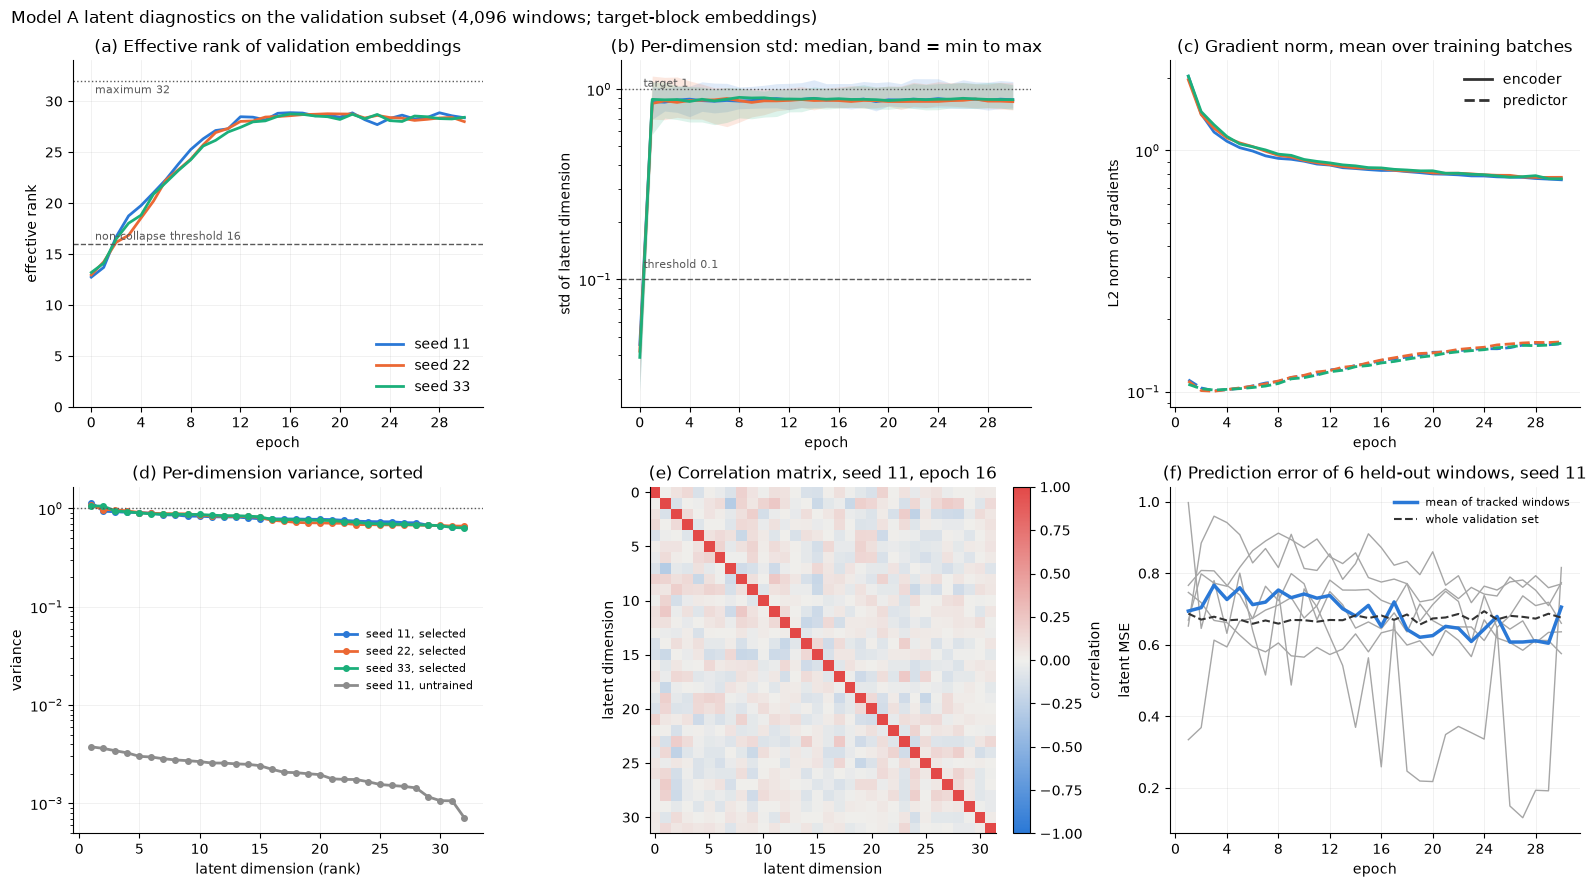

In [34]:
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

ax = axes[0, 0]
for seed in SEEDS:
    h = histories[seed]
    ax.plot(h["epoch"], h["effective_rank"], color=SEED_COLORS[seed], lw=2, label=f"seed {seed}")
ax.axhline(LATENT_DIM, color="0.35", lw=1, ls=":")
ax.axhline(DIAG_CFG["min_effective_rank"], color="0.35", lw=1, ls="--")
ax.text(0.3, LATENT_DIM - 0.4, f"maximum {LATENT_DIM}", va="top", fontsize=8, color="0.35")
ax.text(0.3, DIAG_CFG["min_effective_rank"] + 0.4, f"non-collapse threshold {DIAG_CFG['min_effective_rank']}", fontsize=8, color="0.35")
ax.set(title="(a) Effective rank of validation embeddings", xlabel="epoch", ylabel="effective rank", ylim=(0, LATENT_DIM + 2))
ax.legend(frameon=False, loc="lower right")

ax = axes[0, 1]
for seed in SEEDS:
    h = histories[seed]
    ax.fill_between(h["epoch"], h["latent_std_min"], h["latent_std_max"], color=SEED_COLORS[seed], alpha=0.15, lw=0)
    ax.plot(h["epoch"], h["latent_std_median"], color=SEED_COLORS[seed], lw=2, label=f"seed {seed}")
ax.axhline(1, color="0.35", lw=1, ls=":")
ax.axhline(DIAG_CFG["min_latent_std"], color="0.35", lw=1, ls="--")
ax.text(0.3, 1.03, "target 1", fontsize=8, color="0.35")
ax.text(0.3, DIAG_CFG["min_latent_std"] * 1.15, f"threshold {DIAG_CFG['min_latent_std']}", fontsize=8, color="0.35")
ax.set(title="(b) Per-dimension std: median, band = min to max", xlabel="epoch", ylabel="std of latent dimension", yscale="log")

ax = axes[0, 2]
for seed in SEEDS:
    h = histories[seed][histories[seed]["epoch"] > 0]
    ax.plot(h["epoch"], h["encoder_grad_norm"], color=SEED_COLORS[seed], lw=2)
    ax.plot(h["epoch"], h["predictor_grad_norm"], color=SEED_COLORS[seed], lw=2, ls="--")
ax.legend(handles=[Line2D([], [], color="0.2", lw=2, label="encoder"), Line2D([], [], color="0.2", lw=2, ls="--", label="predictor")],
          frameon=False)
ax.set(title="(c) Gradient norm, mean over training batches", xlabel="epoch", ylabel="L2 norm of gradients", yscale="log")

ax = axes[1, 0]
dims = np.arange(1, LATENT_DIM + 1)
for seed in SEEDS:
    var = np.sort(checkpoints[seed]["latent_statistics_reloaded"]["per_dim_variance"])[::-1]
    ax.plot(dims, var, color=SEED_COLORS[seed], lw=2, marker="o", ms=4, label=f"seed {seed}, selected")
ax.plot(dims, np.sort(untrained_stats[SEED]["per_dim_variance"])[::-1], color="0.55", lw=2, marker="o", ms=4,
        label=f"seed {SEED}, untrained")
ax.axhline(1, color="0.35", lw=1, ls=":")
ax.set(title="(d) Per-dimension variance, sorted", xlabel="latent dimension (rank)", ylabel="variance", yscale="log")
ax.legend(frameon=False, fontsize=8)

ax = axes[1, 1]
stats_sel = checkpoints[SEED]["latent_statistics_reloaded"]
cov = np.array(stats_sel["covariance"])
corr = cov / np.sqrt(np.outer(np.diag(cov), np.diag(cov)))
image = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.grid(False)
ax.set(title=f"(e) Correlation matrix, seed {SEED}, epoch {checkpoints[SEED]['epoch']}", xlabel="latent dimension", ylabel="latent dimension")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="correlation")

ax = axes[1, 2]
h = histories[SEED]
window_cols = [c for c in h.columns if c.startswith("window_")]
for c in window_cols:
    ax.plot(h["epoch"][1:], h[c][1:], color="0.65", lw=1)
ax.plot(h["epoch"][1:], h[window_cols][1:].mean(axis=1), color=SEED_COLORS[SEED], lw=2.5, label="mean of tracked windows")
ax.plot(h["epoch"][1:], h["val_prediction_loss"][1:], color="0.2", lw=1.5, ls="--", label="whole validation set")
ax.set(title=f"(f) Prediction error of {len(window_cols)} held-out windows, seed {SEED}", xlabel="epoch", ylabel="latent MSE")
ax.legend(frameon=False, fontsize=8)

for ax in (axes[0, 0], axes[0, 1], axes[0, 2], axes[1, 2]):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("Model A latent diagnostics on the validation subset (4,096 windows; target-block embeddings)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage3_latent_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.9 Persistence baseline

**Latent persistence** predicts "the next block looks like the last one": $\hat z^{\text{persist}}_{t+1}=z_t$, i.e. `z_history[:, -1, :]`. For each seed it is scored with the **same trained encoder** and the **same** MSE reduction as the temporal predictor, on the complete validation partition. A second reference, the training-set mean of $z_{t+1}$ (encoded with the same encoder), shows the error of a predictor that ignores the history.

Errors are compared **within** a seed only. Each seed has its own latent space, so absolute MSE values from different seeds are not comparable as if they measured the same quantity. The relative improvement is comparable across seeds.

,temporal predictor MSE,persistence MSE,training-mean MSE,improvement over persistence,improvement over training mean,windows where predictor beats persistence
seed,,,,,,
11,0.6818,1.2932,0.8028,47.3%,15.1%,95.7%
22,0.6715,1.2652,0.7917,46.9%,15.2%,95.1%
33,0.6768,1.2780,0.7996,47.0%,15.4%,95.1%
mean,0.6767,1.2788,0.7980,47.1%,15.2%,95.3%
std,0.0051,0.0140,0.0057,0.2%,0.1%,0.4%


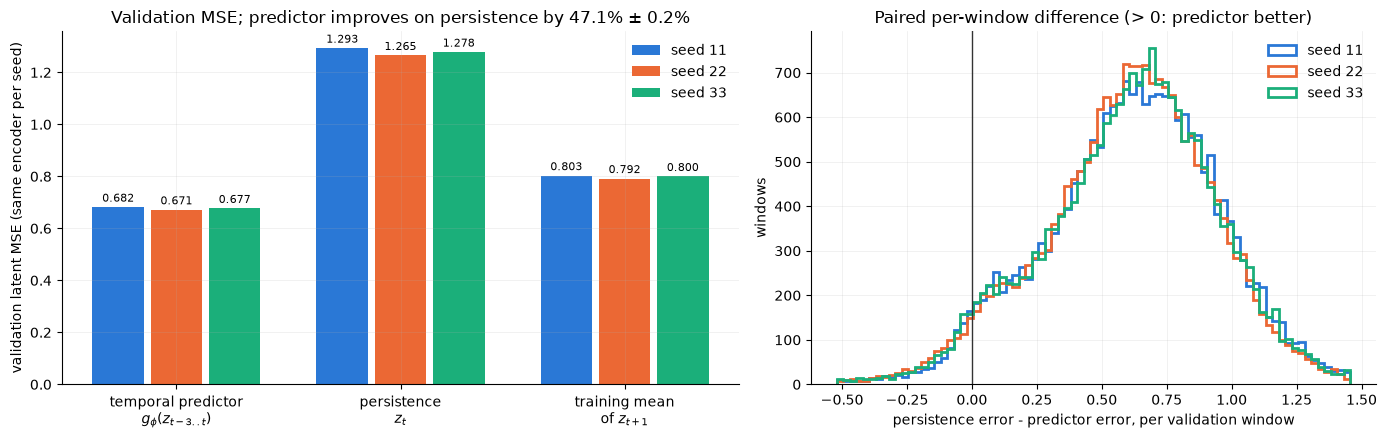

In [35]:
persistence_rows, paired_differences = [], {}
for seed in SEEDS:
    val_out = encode_windows(models[seed], datasets["val"], device=DEVICE, batch_size=4096)
    train_mean = encode_windows(models[seed], datasets["train"], device=DEVICE, batch_size=4096)["z_target"].mean(0)
    mse_pred = prediction_loss(val_out["z_pred"], val_out["z_target"]).item()
    mse_persist = prediction_loss(val_out["z_history"][:, -1], val_out["z_target"]).item()
    mse_mean = prediction_loss(train_mean.expand_as(val_out["z_target"]), val_out["z_target"]).item()
    err_pred = (val_out["z_pred"] - val_out["z_target"]).pow(2).mean(1)
    err_persist = (val_out["z_history"][:, -1] - val_out["z_target"]).pow(2).mean(1)
    paired_differences[seed] = (err_persist - err_pred).numpy()
    persistence_rows.append({"seed": seed, "temporal predictor MSE": mse_pred, "persistence MSE": mse_persist,
                             "training-mean MSE": mse_mean, "improvement over persistence": 1 - mse_pred / mse_persist,
                             "improvement over training mean": 1 - mse_pred / mse_mean,
                             "windows where predictor beats persistence": float((err_pred < err_persist).float().mean())})
persistence = pd.DataFrame(persistence_rows).set_index("seed")
persistence.loc["mean"] = persistence.mean()
persistence.loc["std"] = persistence.loc[SEEDS].std()
display(persistence.style.format({c: "{:.1%}" if c.startswith(("improvement", "windows")) else "{:.4f}" for c in persistence.columns}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})
methods = [("temporal predictor MSE", "temporal predictor\n$g_\\phi(z_{t-3..t})$"), ("persistence MSE", "persistence\n$z_t$"),
           ("training-mean MSE", "training mean\nof $z_{t+1}$")]
x, width = np.arange(len(methods)), 0.26
for j, seed in enumerate(SEEDS):
    bars = ax1.bar(x + (j - 1) * width, [persistence.loc[seed, m] for m, _ in methods], width - 0.03,
                   color=SEED_COLORS[seed], label=f"seed {seed}")
    ax1.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax1.set_xticks(x, [label for _, label in methods])
ax1.set(ylabel="validation latent MSE (same encoder per seed)",
        title=f"Validation MSE; predictor improves on persistence by "
              f"{persistence.loc['mean', 'improvement over persistence']:.1%} ± {persistence.loc['std', 'improvement over persistence']:.1%}")
ax1.legend(frameon=False)
bins = np.linspace(*np.percentile(np.concatenate(list(paired_differences.values())), [0.5, 99.5]), 80)
for seed in SEEDS:
    ax2.hist(paired_differences[seed], bins=bins, histtype="step", lw=2, color=SEED_COLORS[seed], label=f"seed {seed}")
ax2.axvline(0, color="0.2", lw=1)
ax2.set(xlabel="persistence error - predictor error, per validation window", ylabel="windows",
        title="Paired per-window difference (> 0: predictor better)")
ax2.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage3_persistence_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.10 Results and Stage 3 completion checks

**Training curves.** Solid lines are training means over each epoch, from a model that changes during the epoch. Dashed lines are validation values at the end of the epoch, with fixed batches and projections. Epoch 0 is the untrained model and has validation values only. Rings mark the selected checkpoints. The axes are logarithmic because the untrained values differ from the trained ones by orders of magnitude.

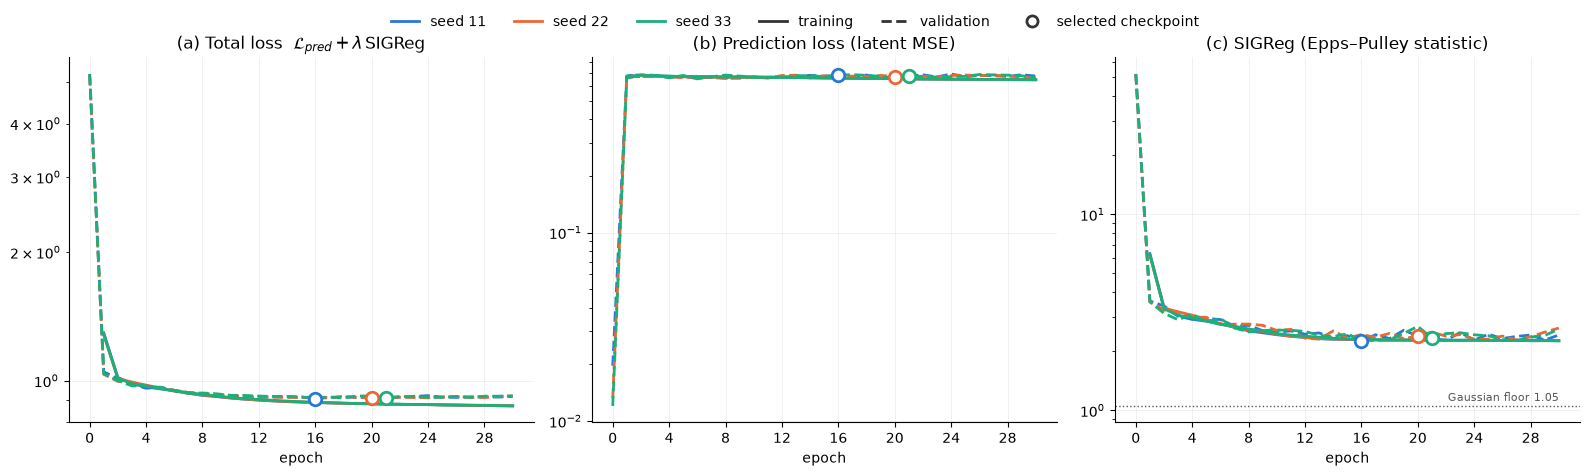

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
panels = [("total_loss", "(a) Total loss  $\\mathcal{L}_{pred} + \\lambda\\,$SIGReg"),
          ("prediction_loss", "(b) Prediction loss (latent MSE)"),
          ("sigreg_loss", "(c) SIGReg (Epps–Pulley statistic)")]
for ax, (key, title) in zip(axes, panels):
    for seed in SEEDS:
        h, c = histories[seed], SEED_COLORS[seed]
        ax.plot(h["epoch"][1:], h[f"train_{key}"][1:], color=c, lw=2)
        ax.plot(h["epoch"], h[f"val_{key}"], color=c, lw=2, ls="--")
        sel = h[h["selected"]]
        ax.plot(sel["epoch"], sel[f"val_{key}"], "o", ms=9, mfc="white", mec=c, mew=2, zorder=5)
    ax.set(title=title, xlabel="epoch", yscale="log")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[2].axhline(NULL_EP, color="0.35", lw=1, ls=":")
axes[2].text(train_cfg["max_epochs"], NULL_EP * 1.06, f"Gaussian floor {NULL_EP:.2f}", ha="right", fontsize=8, color="0.35")
handles = ([Line2D([], [], color=SEED_COLORS[s], lw=2, label=f"seed {s}") for s in SEEDS]
           + [Line2D([], [], color="0.2", lw=2, label="training"), Line2D([], [], color="0.2", lw=2, ls="--", label="validation"),
              Line2D([], [], color="0.2", marker="o", ms=8, mfc="white", mew=2, lw=0, label="selected checkpoint")])
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage3_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Reload in a fresh session.** A separate Python process, with no state shared with this kernel, loads every checkpoint with `load_checkpoint` and computes the forward outputs for 256 fixed validation windows. The outputs must match those of the models in this notebook. The Stage 2 causality test is repeated on the trained models.

In [37]:
show_location(load_checkpoint)
reference_inputs = {k: getattr(datasets["val"], k)[:256] for k in ("context", "context_mask", "target", "target_mask")}
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    torch.save(reference_inputs, tmp / "inputs.pt")
    paths = {seed: str(checkpoint_path[seed]) for seed in SEEDS}
    script = textwrap.dedent(f"""
        import sys, torch
        sys.path.insert(0, {str(PROJECT_ROOT)!r})
        from src.training import load_checkpoint
        inputs = torch.load({str(tmp / 'inputs.pt')!r})
        outputs = {{}}
        for seed, path in {paths!r}.items():
            model, checkpoint = load_checkpoint(path)
            with torch.no_grad():
                outputs[seed] = {{**model(**inputs), "epoch": checkpoint["epoch"]}}
        torch.save(outputs, {str(tmp / 'outputs.pt')!r})
    """)
    proc = subprocess.run([sys.executable, "-c", script], capture_output=True, text=True, cwd=PROJECT_ROOT)
    assert proc.returncode == 0, proc.stderr
    fresh = torch.load(tmp / "outputs.pt")

reload_rows = []
for seed in SEEDS:
    with torch.no_grad():
        here = models[seed](**{k: v.to(DEVICE) for k, v in reference_inputs.items()})
        altered = models[seed](**{**{k: v.to(DEVICE) for k, v in reference_inputs.items()},
                                  "target": torch.randn_like(reference_inputs["target"]).to(DEVICE)})
    reload_rows.append({"seed": seed, "epoch in checkpoint": fresh[seed]["epoch"],
                        **{f"max |diff| {k}": (fresh[seed][k] - here[k].cpu()).abs().max().item() for k in ("z_history", "z_pred", "z_target")},
                        "trained model: target does not affect z_pred": torch.equal(altered["z_pred"], here["z_pred"])})
reload_table = pd.DataFrame(reload_rows).set_index("seed")
display(reload_table)
reload_ok = bool((reload_table.filter(like="max |diff|") < 1e-6).all().all())
causal_trained_ok = bool(reload_table["trained model: target does not affect z_pred"].all())

Using load_checkpoint from src/training/trainer.py, line 195


,epoch in checkpoint,max |diff| z_history,max |diff| z_pred,max |diff| z_target,trained model: target does not affect z_pred
seed,,,,,
11,16,0.0,0.0,0.0,True
22,20,0.0,0.0,0.0,True
33,21,0.0,0.0,0.0,True


**Summary.** The hyperparameters, the selection rule, and the per-seed and aggregate validation results are written to `results/stage3_summary.json`.

In [38]:
def mean_std(values):
    return {"mean": float(np.mean(values)), "std": float(np.std(values, ddof=1)) if len(values) > 1 else 0.0}


summary = {
    "stage": 3, "model": "Model A: standard temporal LeWorldModel (clean windows, all-ones masks)",
    "data": {"train_windows": len(datasets["train"]), "val_windows": n_val, "partitions_used": ["train", "val"],
             "test_partition_used": False, "artificial_corruption": False, "failure_or_maintenance_labels_used": False},
    "architecture": {"encoder": f"{INPUT_DIM} -> {model_cfg['encoder_hidden_dims']} -> {LATENT_DIM}, GELU",
                     "predictor": f"{CONTEXT_LENGTH * LATENT_DIM} -> {model_cfg['predictor_hidden_dims']} -> {LATENT_DIM}, GELU",
                     "parameters": sum(p.numel() for p in models[SEED].parameters())},
    "hyperparameters": hyperparameters(config, DEVICE),
    "objective": "prediction_loss (MSE, mean over batch and 32 dims) + sigreg_weight * SIGReg([5, B, 32])",
    "sigreg": {**sigreg.settings(), "null_expectation_quadrature": NULL_EP, "null_expectation_exact": SIGReg.null_expectation_exact()},
    "noncollapse_criteria": {"min_effective_rank": DIAG_CFG["min_effective_rank"], "min_latent_std": DIAG_CFG["min_latent_std"]},
    "selection_rule": "lowest validation total loss among epochs passing the non-collapse checks",
    "benchmark": {"ms_per_step": benchmark["ms per training step"].round(2).to_dict(), "seconds_per_full_epoch": epoch_seconds},
    "seeds": {},
}
for seed in SEEDS:
    stats = checkpoints[seed]["latent_statistics_reloaded"]
    summary["seeds"][str(seed)] = {
        "checkpoint": str(rel(checkpoint_path[seed])), "selected_epoch": checkpoints[seed]["epoch"],
        "val_metrics": checkpoints[seed]["val_metrics"], "train_time_s": float(train_seconds[seed]),
        "latent_statistics": {k: stats[k] for k in stat_keys},
        "persistence": {k: float(persistence.loc[seed, k]) for k in persistence.columns},
    }
summary["aggregate_over_seeds"] = {
    **{k: mean_std([checkpoints[s]["val_metrics"][f"val_{k}"] for s in SEEDS]) for k in LOSS_KEYS},
    "effective_rank": mean_std([checkpoints[s]["latent_statistics_reloaded"]["effective_rank"] for s in SEEDS]),
    "improvement_over_persistence": mean_std(persistence.loc[SEEDS, "improvement over persistence"].tolist()),
}
with (RESULTS_DIR / "stage3_summary.json").open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

compact = pd.Series({
    "optimizer / learning rate / batch": f"{train_cfg['optimizer']} / {train_cfg['learning_rate']} / {BATCH_SIZE}",
    "epochs / seeds": f"{train_cfg['max_epochs']} / {SEEDS}",
    "lambda / projections / knots / t_max": f"{LAMBDA} / {SIGREG_CFG['num_proj']} / {SIGREG_CFG['knots']} / {SIGREG_CFG['t_max']}",
    "non-collapse checks": f"effective rank >= {DIAG_CFG['min_effective_rank']}, every latent std >= {DIAG_CFG['min_latent_std']}",
    "selection": summary["selection_rule"],
    "selected epochs": {s: checkpoints[s]["epoch"] for s in SEEDS},
    "val total loss (mean ± std)": "{mean:.4f} ± {std:.4f}".format(**summary["aggregate_over_seeds"]["total_loss"]),
    "val prediction loss (mean ± std)": "{mean:.4f} ± {std:.4f}".format(**summary["aggregate_over_seeds"]["prediction_loss"]),
    "val SIGReg (mean ± std)": "{mean:.3f} ± {std:.3f}".format(**summary["aggregate_over_seeds"]["sigreg_loss"]),
    "effective rank (mean ± std)": "{mean:.1f} ± {std:.1f}".format(**summary["aggregate_over_seeds"]["effective_rank"]),
    "improvement over persistence": "{mean:.1%} ± {std:.1%}".format(**summary["aggregate_over_seeds"]["improvement_over_persistence"]),
    "device / time per seed": f"{DEVICE} / {np.mean(list(train_seconds.values())) / 60:.0f} min",
}, name="Model A").to_frame()
display(compact)

,Model A
optimizer / learning rate / batch,Adam / 0.001 / 128
epochs / seeds,"30 / [11, 22, 33]"
lambda / projections / knots / t_max,0.1 / 1024 / 17 / 3.0
non-collapse checks,"effective rank >= 16, every latent std >= 0.1"
selection,lowest validation total loss among epochs pass...
selected epochs,"{11: 16, 22: 20, 33: 21}"
val total loss (mean ± std),0.9093 ± 0.0021
val prediction loss (mean ± std),0.6767 ± 0.0051
val SIGReg (mean ± std),2.326 ± 0.072
effective rank (mean ± std),28.8 ± 0.1


In [39]:
stage3_results = []


def check3(name, condition):
    stage3_results.append((name, bool(condition)))
    print(f"[{'PASS' if condition else 'FAIL'}] {name}")


# Both modules moved away from their initialization in every seed.
moved = all(
    any(not torch.equal(a, b) for a, b in zip(getattr(models[s], part).state_dict().values(),
                                              getattr(build_model(config, s, DEVICE), part).state_dict().values()))
    for s in SEEDS for part in ("encoder", "predictor"))
recorded = all(metrics.loc[metrics["epoch"] > 0, [f"{split}_{k}" for split in ("train", "val") for k in LOSS_KEYS]].notna().all())

check3("Both modules train end-to-end (encoder and predictor parameters changed for every seed)", moved)
check3("Shared encoder and target branch remain differentiable (gradient tests 7.2, 7.5)", gradient_tests_ok and pred_checks["z_target not detached (receives gradient)"])
check3("SIGReg validated against its mathematical definition (7.3: " + ", ".join(sigreg_tests) + ")", all(sigreg_tests.values()))
check3("Training and validation losses recorded separately (results/stage3_training_metrics.csv)", recorded)
check3("Trained representation is non-collapsed (predefined checks on every selected checkpoint)", noncollapsed_ok)
check3("Validation results available (results/stage3_summary.json)", (RESULTS_DIR / "stage3_summary.json").exists())
check3("Persistence comparison available (same encoder, same MSE reduction)", persistence.loc[SEEDS].notna().all().all())
check3("Best checkpoint saved and reloads in a fresh process with identical outputs", reload_ok)
check3("Reproducible: identical histories and parameters for the same seed (sanity run)", reproducible_ok)
check3("Causality: the target never affects z_pred, untrained and trained", causal_ok and causal_trained_ok)
check3("No artificial corruption (all training masks are ones) and no test-set use",
       bool((datasets["train"].context_mask == 1).all() and (datasets["train"].target_mask == 1).all())
       and summary["data"]["test_partition_used"] is False)

print(f"\n{sum(ok for _, ok in stage3_results)}/{len(stage3_results)} Stage 3 checks passed")
for path in sorted([*checkpoint_path.values(), RESULTS_DIR / "stage3_training_metrics.csv", RESULTS_DIR / "stage3_summary.json",
                    *(FIGURES_DIR / f"stage3_{n}.png" for n in ("training_curves", "latent_diagnostics", "persistence_comparison"))]):
    print(f"  {rel(path)}  ({path.stat().st_size / 1024:.0f} KiB)")
assert all(ok for _, ok in stage3_results), [name for name, ok in stage3_results if not ok]

[PASS] Both modules train end-to-end (encoder and predictor parameters changed for every seed)
[PASS] Shared encoder and target branch remain differentiable (gradient tests 7.2, 7.5)
[PASS] SIGReg validated against its mathematical definition (7.3: unit directions, N(0,1) characteristic function, trapezoid integration, scalar, finite, differentiable, N-scaling calibrated, configurable projections, gradients reach embeddings, diagnostic cases)
[PASS] Training and validation losses recorded separately (results/stage3_training_metrics.csv)
[PASS] Trained representation is non-collapsed (predefined checks on every selected checkpoint)
[PASS] Validation results available (results/stage3_summary.json)
[PASS] Persistence comparison available (same encoder, same MSE reduction)
[PASS] Best checkpoint saved and reloads in a fresh process with identical outputs
[PASS] Reproducible: identical histories and parameters for the same seed (sanity run)
[PASS] Causality: the target never affects z_pred,

## Stage 3 complete

All 11 Stage 3 checks pass. **Model A** is trained for seeds 11, 22 and 33 (30 epochs each, about 28 min per seed on CPU). The selected checkpoints are `checkpoints/model_a_best_seed{11,22,33}.pt`.

| Seed | Selected epoch | Val total | Val prediction | Val SIGReg | Effective rank | Min latent std | Predictor MSE | Persistence MSE | Training-mean MSE |
|---|---|---|---|---|---|---|---|---|---|
| 11 | 16 | 0.907 | 0.682 | 2.25 | 28.9 | 0.80 | 0.682 | 1.293 | 0.803 |
| 22 | 20 | 0.911 | 0.672 | 2.39 | 28.7 | 0.81 | 0.672 | 1.265 | 0.792 |
| 33 | 21 | 0.910 | 0.677 | 2.33 | 28.7 | 0.80 | 0.677 | 1.278 | 0.800 |
| mean ± std | | 0.909 ± 0.002 | 0.677 ± 0.005 | 2.33 ± 0.07 | 28.8 ± 0.1 | | improvement over persistence **47.1% ± 0.2%** | | improvement over training mean **15.2% ± 0.2%** |

**What the results show**

1. **The representation is not collapsed.** On the fixed validation subset, effective rank went from about 13 (untrained) to 28.8 of 32. Every latent dimension has std between 0.80 and 1.07, against 0.03–0.06 untrained, and the largest absolute correlation is about 0.3. Every epoch from epoch 2 onward passes the predefined checks, in all seeds.
2. **The distribution is close to, but not exactly, isotropic Gaussian.** Validation SIGReg is 2.3, between the Gaussian floor (≈ 1.05) and the collapse value (≈ 52). The weighted term, λ · 2.3 ≈ 0.23, is about one third of the prediction loss, so λ = 0.1 leaves both terms active, as intended.
3. **The prediction loss alone would have been misleading.** It was 0.02 for the untrained, nearly collapsed encoder and has stayed at 0.66–0.69 since epoch 1. After epoch 1, almost all of the decrease in total loss comes from SIGReg (3.6 → 2.3) and the rising effective rank.
4. **The temporal predictor uses the history.** Within each seed, with the same encoder and the same MSE, it beats latent persistence by 47% and is better on about 95% of validation windows. It also beats the training-set mean of $z_{t+1}$ by 15%, so it extracts information from the four past blocks beyond the marginal mean.
5. **Persistence is worse than the training mean** (≈ 1.28 vs ≈ 0.80). Embeddings of consecutive 6-hour blocks are only weakly correlated, which fits this simulated telemetry: hour-to-hour noise around slowly varying levels. The predictable part of the next-block latent is modest, about 15% of its variance relative to the mean predictor.
6. **Training is stable and consistent across seeds.**
   - Validation total loss plateaus after about epoch 12–16, while training loss keeps falling slowly. The resulting train–validation gap is small (≈ 0.04 at epoch 30).
   - The predictor's gradient norm grows slowly while the encoder's decreases. Gradients are finite throughout.
   - Seed-to-seed spread of the validation total loss is 0.002.

**Caveats**

- **Absolute MSE values across seeds** describe different latent spaces. Only the within-seed ratios (improvement percentages) are compared across seeds.
- **The six tracked held-out windows** are individually noisy (panel f of the diagnostics figure). They are illustrations, not a metric.
- **The test partition** has not been used. Stage 4 should load these three checkpoints as Model A, and evaluate corrupted inputs against the same clean targets.

**Outputs:** `results/stage3_training_metrics.csv` (one row per seed and epoch), `results/stage3_summary.json`, `figures/stage3_training_curves.png`, `figures/stage3_latent_diagnostics.png`, `figures/stage3_persistence_comparison.png`.

# Stage 4 — Historical Telemetry Dropouts and Three-Model Robustness Comparison

## 8. Robustness experiments

**Hypothesis.** Explicit availability masks improve the robustness of temporal latent-state prediction under intermittent **historical** sensor dropouts, compared with corruption augmentation alone.

| Model | Training data | Missing values | Context-mask channels | Weights |
|---|---|---|---|---|
| **A** standard | clean | replaced by 0 at evaluation | all ones | Stage 3 checkpoints, not retrained |
| **B** corruption-augmented | 50% clean + 50% corrupted | replaced by 0 | all ones, also where missing | new, same initialization as C |
| **C** mask-aware | identical to B | replaced by 0 | actual availability mask | new, same initialization as B |

The primary comparison is **B vs C**: both see the same values, so the only difference is whether the encoder is told which zeros are missing readings. A shows what happens without any exposure to dropout.

The architecture, SIGReg, objective $\mathcal L_{\text{pred}}+0.1\cdot\operatorname{SIGReg}$, optimizer and window construction are unchanged from Stages 2–3. The test partition is not used.

| Subsection | Contents |
|---|---|
| 8.1 | Historical dropout generator |
| 8.2 | Dropout validation tests |
| 8.3 | Model comparison protocol |
| 8.4 | Training Models B and C |
| 8.5 | Validation and checkpointing |
| 8.6 | Robustness evaluation |
| 8.7 | Surprise-score and alert analysis |
| 8.8 | Temporal-information checks |
| 8.9 | Figures, tables and Stage 4 validation |

| File | Contents |
|---|---|
| `configs/stage4.yaml` | every Stage 4 setting, fixed before training and evaluation |
| `src/data/corruption.py` | masks, zero fill, input policies, training corruption, timeline schedules |
| `src/training/robust.py` | training of B and C with the Stage 3 `fit` (also a command-line runner) |
| `src/training/trainer.py` | Stage 3 `fit`, extended with optional hooks (defaults unchanged) |
| `src/evaluation/robustness.py` | paired metrics, alerts, machine bootstrap, temporal checks |
| `tests/test_corruption.py` | unit tests of the corruption module |

This section needs only the setup cells of Sections 1 and 7.1 (`config`, `datasets`, `metadata`, `show_location`).

In [4]:
from src.data import (TrainingCorruption, WindowTimeline, check_invariants, make_generator, policy_inputs,
                      scenario_schedule, stream_seed)
from src.evaluation import (affected_windows, alert_rate, alert_threshold, block_permutations, bootstrap_weights,
                            interval, machine_sums, mismatched_history_indices, paired_metrics, permute_blocks,
                            predict, proxy_normal_windows, weighted_ratio, window_scores)
from src.training import (MODEL_NAMES, build_model, build_sigreg, diagnostic_indices, encode_windows, evaluate,
                          latent_statistics, load_checkpoint, load_configs, noncollapse_checks, prediction_loss,
                          select_device, to_device, train_corrupted_model)
import importlib
import json
import math
import subprocess
import sys
import tempfile
import textwrap
import time

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

base_config, S4 = load_configs(PROJECT_ROOT)
assert base_config == config, "configs/base.yaml changed since the setup cell ran"

train_cfg, SIGREG_CFG, DIAG_CFG = config["training"], config["training"]["sigreg"], config["training"]["diagnostics"]
SEEDS, LAMBDA = train_cfg["random_seeds"], train_cfg["sigreg_weight"]
DEVICE = select_device(train_cfg["device"])
FILL = S4["fill_value"]
MODELS = ["A", "B", "C"]
INPUT_MASK = {m: S4["models"][m]["input_mask"] for m in MODELS}
CHECKPOINTS = {(m, s): PROJECT_ROOT / S4["models"][m]["checkpoint"].format(seed=s) for m in MODELS for s in SEEDS}
SCENARIOS = list(S4["evaluation"]["scenarios"])
INDEPENDENT = [n for n in SCENARIOS if S4["evaluation"]["scenarios"][n]["pattern"] == "independent"]  # 0, 10, 20, 40%
SEVERITY = {n: S4["evaluation"]["scenarios"][n]["rate"] for n in INDEPENDENT}
RETRAIN_STAGE4 = False  # True: train B and C again in this kernel even if their checkpoints exist

CHECKPOINT_DIR, RESULTS_DIR, FIGURES_DIR = PROJECT_ROOT / "checkpoints", PROJECT_ROOT / "results", PROJECT_ROOT / "figures"
val_ds, train_ds = datasets["val"], datasets["train"]
val_meta = metadata[metadata["partition"] == "val"].reset_index(drop=True)
N_VAL = len(val_ds)
DIAG_IDX, TRACKED_IDX = diagnostic_indices(N_VAL, DIAG_CFG)  # the same fixed subsets as Stage 3

# One fixed colour and marker per model in every Stage 4 figure; seeds are distinguished by marker fill only.
MODEL_COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
MODEL_MARKERS = {"A": "o", "B": "s", "C": "^"}
MODEL_LABELS = {"A": "A  clean training", "B": "B  augmented, all-ones mask", "C": "C  augmented, mask-aware"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})


def rel(path):
    try:
        return Path(path).relative_to(PROJECT_ROOT).as_posix()
    except ValueError:
        return str(path)


def mean_std(values):
    values = [float(v) for v in values]
    return {"mean": float(np.mean(values)), "std": float(np.std(values, ddof=1)) if len(values) > 1 else 0.0}


def pm(values, fmt="{:.3f}"):
    # "mean ± std" over seeds
    ms = mean_std(values)
    return f"{fmt.format(ms['mean'])} ± {fmt.format(ms['std'])}"


display(pd.DataFrame({m: {"description": MODEL_NAMES[m], "context-mask channels": INPUT_MASK[m],
                          "trained in Stage 4": S4["models"][m]["train"],
                          "checkpoints": S4["models"][m]["checkpoint"]} for m in MODELS}).T)
print(f"Training corruption: {S4['training_corruption']}")
print(f"Selection: {S4['selection']}")
print(f"Evaluation scenarios ({len(SCENARIOS)}): {', '.join(SCENARIOS)}; scenario seed {S4['evaluation']['scenario_seed']}")

,description,context-mask channels,trained in Stage 4,checkpoints
A,Model A: standard temporal LeWorldModel (clean...,ones,False,checkpoints/model_a_best_seed{seed}.pt
B,Model B: corruption-augmented temporal LeWorld...,ones,True,checkpoints/model_b_best_seed{seed}.pt
C,Model C: mask-aware temporal LeWorldModel (cle...,mask,True,checkpoints/model_c_best_seed{seed}.pt


Training corruption: {'pattern': 'independent', 'clean_fraction': 0.5, 'rates': [0.1, 0.2, 0.4], 'stream_seed': 4001}
Selection: {'weights': {'clean': 0.5, 'corrupted': 0.5}, 'corrupted_val_rates': [0.1, 0.2, 0.4], 'corrupted_val_seed': 4101}
Evaluation scenarios (7): clean, independent_10, independent_20, independent_40, burst_6h, burst_12h, outage; scenario seed 4201


### 8.1 Historical dropout generator

The generator lives in `src/data/corruption.py` and never touches a network. It produces **availability masks** $a\in\{0,1\}$ (1 = observed) for the **historical context only**, and applies them to the standardized readings: removed readings become 0, the training-set mean after Stage 1 scaling. Every function returns new tensors, so the stored readings are never overwritten.

**Three patterns.**

1. **Independent dropout.** Every reading is removed independently with probability $p\in\{0, 0.1, 0.2, 0.4\}$.
2. **Consecutive packet-loss burst.** One sensor loses 6 or 12 consecutive hours. The burst can start at any hour, so it usually straddles two 6-hour blocks.
3. **Temporary sensor outage.** One sensor is unavailable for one or two whole 6-hour blocks, aligned with the block grid.

**Training masks vs evaluation schedules.**

- *Training* (B, C): `TrainingCorruption` draws fresh masks for every batch from its own seeded stream: exactly half of the batch is clean, the other half gets independent dropout at 10%, 20% or 40% (drawn uniformly). Bursts and outages are **never** used in training. They are held-out stress tests.
- *Evaluation*: windows overlap (6-hour stride, 24-hour context), so one sensor-hour belongs to four contexts. Drawing a mask per window would call the same reading available in one window and missing in the next. Each scenario is therefore one **machine × hour × sensor schedule** on the validation timeline, and every window's mask is cut out of it (`WindowTimeline.window_masks`). Bursts and outages are placed once per 30-hour period of each machine (the span of one window), at a random position and on a random sensor. A context can thus contain no event, part of one, or parts of two.

**Controlled assumption: clean targets.** The prediction target $x_{t+1}$ is always the clean recorded block with an all-ones mask, even where the schedule removes the same hours from a neighbouring window's context. This isolates the effect of a damaged history on the prediction. It is a property of the experiment, not of real telemetry, where the future block could itself be incomplete.

All seeds are derived with `numpy.random.SeedSequence` from integers and scenario names (CRC-32), never with Python's per-process salted `hash()`.

In [5]:
for obj in (stream_seed, policy_inputs, TrainingCorruption, WindowTimeline, scenario_schedule):
    show_location(obj)

timeline = WindowTimeline(val_meta, BLOCK_SIZE, CONTEXT_LENGTH)
same_machine_next = timeline.machine_index[1:] == timeline.machine_index[:-1]
assert (np.diff(timeline.offset)[same_machine_next] == BLOCK_SIZE).all()  # 6 h stride within every machine
print(f"Validation timeline: {timeline.num_machines} machines x {timeline.hours} hours x {NUM_SENSORS} sensors; "
      f"{N_VAL:,} windows, consecutive windows of a machine share 18 of their 24 context hours")


def scenario_description(spec):
    if spec["pattern"] == "independent":
        return "no corruption" if spec["rate"] == 0 else f"every reading removed with p = {spec['rate']}"
    if spec["pattern"] == "burst":
        return f"{spec['duration_hours']} consecutive hours of one sensor, once per {spec['cycle_hours']} h"
    return (f"one sensor for {' or '.join(map(str, spec['blocks']))} aligned 6 h blocks, "
            f"once per {spec['cycle_blocks'] * BLOCK_SIZE} h")


SCHEDULES, EVAL_AVAILABILITY = {}, {}
for name, spec in S4["evaluation"]["scenarios"].items():
    SCHEDULES[name] = scenario_schedule(spec, timeline, NUM_SENSORS, make_generator(S4["evaluation"]["scenario_seed"], name))
    EVAL_AVAILABILITY[name] = timeline.window_masks(SCHEDULES[name])
AFFECTED = {name: affected_windows(a) for name, a in EVAL_AVAILABILITY.items()}

rows = []
for name, avail in EVAL_AVAILABILITY.items():
    removed = (avail == 0).reshape(N_VAL, -1)
    aff = AFFECTED[name]
    rows.append({"scenario": name, "pattern": S4["evaluation"]["scenarios"][name]["pattern"],
                 "description": scenario_description(S4["evaluation"]["scenarios"][name]),
                 "removed share of context readings": removed.float().mean().item(),
                 "windows affected": aff.float().mean().item(),
                 "removed share in affected windows": removed[aff].float().mean().item() if aff.any() else 0.0,
                 "sensors hit per affected window": (avail == 0).any(dim=(1, 2))[aff].sum(1).float().mean().item() if aff.any() else 0.0})
scenario_table = pd.DataFrame(rows).set_index("scenario")
display(scenario_table.style.format({c: "{:.1%}" for c in scenario_table.columns if "share" in c or "affected" in c}
                                    | {"sensors hit per affected window": "{:.2f}"}))

Using stream_seed from src/data/corruption.py, line 33
Using policy_inputs from src/data/corruption.py, line 84
Using TrainingCorruption from src/data/corruption.py, line 97
Using WindowTimeline from src/data/corruption.py, line 164
Using scenario_schedule from src/data/corruption.py, line 237
Validation timeline: 100 machines x 1314 hours x 4 sensors; 21,500 windows, consecutive windows of a machine share 18 of their 24 context hours


,pattern,description,removed share of context readings,windows affected,removed share in affected windows,sensors hit per affected window
scenario,,,,,,
clean,independent,no corruption,0.0%,0.0%,0.0%,0.00
independent_10,independent,every reading removed with p = 0.1,10.0%,100.0%,10.0%,3.68
independent_20,independent,every reading removed with p = 0.2,20.0%,100.0%,20.0%,3.98
independent_40,independent,every reading removed with p = 0.4,40.0%,100.0%,40.0%,4.00
burst_6h,burst,"6 consecutive hours of one sensor, once per 30 h",5.0%,84.7%,5.9%,1.10
burst_12h,burst,"12 consecutive hours of one sensor, once per 30 h",10.0%,95.7%,10.4%,1.16
outage,outage,"one sensor for 1 or 2 aligned 6 h blocks, once per 30 h",7.5%,79.9%,9.4%,1.09


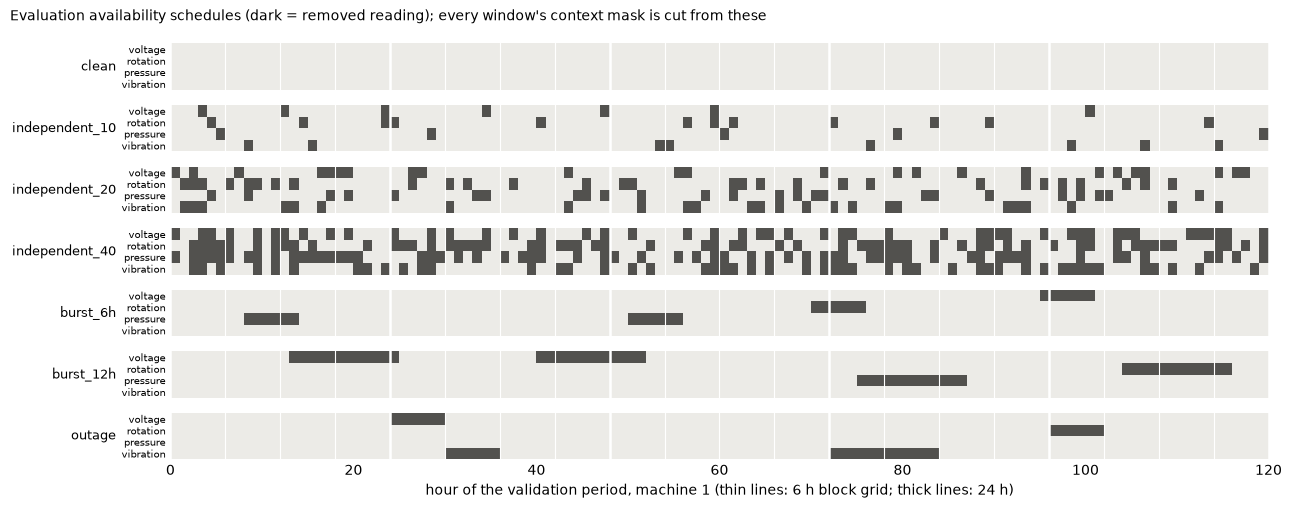

In [6]:
# Illustration: the first 5 days of one validation machine under every scenario (dark = removed).
machine, hours = 0, 120
fig, axes = plt.subplots(len(SCENARIOS), 1, figsize=(13, 0.62 * len(SCENARIOS) + 0.8), sharex=True)
cmap = plt.matplotlib.colors.ListedColormap(["#52514e", "#ecebe7"])
for ax, name in zip(axes, SCENARIOS):
    ax.imshow(SCHEDULES[name][machine, :hours].T.numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1,
              interpolation="nearest", extent=(0, hours, NUM_SENSORS - 0.5, -0.5))
    for h in range(0, hours + 1, BLOCK_SIZE):
        ax.axvline(h, color="white", lw=0.8 if h % 24 else 1.8)
    ax.grid(False)
    ax.set_yticks(range(NUM_SENSORS), SENSORS, fontsize=7)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[-1].set_xlabel(f"hour of the validation period, machine {timeline.machine_ids[machine]} "
                    "(thin lines: 6 h block grid; thick lines: 24 h)")
fig.suptitle("Evaluation availability schedules (dark = removed reading); every window's context mask is cut from these",
             x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage4_corruption_examples.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.2 Dropout validation tests

**Unit tests** (`tests/test_corruption.py`, also runnable with `python -m pytest tests` or `python tests/test_corruption.py`). They run on synthetic tensors and check:

- the requested dropout proportions on large batches;
- the invariants for both mask policies;
- that the two policies differ only in the mask half of the encoder input;
- reproducibility from seeds;
- the exact pairing of B and C training corruption;
- the 50/50 training mixture;
- burst and outage geometry;
- that overlapping windows agree.

**Real-data checks** repeat the invariants on the complete validation partition for every evaluation scenario.

In [7]:
show_location(check_invariants)
import tests.test_corruption as corruption_tests
importlib.reload(corruption_tests)
unit_tests = pd.DataFrame(corruption_tests.run_all(), columns=["unit test", "passed", "message"]).set_index("unit test")
display(unit_tests)

clean_val = {"context": val_ds.context, "target": val_ds.target, "target_mask": val_ds.target_mask}
original_context, original_target = val_ds.context.clone(), val_ds.target.clone()
rows = []
for name, avail in EVAL_AVAILABILITY.items():
    for policy in ("ones", "mask"):
        out = policy_inputs(val_ds.context, avail, val_ds.target, policy, FILL)
        rows.append({"scenario": name, "mask policy": policy,
                     **check_invariants(clean_val, out, avail, FILL, original_context=original_context)})
    again = timeline.window_masks(scenario_schedule(S4["evaluation"]["scenarios"][name], timeline, NUM_SENSORS,
                                                    make_generator(S4["evaluation"]["scenario_seed"], name)))
    rows[-1]["regenerated identically from its seed"] = rows[-2]["regenerated identically from its seed"] = torch.equal(again, avail)
    # Overlap consistency: block k + 1 of window i is block k of window i + 1 of the same machine.
    shared_ok = torch.equal(avail[1:][same_machine_next][:, :-1], avail[:-1][same_machine_next][:, 1:])
    rows[-1]["overlapping windows agree"] = rows[-2]["overlapping windows agree"] = shared_ok
real_checks = pd.DataFrame(rows).set_index(["scenario", "mask policy"])
display(real_checks)

rate_rows = []
for name in INDEPENDENT[1:]:
    p, n = SEVERITY[name], SCHEDULES[name].numel()
    observed = 1 - SCHEDULES[name].mean().item()
    rate_rows.append({"scenario": name, "requested": p, "observed (schedule)": observed,
                      "observed (window contexts)": 1 - EVAL_AVAILABILITY[name].mean().item(),
                      "binomial s.e.": math.sqrt(p * (1 - p) / n), "|z|": abs(observed - p) / math.sqrt(p * (1 - p) / n)})
rates = pd.DataFrame(rate_rows).set_index("scenario")
display(rates.round(5))

data_untouched = torch.equal(val_ds.context, original_context) and torch.equal(val_ds.target, original_target)
corruption_tests_ok = bool(unit_tests["passed"].all() and real_checks.all().all() and (rates["|z|"] < 4).all() and data_untouched)
print(f"Stored validation tensors unchanged after all corruption: {data_untouched}")
print(f"All corruption tests passed: {corruption_tests_ok}")
assert corruption_tests_ok

Using check_invariants from src/data/corruption.py, line 249


,passed,message
unit test,,
test_apply_dropout_never_writes_in_place,True,
test_burst_is_one_sensor_and_consecutive,True,
test_independent_rates_match_requested_probabilities,True,
test_invariants_hold_for_both_policies,True,
test_outage_is_block_aligned,True,
test_policies_differ_only_in_mask_channels,True,
test_scenario_schedules_reproducible,True,
test_seeds_reproduce_and_differ,True,
test_timeline_windows_agree_on_shared_hours,True,


context shape unchanged  mask shape unchanged  \
scenario       mask policy                                                  
clean          ones                            True                  True   
               mask                            True                  True   
independent_10 ones                            True                  True   
               mask                            True                  True   
independent_20 ones                            True                  True   
               mask                            True                  True   
independent_40 ones                            True                  True   
               mask                            True                  True   
burst_6h       ones                            True                  True   
               mask                            True                  True   
burst_12h      ones                            True                  True   
               mask                            True                  True   
outage         ones                            True                  True   
               mask                            True                  True   

                            available readings unchanged  \
scenario       mask policy                                 
clean          ones                                 True   
               mask                                 True   
independent_10 ones                                 True   
               mask                                 True   
independent_20 ones                                 True   
               mask                                 True   
independent_40 ones                                 True   
               mask                                 True   
burst_6h       ones                                 True   
               mask                                 True   
burst_12h      ones                                 True   
               mask                                 True   
outage         ones                                 True   
               mask                                 True   

                            removed readings set to fill value  \
scenario       mask policy                                       
clean          ones                                       True   
               mask                                       True   
independent_10 ones                                       True   
               mask                                       True   
independent_20 ones                                       True   
               mask                                       True   
independent_40 ones                                       True   
               mask                                       True   
burst_6h       ones                                       True   
               mask                                       True   
burst_12h      ones                                       True   
               mask                                       True   
outage         ones                                       True   
               mask                                       True   

                            target values unchanged  target mask all ones  \
scenario       mask policy                                                  
clean          ones                            True                  True   
               mask                            True                  True   
independent_10 ones                            True                  True   
               mask                            True                  True   
independent_20 ones                            True                  True   
               mask                            True                  True   
independent_40 ones                            True                  True   
               mask                            True                  True   
burst_6

,requested,observed (schedule),observed (window contexts),binomial s.e.,|z|
scenario,,,,,
independent_10,0.1,0.10001,0.10002,0.00041,0.01374
independent_20,0.2,0.20025,0.20029,0.00055,0.44831
independent_40,0.4,0.40001,0.40003,0.00068,0.01690


Stored validation tensors unchanged after all corruption: True
All corruption tests passed: True


### 8.3 Model comparison protocol

| Fairness requirement (B vs C) | How it is enforced | Verified in |
|---|---|---|
| same initial weights | `build_model(config, seed)` for both | below, and epoch 0 of the histories (8.4) |
| same minibatch order | `fit` seeds the training loader with the run seed | below (sample ids) |
| same corruption decisions, severities and target values | `TrainingCorruption` stream seeded by `(4001, seed)`, independent of initialization and SIGReg projections; the mask policy is applied after the draw | below, and CRC-32 checksums of every epoch (8.4) |
| same optimizer, update budget and SIGReg configuration | the Stage 3 `fit`, unchanged settings, 30 epochs | checkpoint settings (8.5) |
| same validation and selection protocol | `fit` with the same extra validation set and weights | 8.5 |

**Model A must still behave as recorded.** Its three checkpoints are reloaded and their clean validation losses are recomputed with the Stage 3 validation policy.

In [8]:
show_location(load_checkpoint)
sigreg = build_sigreg(config, DEVICE)
stage3_summary = json.loads((RESULTS_DIR / "stage3_summary.json").read_text(encoding="utf-8"))
models, ckpts = {}, {}
rows = []
for s in SEEDS:
    models[("A", s)], ckpts[("A", s)] = load_checkpoint(CHECKPOINTS[("A", s)], DEVICE)
    recomputed = evaluate(models[("A", s)], val_ds, sigreg, LAMBDA, DEVICE, BATCH_SIZE, SIGREG_CFG["val_projection_seed"])
    full = encode_windows(models[("A", s)], val_ds, device=DEVICE, batch_size=4096)
    recorded = stage3_summary["seeds"][str(s)]
    rows.append({"seed": s, "selected epoch": ckpts[("A", s)]["epoch"],
                 "recorded val total": ckpts[("A", s)]["val_metrics"]["val_total_loss"], "recomputed val total": recomputed["total_loss"],
                 "recorded predictor MSE (7.9)": recorded["persistence"]["temporal predictor MSE"],
                 "recomputed predictor MSE": prediction_loss(full["z_pred"], full["z_target"]).item()})
model_a_check = pd.DataFrame(rows).set_index("seed")
model_a_check["max |difference|"] = np.maximum((model_a_check["recorded val total"] - model_a_check["recomputed val total"]).abs(),
                                               (model_a_check["recorded predictor MSE (7.9)"] - model_a_check["recomputed predictor MSE"]).abs())
display(model_a_check)
model_a_ok = bool((model_a_check["max |difference|"] < 1e-4).all())
print(f"Model A reproduces its recorded Stage 3 behaviour: {model_a_ok}")


def architecture(model):
    return [(name, tuple(p.shape)) for name, p in model.named_parameters()]


fresh = {s: build_model(config, s, DEVICE) for s in SEEDS}
init_identical = all(all(torch.equal(a, b) for a, b in zip(fresh[s].state_dict().values(), build_model(config, s, DEVICE).state_dict().values()))
                     for s in SEEDS)
same_architecture_as_a = all(architecture(fresh[s]) == architecture(models[("A", s)]) for s in SEEDS)
N_PARAMS = sum(p.numel() for p in fresh[SEEDS[0]].parameters())
print(f"B/C initialization reproducible per seed (B and C start identical): {init_identical}; "
      f"same architecture as Model A: {same_architecture_as_a}; {N_PARAMS:,} parameters")

Using load_checkpoint from src/training/trainer.py, line 236


,selected epoch,recorded val total,recomputed val total,recorded predictor MSE (7.9),recomputed predictor MSE,max |difference|
seed,,,,,,
11,16,0.906842,0.906842,0.681791,0.681791,0.0
22,20,0.910797,0.910797,0.671500,0.671500,0.0
33,21,0.910159,0.910159,0.676761,0.676761,0.0


Model A reproduces its recorded Stage 3 behaviour: True
B/C initialization reproducible per seed (B and C start identical): True; same architecture as Model A: True; 36,224 parameters


In [9]:
# Paired training inputs: replay the first batches of seed 11 exactly as `fit` builds them for B and for C.
seed, n_batches = SEEDS[0], 25
tc = S4["training_corruption"]
pair = {m: TrainingCorruption(INPUT_MASK[m], tc["rates"], tc["clean_fraction"], seed, tc["stream_seed"], FILL) for m in ("B", "C")}
loaders_bc = {m: DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=torch.Generator().manual_seed(seed))
              for m in ("B", "C")}
agg = {"batches": 0, "same sample ids": True, "identical values": True, "identical targets": True,
       "B mask all ones": True, "C mask = availability, binary": True, "encoder inputs: value halves identical": True,
       "encoder inputs: clean windows identical": True, "encoder inputs: corrupted windows differ in mask half only": True}
removed_share = []
for batch_b, batch_c in zip(*loaders_bc.values()):
    if agg["batches"] == n_batches:
        break
    ib, ic = pair["B"](to_device(batch_b, DEVICE)), pair["C"](to_device(batch_c, DEVICE))
    ub, uc = mask_conditioned_input(ib["context"], ib["context_mask"]), mask_conditioned_input(ic["context"], ic["context_mask"])
    corrupted = (ic["context_mask"] == 0).flatten(1).any(1)
    agg["same sample ids"] &= torch.equal(batch_b["metadata"]["sample_id"], batch_c["metadata"]["sample_id"])
    agg["identical values"] &= torch.equal(ib["context"], ic["context"])
    agg["identical targets"] &= torch.equal(ib["target"], ic["target"]) and torch.equal(ib["target"], batch_b["target"].to(DEVICE))
    agg["B mask all ones"] &= bool((ib["context_mask"] == 1).all())
    agg["C mask = availability, binary"] &= bool(((ic["context_mask"] == 0) | (ic["context_mask"] == 1)).all()
                                                 and (ic["context"][ic["context_mask"] == 0] == FILL).all())
    agg["encoder inputs: value halves identical"] &= torch.equal(ub[..., :24], uc[..., :24])
    agg["encoder inputs: clean windows identical"] &= torch.equal(ub[~corrupted], uc[~corrupted])
    agg["encoder inputs: corrupted windows differ in mask half only"] &= bool((ub[corrupted][..., 24:] != uc[corrupted][..., 24:]).flatten(1).any(1).all())
    removed_share.append((ic["context_mask"] == 0).float().mean().item())
    agg["batches"] += 1
agg["mean removed share of context readings"] = float(np.mean(removed_share))
agg["expected: clean_fraction x mean rate"] = (1 - tc["clean_fraction"]) * float(np.mean(tc["rates"]))
display(pd.Series(agg, name=f"seed {seed}, first {n_batches} training batches").to_frame())
paired_inputs_ok = all(v for k, v in agg.items() if isinstance(v, bool))
print(f"B and C receive identical values; the mask channels are their only input difference: {paired_inputs_ok}")
assert model_a_ok and init_identical and same_architecture_as_a and paired_inputs_ok

,"seed 11, first 25 training batches"
batches,25
same sample ids,True
identical values,True
identical targets,True
B mask all ones,True
"C mask = availability, binary",True
encoder inputs: value halves identical,True
encoder inputs: clean windows identical,True
encoder inputs: corrupted windows differ in mask half only,True
mean removed share of context readings,0.114886


B and C receive identical values; the mask channels are their only input difference: True


### 8.4 Training Models B and C

B and C reuse the Stage 3 `fit` unchanged in every setting: Adam with lr 0.001, batch size 128, 30 epochs, λ = 0.1, 1,024 projections, seeds 11, 22 and 33. Two optional hooks are added:

- `train_transform`: the paired `TrainingCorruption`;
- `extra_val_sets` / `selection_weights`: the corrupted validation set and the selection objective (8.5).

With the defaults, `fit` is exactly the Stage 3 function, so Model A is unaffected.

The six runs were trained outside the notebook, as six parallel processes with one CPU thread each. All runs use the same thread count, so B and C are numerically comparable. The command, which skips existing checkpoints, is:

```
python -m src.training.robust --models B C --seeds 11 22 33 --threads 1
```

This cell loads the checkpoints with their full epoch histories. A missing checkpoint, or `RETRAIN_STAGE4 = True`, trains in this kernel with the same function.

**Pairing check from the histories.** Every epoch row stores CRC-32 checksums of all availability masks and all zero-filled context values that entered training. Identical checksums for B and C mean they received **bit-identical** corrupted values and identical corruption decisions over all 30 epochs.

In [10]:
show_location(train_corrupted_model)
histories = {}
for s in SEEDS:
    for m in ("B", "C"):
        path = CHECKPOINTS[(m, s)]
        if path.exists() and not RETRAIN_STAGE4:
            stored = torch.load(path, map_location="cpu")
            histories[(m, s)] = pd.DataFrame(stored["history"])
            print(f"Model {m}, seed {s}: loaded {rel(path)} (selected epoch {stored['epoch']}, "
                  f"trained in {histories[(m, s)]['epoch_time_s'].sum() / 60:.0f} min, "
                  f"{stored['hyperparameters']['torch_threads']} thread(s))")
            continue
        print(f"--- Model {m}, seed {s} " + "-" * 90)
        result = train_corrupted_model(m, config, S4, s, train_ds, val_ds, DEVICE, path)
        histories[(m, s)] = pd.DataFrame(result["history"])

stage4_metrics = pd.concat([h.assign(model=m) for (m, s), h in histories.items()], ignore_index=True)
stage4_metrics = stage4_metrics[["model"] + [c for c in stage4_metrics.columns if c != "model"]]
stage4_metrics.to_csv(RESULTS_DIR / "stage4_training_metrics.csv", index=False)
print(f"\nSaved {len(stage4_metrics)} epoch rows (B and C x {len(SEEDS)} seeds) to results/stage4_training_metrics.csv")

rows = []
for s in SEEDS:
    hb, hc = histories[("B", s)], histories[("C", s)]
    trained_b, trained_c = hb[hb["epoch"] > 0], hc[hc["epoch"] > 0]
    rows.append({
        "seed": s,
        "epochs B / C": f"{len(trained_b)} / {len(trained_c)}",
        "identical untrained validation (same init)": hb.loc[0, "val_total_loss"] == hc.loc[0, "val_total_loss"],
        "mask checksums identical, every epoch": bool((trained_b["corruption_mask_crc"].values == trained_c["corruption_mask_crc"].values).all()),
        "value checksums identical, every epoch": bool((trained_b["corruption_value_crc"].values == trained_c["corruption_value_crc"].values).all()),
        "masks differ between epochs": trained_b["corruption_mask_crc"].nunique() == len(trained_b),
        "corrupted windows per epoch": trained_b["corruption_corrupted_fraction"].mean(),
        "removed share of readings": trained_b["corruption_removed_fraction"].mean(),
        "windows per epoch": int(trained_b["corruption_windows"].iloc[0]),
    })
pairing = pd.DataFrame(rows).set_index("seed")
display(pairing)
pairing_ok = bool(pairing[[c for c in pairing.columns if pairing[c].dtype == bool]].all().all()
                  and (pairing["epochs B / C"] == f"{train_cfg['max_epochs']} / {train_cfg['max_epochs']}").all())
print(f"B and C trained on exactly paired corruptions with equal update budgets: {pairing_ok}")
assert pairing_ok

Using train_corrupted_model from src/training/robust.py, line 60
Model B, seed 11: loaded checkpoints/model_b_best_seed11.pt (selected epoch 26, trained in 162 min, 1 thread(s))
Model C, seed 11: loaded checkpoints/model_c_best_seed11.pt (selected epoch 26, trained in 162 min, 1 thread(s))
Model B, seed 22: loaded checkpoints/model_b_best_seed22.pt (selected epoch 21, trained in 162 min, 1 thread(s))
Model C, seed 22: loaded checkpoints/model_c_best_seed22.pt (selected epoch 22, trained in 162 min, 1 thread(s))
Model B, seed 33: loaded checkpoints/model_b_best_seed33.pt (selected epoch 24, trained in 162 min, 1 thread(s))
Model C, seed 33: loaded checkpoints/model_c_best_seed33.pt (selected epoch 3, trained in 162 min, 1 thread(s))

Saved 186 epoch rows (B and C x 3 seeds) to results/stage4_training_metrics.csv


,epochs B / C,identical untrained validation (same init),"mask checksums identical, every epoch","value checksums identical, every epoch",masks differ between epochs,corrupted windows per epoch,removed share of readings,windows per epoch
seed,,,,,,,,
11,30 / 30,True,True,True,True,0.5,0.116727,101800
22,30 / 30,True,True,True,True,0.5,0.116703,101800
33,30 / 30,True,True,True,True,0.5,0.116694,101800


B and C trained on exactly paired corruptions with equal update budgets: True


### 8.5 Validation and checkpointing

**Validation sets** (both from the Stage 1 validation partition, never the test partition):

1. the clean validation windows;
2. a **fixed corrupted copy** of the same windows: every window corrupted with independent dropout at a rate drawn from {10%, 20%, 40%}, using fixed seed 4101. It is identical for B and C and for every epoch, and its mask channels follow the model's own policy.

**Selection objective for B and C.** $0.5\cdot$ clean validation total loss $+\ 0.5\cdot$ corrupted validation total loss, minimized over the epochs that pass the Stage 3 non-collapse checks: effective rank ≥ 16 and every latent std ≥ 0.1, on clean target embeddings of the fixed 4,096-window subset. Finite losses and gradients are enforced at every step by `train_one_epoch`. Model A keeps its Stage 3 checkpoint, selected on clean validation loss.

Each checkpoint stores the weights, the optimizer state, the base and Stage 4 configurations, the corruption settings, all seeds, the training settings, the validation metrics and the complete history.

Validation is used both for selection here and for the evaluation in 8.6–8.8, with **different** corruption seeds. The test partition stays untouched for Stage 5.

In [11]:
for s in SEEDS:
    for m in ("B", "C"):
        models[(m, s)], ckpts[(m, s)] = load_checkpoint(CHECKPOINTS[(m, s)], DEVICE)

REQUIRED_KEYS = ["encoder", "predictor", "optimizer", "epoch", "seed", "config", "stage4_config", "training_corruption",
                 "selection_set", "selection_weights", "random_seeds", "training_settings", "val_metrics", "history"]
rows, LATENT = [], {}
for m in MODELS:
    for s in SEEDS:
        ck, h = ckpts[(m, s)], (histories[(m, s)] if m != "A" else pd.DataFrame(ckpts[(m, s)]["history"]))
        stats = latent_statistics(encode_windows(models[(m, s)], val_ds, DIAG_IDX, DEVICE)["z_target"])
        LATENT[(m, s)] = stats
        checks = noncollapse_checks(stats, DIAG_CFG["min_effective_rank"], DIAG_CFG["min_latent_std"])
        sel = h[h["epoch"] == ck["epoch"]].iloc[0]
        trained = h[h["epoch"] > 0]
        rows.append({"model": m, "seed": s, "selected epoch": int(ck["epoch"]),
                     "selection objective": sel.get("selection_objective", sel["val_total_loss"]),
                     "val clean total": sel["val_total_loss"], "val corrupted total": sel.get("val_corrupted_total_loss", np.nan),
                     "val clean prediction": sel["val_prediction_loss"], "val SIGReg": sel["val_sigreg_loss"],
                     "effective rank": stats["effective_rank"], "min latent std": stats["latent_std_min"],
                     "target latent variance (trace)": float(np.sum(stats["per_dim_variance"])),
                     "non-collapsed": all(checks.values()),
                     "non-collapsed epochs": f"{int(trained['noncollapsed'].sum())} of {len(trained)}",
                     "parameters": sum(p.numel() for p in models[(m, s)].parameters()),
                     "metadata complete": m == "A" or all(k in ck for k in REQUIRED_KEYS),
                     "selection rule": ck["selection"]})
training_table = pd.DataFrame(rows).set_index(["model", "seed"])
display(training_table.drop(columns="selection rule").round(4))
print("Selection rules:", *sorted(set(training_table["selection rule"])), sep="\n  ")

noncollapsed_all = bool(training_table["non-collapsed"].all())
metadata_ok = bool(training_table["metadata complete"].all())
identical_architectures = (len({tuple(architecture(mod)) for mod in models.values()}) == 1
                           and training_table["parameters"].nunique() == 1)
ck = ckpts[("C", SEEDS[0])]
print(f"\nExample stored metadata (Model C, seed {SEEDS[0]}):")
display(pd.Series({"training corruption": ck["training_corruption"], "random seeds": ck["random_seeds"],
                   "selection set": ck["selection_set"], "selection weights": ck["selection_weights"],
                   "validation metrics": {k: round(v, 4) for k, v in ck["val_metrics"].items()}}, name="value").to_frame())
print(f"All 9 selected checkpoints non-collapsed: {noncollapsed_all}; metadata complete: {metadata_ok}; "
      f"identical architectures A/B/C: {identical_architectures} ({N_PARAMS:,} parameters)")

selected epoch  selection objective  val clean total  \
model seed                                                         
A     11                16               0.9068           0.9068   
      22                20               0.9108           0.9108   
      33                21               0.9102           0.9102   
B     11                26               0.8854           0.9594   
      22                21               0.8848           0.9761   
      33                24               0.8871           0.9756   
C     11                26               1.1414           1.1916   
      22                22               1.1445           1.2117   
      33                 3               1.1612           1.1627   

            val corrupted total  val clean prediction  val SIGReg  \
model seed                                                          
A     11                    NaN                0.6818      2.2505   
      22                    NaN                0.6715      2.3930   
      33                    NaN                0.6768      2.3340   
B     11                 0.8114                0.6101      3.4935   
      22                 0.7936                0.5850      3.9106   
      33                 0.7985                0.5939      3.8174   
C     11                 1.0912                0.4178      7.7379   
      22                 1.0773                0.4160      7.9567   
      33                 1.1597                0.5418      6.2090   

            effective rank  min latent std  target latent variance (trace)  \
model seed                                                                   
A     11           28.8673          0.8031                         25.6162   
      22           28.7406          0.8134                         25.2565   
      33           28.7128          0.7962                         25.5976   
B     11           29.3041          0.7976                         23.0532   
      22           29.4943          0.7460                         21.6232   
      33           28.8875          0.7580                         22.2216   
C     11           25.1688          0.6194                         16.4110   
      22           23.5988          0.5907                         16.2288   
      33           16.6567          0.5609                         19.7985   

            non-collapsed non-collapsed epochs  parameters  metadata complete  
model seed                                                                     
A     11             True             29 of 30       36224               True  
      22             True             29 of 30       36224               True  
      33             True             29 of 30       36224               True  
B     11             True             29 of 30       36224               True  
      22             True             29 of 30       36224               True  
      33             True             29 of 30       36224               True  
C     11             True             27 of 30       36224               True  
      22             True             25 of 30       36224               True  
      33             True             28 of 30       36224               True

Selection rules:
  lowest (0.5 x val clean total loss + 0.5 x val corrupted total loss) among epochs passing the non-collapse checks (clean validation)
  lowest validation total loss among epochs passing the non-collapse checks

Example stored metadata (Model C, seed 11):


,value
training corruption,"{'pattern': 'independent', 'input_mask': 'mask..."
random seeds,"{'weight_init': 11, 'minibatch_order': 11, 'si..."
selection set,"{'rates': [0.1, 0.2, 0.4], 'seed': 4101, 'remo..."
selection weights,"{'clean': 0.5, 'corrupted': 0.5}"
validation metrics,"{'val_prediction_loss': 0.4178, 'val_sigreg_lo..."


All 9 selected checkpoints non-collapsed: True; metadata complete: True; identical architectures A/B/C: True (36,224 parameters)


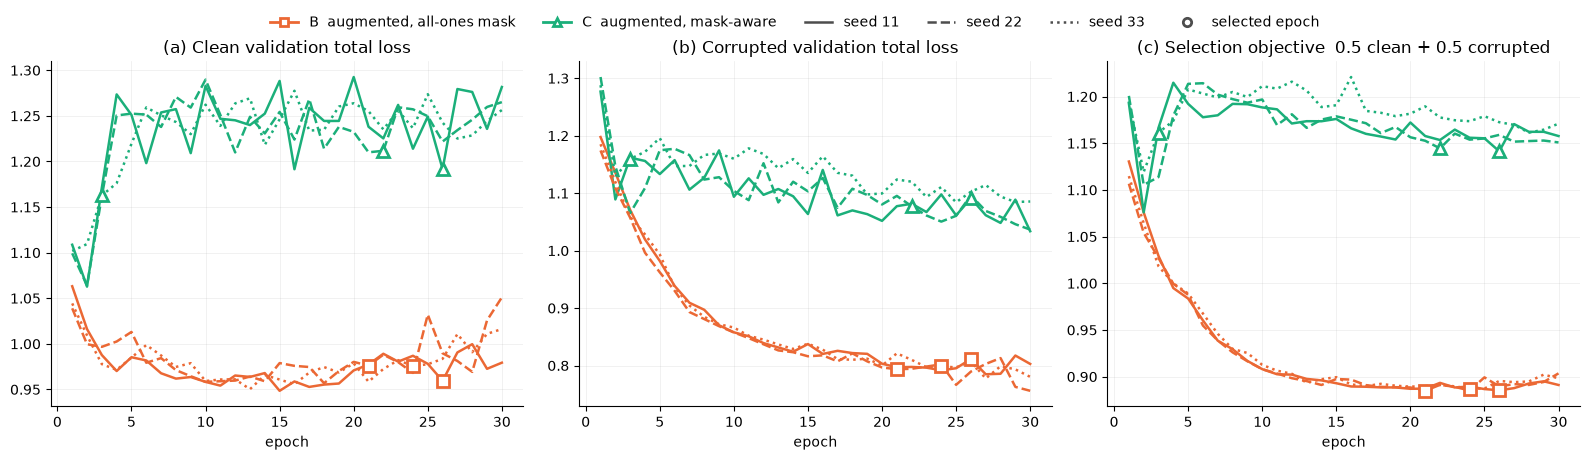

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharex=True)
panels = [("val_total_loss", "(a) Clean validation total loss"),
          ("val_corrupted_total_loss", "(b) Corrupted validation total loss"),
          ("selection_objective", "(c) Selection objective  0.5 clean + 0.5 corrupted")]
seed_styles = dict(zip(SEEDS, ["-", "--", ":"]))
for ax, (key, title) in zip(axes, panels):
    for (m, s), h in histories.items():
        h = h[h["epoch"] > 0]
        ax.plot(h["epoch"], h[key], color=MODEL_COLORS[m], ls=seed_styles[s], lw=1.8)
        sel = h[h["selected"]]
        ax.plot(sel["epoch"], sel[key], MODEL_MARKERS[m], ms=8, mfc="white", mec=MODEL_COLORS[m], mew=2, zorder=5)
    ax.set(title=title, xlabel="epoch")
handles = ([Line2D([], [], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], mfc="white", mew=2, lw=2, label=MODEL_LABELS[m]) for m in ("B", "C")]
           + [Line2D([], [], color="0.3", ls=seed_styles[s], lw=1.8, label=f"seed {s}") for s in SEEDS]
           + [Line2D([], [], color="0.3", marker="o", mfc="white", mew=2, lw=0, label="selected epoch")])
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage4_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Missingness in the latent space (diagnostic).** During training, Model C reached a much higher SIGReg on the clean validation set and a lower effective rank of clean target embeddings than B, and its training prediction loss was lower. A plausible mechanism is that the mask-aware encoder spends latent capacity on **encoding missingness**. SIGReg sees clean and corrupted blocks together, so clean blocks would then occupy only part of the Gaussian, with less variance per dimension, which also lowers the absolute MSE. To test this, every history block of the fixed 4,096-window subset is encoded twice, clean and with the 40% schedule. For each model we compute:

- **shift**: mean $\lVert z^{\text{corr}}-z^{\text{clean}}\rVert$ of the same block, in units of the clean blocks' RMS spread;
- **missingness share of variance**: between-group (clean vs corrupted) variance divided by the total variance of all block embeddings;
- **linear probe**: accuracy of a logistic regression that detects corrupted blocks from $z$. It is trained on even-numbered machines and tested on odd ones; chance is 50%.

In [13]:
from sklearn.linear_model import LogisticRegression

probe_avail = EVAL_AVAILABILITY["independent_40"][DIAG_IDX]
probe_ctx, probe_target = val_ds.context[DIAG_IDX], val_ds.target[DIAG_IDX]
probe_machine = torch.as_tensor(timeline.machine_index[DIAG_IDX]).repeat_interleave(CONTEXT_LENGTH)
rows = []
for m in MODELS:
    for s in SEEDS:
        inp = policy_inputs(probe_ctx, probe_avail, probe_target, INPUT_MASK[m], FILL)
        with torch.no_grad():
            z_clean = models[(m, s)].encode_history(probe_ctx.to(DEVICE), torch.ones_like(probe_ctx).to(DEVICE)).cpu().reshape(-1, LATENT_DIM)
            z_corr = models[(m, s)].encode_history(inp["context"].to(DEVICE), inp["context_mask"].to(DEVICE)).cpu().reshape(-1, LATENT_DIM)
        hit = (probe_avail == 0).flatten(2).any(2).reshape(-1)  # blocks with >= 1 removed reading
        z_all = torch.cat([z_clean, z_corr[hit]])
        group = torch.cat([torch.zeros(len(z_clean)), torch.ones(int(hit.sum()))])
        mu, mu0, mu1 = z_all.mean(0), z_clean.mean(0), z_corr[hit].mean(0)
        between = ((group == 0).float().mean() * (mu0 - mu).square().sum() + (group == 1).float().mean() * (mu1 - mu).square().sum())
        total = z_all.var(0, unbiased=False).sum()
        mach = torch.cat([probe_machine, probe_machine[hit]])
        fit_rows = (mach % 2 == 0).numpy()
        clf = LogisticRegression(max_iter=2000).fit(z_all[fit_rows].numpy(), group[fit_rows].numpy())
        rows.append({"model": m, "seed": s,
                     "shift / clean RMS spread": ((z_corr - z_clean)[hit].norm(dim=1).mean() / z_clean.var(0).sum().sqrt()).item(),
                     "missingness share of variance": (between / total).item(),
                     "linear probe accuracy": clf.score(z_all[~fit_rows].numpy(), group[~fit_rows].numpy())})
missingness = pd.DataFrame(rows)
missingness_summary = missingness.groupby("model")[["shift / clean RMS spread", "missingness share of variance", "linear probe accuracy"]].agg(
    lambda v: pm(v, "{:.3f}"))
display(missingness.set_index(["model", "seed"]).round(3).unstack("model"))
display(missingness_summary)

shift / clean RMS spread               missingness share of variance  \
model                        A      B      C                             A   
seed                                                                         
11                       0.710  1.283  2.105                         0.005   
22                       0.722  1.200  2.099                         0.007   
33                       0.720  1.263  1.463                         0.006   

                    linear probe accuracy                
model      B      C                     A      B      C  
seed                                                     
11     0.009  0.003                 0.628  0.581  0.600  
22     0.006  0.001                 0.649  0.553  0.577  
33     0.008  0.029                 0.643  0.557  0.984

,shift / clean RMS spread,missingness share of variance,linear probe accuracy
model,,,
A,0.717 ± 0.007,0.006 ± 0.001,0.640 ± 0.011
B,1.249 ± 0.043,0.008 ± 0.002,0.564 ± 0.015
C,1.889 ± 0.369,0.011 ± 0.015,0.720 ± 0.229


**Reload in a fresh session.** As in Stage 3, a separate Python process loads all nine checkpoints with `load_checkpoint`. It computes outputs for 256 validation windows, clean and with 40% dropout under each model's mask policy, so the mask channels are exercised too. The outputs must match those in this kernel.

In [14]:
ref_avail = timeline.window_masks(SCHEDULES["independent_40"])[:256]
ref = {"clean": {k: getattr(val_ds, k)[:256] for k in ("context", "context_mask", "target", "target_mask")}}
for policy in ("ones", "mask"):
    ref[policy] = policy_inputs(val_ds.context[:256], ref_avail, val_ds.target[:256], policy, FILL)
with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    torch.save(ref, tmp / "inputs.pt")
    paths = {f"{m}{s}": (str(CHECKPOINTS[(m, s)]), INPUT_MASK[m]) for m in MODELS for s in SEEDS}
    script = textwrap.dedent(f'''
        import sys, torch
        sys.path.insert(0, {str(PROJECT_ROOT)!r})
        from src.training import load_checkpoint
        ref = torch.load({str(tmp / "inputs.pt")!r})
        out = {{}}
        for key, (path, policy) in {paths!r}.items():
            model, ck = load_checkpoint(path)
            with torch.no_grad():
                out[key] = {{"clean": model(**ref["clean"])["z_pred"], "corrupted": model(**ref[policy])["z_pred"], "epoch": ck["epoch"]}}
        torch.save(out, {str(tmp / "outputs.pt")!r})
    ''')
    proc = subprocess.run([sys.executable, "-c", script], capture_output=True, text=True, cwd=PROJECT_ROOT)
    assert proc.returncode == 0, proc.stderr
    fresh_out = torch.load(tmp / "outputs.pt")

rows = []
for m in MODELS:
    for s in SEEDS:
        with torch.no_grad():
            here_clean = models[(m, s)](**{k: v.to(DEVICE) for k, v in ref["clean"].items()})["z_pred"].cpu()
            here_corr = models[(m, s)](**{k: v.to(DEVICE) for k, v in ref[INPUT_MASK[m]].items()})["z_pred"].cpu()
        f = fresh_out[f"{m}{s}"]
        rows.append({"model": m, "seed": s, "epoch": f["epoch"], "max |diff| clean": (f["clean"] - here_clean).abs().max().item(),
                     "max |diff| 40% dropout": (f["corrupted"] - here_corr).abs().max().item()})
reload4 = pd.DataFrame(rows).set_index(["model", "seed"])
display(reload4)
reload4_ok = bool((reload4.filter(like="max |diff|") < 1e-6).all().all())
print(f"All nine checkpoints reload in a fresh process with identical outputs: {reload4_ok}")

epoch  max |diff| clean  max |diff| 40% dropout
model seed                                                 
A     11       16               0.0                     0.0
      22       20               0.0                     0.0
      33       21               0.0                     0.0
B     11       26               0.0                     0.0
      22       21               0.0                     0.0
      33       24               0.0                     0.0
C     11       26               0.0                     0.0
      22       22               0.0                     0.0
      33        3               0.0                     0.0

All nine checkpoints reload in a fresh process with identical outputs: True


### 8.6 Robustness evaluation

All three models are evaluated on the **same** 21,500 validation windows and the **same** seven availability schedules (8.1). For one model $k$ and window $i$:

$$e^{\text{clean}}_i=\tfrac1{32}\lVert \hat z_i^{\text{clean}}-z_i\rVert^2,\qquad e^{\text{corr}}_i=\tfrac1{32}\lVert \hat z_i^{\text{corr}}-z_i\rVert^2,\qquad s_i=\lVert\hat z_i-z_i\rVert_2\ \text{(surprise)},$$

where $z_i$ is the target embedding. The target is clean, so $z_i$ is **identical** for the clean and corrupted version of a window, and this is asserted below.

**Comparing different latent spaces.** Absolute MSE values of different models (and seeds) live in different latent spaces and are not compared directly. The robustness measure is each model's **relative MSE**, $\text{MSE}^{\text{corr}}/\text{MSE}^{\text{clean}}$, against its own clean baseline. The relative degradation is relative MSE − 1. For clean accuracy, the clean MSE is **normalized** by the model's own mean per-dimension variance of the validation target embeddings, giving the share of target variance the predictor does not explain (1 = no better than predicting the mean).

**Two sources of uncertainty.**

- *Seeds*: mean ± std over the three training seeds, i.e. variation of the training run.
- *Machines*: windows overlap and share their machine's regime, so they are not independent. Uncertainty over the monitored population is estimated with a **machine-level bootstrap**: 2,000 replicates resampling the 100 machines, with the same resample for every model. It is reported for the paired model differences.

In [15]:
show_location(paired_metrics)
SCORES, TARGET_EMB = {}, {}
same_target, same_values = True, True
for m in MODELS:
    for s in SEEDS:
        for name in SCENARIOS:
            inputs = policy_inputs(val_ds.context, EVAL_AVAILABILITY[name], val_ds.target, INPUT_MASK[m], FILL)
            out = predict(models[(m, s)], inputs, DEVICE)
            if name == "clean":
                TARGET_EMB[(m, s)] = out["z_target"]
            else:
                same_target &= torch.equal(out["z_target"], TARGET_EMB[(m, s)])
            SCORES[(m, s, name)] = window_scores(out)
for name in SCENARIOS:  # A, B and C receive identical value tensors; only the mask channels differ (C)
    a = policy_inputs(val_ds.context, EVAL_AVAILABILITY[name], val_ds.target, "ones", FILL)
    c = policy_inputs(val_ds.context, EVAL_AVAILABILITY[name], val_ds.target, "mask", FILL)
    same_values &= torch.equal(a["context"], c["context"]) and torch.equal(a["target"], c["target"])
print(f"Same target embedding for every clean/corrupted pair: {same_target}; identical value tensors for A/B/C: {same_values}")

TARGET_VAR = {k: v.var(dim=0).mean().item() for k, v in TARGET_EMB.items()}  # mean per-dimension variance of z_t+1
robust = pd.DataFrame([{"model": m, "seed": s, "scenario": name,
                        **paired_metrics(SCORES[(m, s, "clean")], SCORES[(m, s, name)], AFFECTED[name]),
                        "target_variance": TARGET_VAR[(m, s)],
                        "clean_mse_normalized": SCORES[(m, s, "clean")]["mse"].mean().item() / TARGET_VAR[(m, s)]}
                       for m in MODELS for s in SEEDS for name in SCENARIOS])
robust_mean = robust.groupby(["model", "scenario"], sort=False).mean(numeric_only=True).drop(columns="seed")
robust_std = robust.groupby(["model", "scenario"], sort=False).std(numeric_only=True).drop(columns="seed")


def pm_table(metric, fmt="{:.3f}"):
    # scenario x model table of "mean ± std" over seeds
    return pd.DataFrame({m: {n: f"{fmt.format(robust_mean.loc[(m, n), metric])} ± {fmt.format(robust_std.loc[(m, n), metric])}"
                             for n in SCENARIOS} for m in MODELS})


clean_rows = robust[robust["scenario"] == "clean"].set_index(["model", "seed"])
print("Clean validation MSE in each model's own latent space, and normalized by its target-embedding variance")
display(clean_rows[["clean_mse", "target_variance", "clean_mse_normalized"]].unstack("model").round(4))
print("Relative MSE (corrupted / own clean MSE), mean ± std over seeds")
display(pm_table("relative_mse"))
print("Relative MSE on affected windows only (at least one removed reading in the context)")
display(pm_table("relative_mse_affected"))
print("Per-window error change e_corr - e_clean: median, and share of affected windows whose error increased")
display(pd.concat({"median change": pm_table("window_error_change_median", "{:.4f}"),
                   "share increased": pm_table("windows_error_increased_affected", "{:.1%}")}, axis=1))
print("Relative change of the mean surprise score (mean s_corr / mean s_clean - 1)")
display(pm_table("relative_surprise_change", "{:.1%}"))

Using paired_metrics from src/evaluation/robustness.py, line 36
Same target embedding for every clean/corrupted pair: True; identical value tensors for A/B/C: True
Clean validation MSE in each model's own latent space, and normalized by its target-embedding variance


clean_mse                 target_variance                  \
model         A       B       C               A       B       C   
seed                                                              
11       0.6818  0.6101  0.4178          0.8027  0.7146  0.5132   
22       0.6715  0.5850  0.4160          0.7917  0.6810  0.5079   
33       0.6768  0.5939  0.5418          0.7996  0.6989  0.6186   

      clean_mse_normalized                  
model                    A       B       C  
seed                                        
11                  0.8494  0.8537  0.8141  
22                  0.8482  0.8591  0.8191  
33                  0.8464  0.8497  0.8758

Relative MSE (corrupted / own clean MSE), mean ± std over seeds


,A,B,C
clean,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
independent_10,1.011 ± 0.002,1.003 ± 0.001,1.005 ± 0.001
independent_20,1.025 ± 0.004,1.010 ± 0.001,1.012 ± 0.001
independent_40,1.072 ± 0.007,1.032 ± 0.002,1.031 ± 0.001
burst_6h,1.012 ± 0.001,1.007 ± 0.001,1.006 ± 0.001
burst_12h,1.021 ± 0.000,1.018 ± 0.000,1.018 ± 0.001
outage,1.015 ± 0.001,1.013 ± 0.000,1.014 ± 0.002


Relative MSE on affected windows only (at least one removed reading in the context)


,A,B,C
clean,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
independent_10,1.011 ± 0.002,1.003 ± 0.001,1.005 ± 0.001
independent_20,1.025 ± 0.004,1.010 ± 0.001,1.012 ± 0.001
independent_40,1.072 ± 0.007,1.032 ± 0.002,1.031 ± 0.001
burst_6h,1.014 ± 0.001,1.009 ± 0.001,1.007 ± 0.001
burst_12h,1.022 ± 0.000,1.019 ± 0.000,1.019 ± 0.001
outage,1.019 ± 0.001,1.016 ± 0.000,1.017 ± 0.003


Per-window error change e_corr - e_clean: median, and share of affected windows whose error increased


median change                                    \
                              A                B                C   
clean           0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
independent_10  0.0001 ± 0.0001  0.0000 ± 0.0001  0.0001 ± 0.0001   
independent_20  0.0002 ± 0.0001  0.0001 ± 0.0001  0.0002 ± 0.0002   
independent_40  0.0006 ± 0.0002  0.0002 ± 0.0001  0.0006 ± 0.0006   
burst_6h        0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
burst_12h       0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
outage          0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   

               share increased                              
                             A             B             C  
clean              nan% ± nan%   nan% ± nan%   nan% ± nan%  
independent_10    50.2% ± 0.2%  50.1% ± 0.8%  50.7% ± 0.5%  
independent_20    50.6% ± 0.4%  50.4% ± 0.5%  51.3% ± 0.8%  
independent_40    51.2% ± 0.3%  50.7% ± 0.3%  52.4% ± 1.4%  
burst_6h          50.0% ± 0.6%  50.2% ± 0.1%  50.5% ± 0.3%  
burst_12h         50.4% ± 0.4%  50.6% ± 0.6%  51.1% ± 0.5%  
outage            50.1% ± 0.4%  50.3% ± 0.8%  51.2% ± 0.2%

Relative change of the mean surprise score (mean s_corr / mean s_clean - 1)


,A,B,C
clean,0.0% ± 0.0%,0.0% ± 0.0%,0.0% ± 0.0%
independent_10,0.6% ± 0.1%,0.2% ± 0.0%,0.3% ± 0.0%
independent_20,1.3% ± 0.2%,0.6% ± 0.0%,0.7% ± 0.0%
independent_40,3.6% ± 0.3%,2.0% ± 0.0%,1.7% ± 0.1%
burst_6h,0.5% ± 0.0%,0.4% ± 0.0%,0.3% ± 0.0%
burst_12h,1.0% ± 0.0%,0.9% ± 0.0%,0.9% ± 0.1%
outage,0.7% ± 0.0%,0.7% ± 0.0%,0.6% ± 0.1%


In [16]:
show_location(bootstrap_weights)
boot_cfg = S4["evaluation"]["bootstrap"]
W = bootstrap_weights(timeline.num_machines, boot_cfg["replicates"], boot_cfg["seed"])  # one resample set for every model
M_IDX = timeline.machine_index


def boot_relative_mse(m, name):
    # [replicates]: relative MSE averaged over seeds, recomputed for every machine resample
    reps = [weighted_ratio(machine_sums(SCORES[(m, s, name)]["mse"], M_IDX, timeline.num_machines),
                           machine_sums(SCORES[(m, s, "clean")]["mse"], M_IDX, timeline.num_machines), W) for s in SEEDS]
    return torch.stack(reps).mean(0).numpy()


COMPARISONS = [("B", "C"), ("A", "C"), ("A", "B")]
rows = []
for first, second in COMPARISONS:
    for name in SCENARIOS[1:]:
        per_seed = [robust.query("model == @first and seed == @s and scenario == @name")["relative_mse"].item()
                    - robust.query("model == @second and seed == @s and scenario == @name")["relative_mse"].item() for s in SEEDS]
        diff = boot_relative_mse(first, name) - boot_relative_mse(second, name)
        lo, hi = interval(diff)
        rows.append({"comparison": f"{first} - {second}", "scenario": name, "difference in relative MSE": np.mean(per_seed),
                     "seed std": np.std(per_seed, ddof=1), "seeds with difference > 0": f"{sum(d > 0 for d in per_seed)} of {len(SEEDS)}",
                     "machine bootstrap 95% CI": f"[{lo:.4f}, {hi:.4f}]", "CI excludes 0": bool(lo > 0 or hi < 0)})
mse_differences = pd.DataFrame(rows).set_index(["comparison", "scenario"])
print("Paired differences of relative MSE (> 0: the second model degrades less)")
display(mse_differences.round(4))

Using bootstrap_weights from src/evaluation/robustness.py, line 79
Paired differences of relative MSE (> 0: the second model degrades less)


difference in relative MSE  seed std  \
comparison scenario                                               
B - C      independent_10                     -0.0021    0.0009   
           independent_20                     -0.0024    0.0022   
           independent_40                      0.0015    0.0026   
           burst_6h                            0.0013    0.0006   
           burst_12h                          -0.0002    0.0014   
           outage                             -0.0011    0.0023   
A - C      independent_10                      0.0052    0.0013   
           independent_20                      0.0130    0.0027   
           independent_40                      0.0415    0.0064   
           burst_6h                            0.0054    0.0001   
           burst_12h                           0.0034    0.0015   
           outage                              0.0012    0.0026   
A - B      independent_10                      0.0074    0.0021   
           independent_20                      0.0155    0.0044   
           independent_40                      0.0400    0.0072   
           burst_6h                            0.0041    0.0007   
           burst_12h                           0.0035    0.0004   
           outage                              0.0024    0.0004   

                          seeds with difference > 0 machine bootstrap 95% CI  \
comparison scenario                                                            
B - C      independent_10                    0 of 3       [-0.0031, -0.0013]   
           independent_20                    0 of 3       [-0.0041, -0.0008]   
           independent_40                    2 of 3        [-0.0004, 0.0037]   
           burst_6h                          3 of 3         [0.0002, 0.0024]   
           burst_12h                         1 of 3        [-0.0017, 0.0014]   
           outage                            1 of 3        [-0.0024, 0.0000]   
A - C      independent_10                    3 of 3         [0.0036, 0.0068]   
           independent_20                    3 of 3         [0.0101, 0.0160]   
           independent_40                    3 of 3         [0.0357, 0.0477]   
           burst_6h                          3 of 3         [0.0035, 0.0074]   
           burst_12h                         3 of 3         [0.0010, 0.0059]   
           outage                            2 of 3        [-0.0000, 0.0026]   
A - B      independent_10                    3 of 3         [0.0059, 0.0088]   
           independent_20                    3 of 3         [0.0129, 0.0181]   
           independent_40                    3 of 3         [0.0348, 0.0452]   
           burst_6h                          3 of 3         [0.0029, 0.0055]   
           burst_12h                         3 of 3         [0.0019, 0.0053]   
           outage                            3 of 3         [0.0010, 0.0038]   

                           CI excludes 0  
comparison scenario                       
B - C      independent_10           True  
           independent_20           True  
           independent_40          False  
           burst_6h                 True  
           burst_12h               False  
           outage                  False  
A - C      independent_10           True  
           independent_20           True  
           independent_40           True  
           burst_6h                 True  
           burst_12h                True  
           outage                  False  
A - B      independent_10           True  
           independent_20           True  
           independent_40           True  
           burst_6h                 True  
           burst_12h                True  
           outage                   True

### 8.7 Surprise-score and alert analysis

**Surprise** is $s_i=\lVert\hat z_{t+1}-z_{t+1}\rVert_2$. For every model and seed, the alert threshold $\tau$ is the **95th percentile of its clean-validation surprise**. $\tau$ is then held fixed for all corrupted versions of the same windows, so on clean data the alert rate is 5% by construction. Any increase is the share of windows that **dropouts alone** push over a threshold the model would use in operation.

A second check calibrates $\tau$ on the first half of the validation period and applies it to the clean second half. It shows how well the 5% calibration transfers in time.

**Failure-negative proxy subset.** The rule was fixed in `configs/stage4.yaml` before evaluation. A window counts as *proxy-normal* if its machine has

- no recorded failure in [context start − 48 h, target end + 48 h], and
- no maintenance in [context start − 24 h, target end].

Labels are used **only** to select these windows: never for training, thresholds or model selection. Alerts on proxy-normal windows are false-alarm *proxies*. A window without a recorded failure is not guaranteed to be normal, and an alert is not a detected failure. This is a controlled robustness experiment, not the failure-detection study of Stage 5.

In [17]:
show_location(alert_threshold)
show_location(proxy_normal_windows)
failures = pd.read_csv(PROCESSED_DIR / "failure_events.csv", parse_dates=["datetime"])
maintenance = pd.read_csv(PROCESSED_DIR / "maintenance_events.csv", parse_dates=["datetime"])
PROXY = proxy_normal_windows(val_meta, failures, maintenance, S4["alerts"]["proxy_normal"])
PCT = S4["alerts"]["percentile"]
print(f"Proxy-normal validation windows: {PROXY.sum():,} of {N_VAL:,} ({PROXY.mean():.1%}); rule {S4['alerts']['proxy_normal']}")

THRESHOLDS, rows = {}, []
first_half = (pd.to_datetime(val_meta["target_start"]) < pd.to_datetime(val_meta["target_start"]).median()).to_numpy().copy()
for m in MODELS:
    for s in SEEDS:
        clean_s = SCORES[(m, s, "clean")]["surprise"]
        tau = THRESHOLDS[(m, s)] = alert_threshold(clean_s, PCT)
        tau_half = alert_threshold(clean_s[torch.from_numpy(first_half)], PCT)
        for name in SCENARIOS:
            s_corr = SCORES[(m, s, name)]["surprise"]
            rows.append({"model": m, "seed": s, "scenario": name, "alert_threshold": tau,
                         "alert_rate": alert_rate(s_corr, tau), "alert_rate_change": alert_rate(s_corr, tau) - alert_rate(clean_s, tau),
                         "alert_rate_affected": alert_rate(s_corr, tau, AFFECTED[name]) if AFFECTED[name].any() else np.nan,
                         "proxy_normal_alert_rate": alert_rate(s_corr, tau, PROXY),
                         "proxy_normal_alert_rate_change": alert_rate(s_corr, tau, PROXY) - alert_rate(clean_s, tau, PROXY),
                         "holdout_clean_alert_rate": alert_rate(clean_s, tau_half, ~first_half) if name == "clean" else np.nan})
alerts = pd.DataFrame(rows)
robust = robust.merge(alerts, on=["model", "seed", "scenario"])
robust.to_csv(RESULTS_DIR / "stage4_robustness_metrics.csv", index=False)
robust_mean = robust.groupby(["model", "scenario"], sort=False).mean(numeric_only=True).drop(columns="seed")
robust_std = robust.groupby(["model", "scenario"], sort=False).std(numeric_only=True).drop(columns="seed")
print(f"Saved {len(robust)} rows (3 models x {len(SEEDS)} seeds x {len(SCENARIOS)} scenarios) to results/stage4_robustness_metrics.csv")

print("\nAlert rate with the clean-calibrated threshold (all validation windows), mean ± std over seeds")
display(pm_table("alert_rate", "{:.1%}"))
print("Alert rate on proxy-normal windows (false-alarm proxy)")
display(pm_table("proxy_normal_alert_rate", "{:.1%}"))
holdout = alerts[alerts["scenario"] == "clean"].groupby("model")["holdout_clean_alert_rate"].agg(["mean", "std"])
print("Calibration transfer: threshold from the first half of validation, clean alert rate on the second half")
display(holdout.style.format("{:.1%}"))

Using alert_threshold from src/evaluation/robustness.py, line 61
Using proxy_normal_windows from src/evaluation/robustness.py, line 105
Proxy-normal validation windows: 17,524 of 21,500 (81.5%); rule {'failure_before_hours': 48, 'failure_after_hours': 48, 'maintenance_before_hours': 24, 'maintenance_after_hours': 0}
Saved 63 rows (3 models x 3 seeds x 7 scenarios) to results/stage4_robustness_metrics.csv

Alert rate with the clean-calibrated threshold (all validation windows), mean ± std over seeds


,A,B,C
clean,5.0% ± 0.0%,5.0% ± 0.0%,5.0% ± 0.0%
independent_10,5.4% ± 0.1%,5.0% ± 0.0%,5.2% ± 0.1%
independent_20,5.8% ± 0.2%,5.1% ± 0.1%,5.4% ± 0.1%
independent_40,7.5% ± 0.3%,5.5% ± 0.1%,5.9% ± 0.2%
burst_6h,5.4% ± 0.0%,5.2% ± 0.0%,5.2% ± 0.1%
burst_12h,5.8% ± 0.0%,5.5% ± 0.0%,5.6% ± 0.1%
outage,5.6% ± 0.0%,5.4% ± 0.0%,5.5% ± 0.0%


Alert rate on proxy-normal windows (false-alarm proxy)


,A,B,C
clean,4.3% ± 0.1%,4.7% ± 0.0%,4.4% ± 0.1%
independent_10,4.5% ± 0.1%,4.6% ± 0.1%,4.6% ± 0.2%
independent_20,4.8% ± 0.2%,4.7% ± 0.1%,4.7% ± 0.3%
independent_40,6.1% ± 0.2%,5.1% ± 0.1%,5.1% ± 0.3%
burst_6h,4.6% ± 0.0%,4.8% ± 0.1%,4.6% ± 0.2%
burst_12h,4.9% ± 0.1%,5.1% ± 0.0%,5.0% ± 0.2%
outage,4.6% ± 0.0%,4.9% ± 0.0%,4.8% ± 0.2%


Calibration transfer: threshold from the first half of validation, clean alert rate on the second half


,mean,std
model,,
A,5.2%,0.4%
B,5.1%,0.2%
C,5.4%,0.1%


In [18]:
def boot_alert_change(m, name):
    # [replicates]: alert-rate change (corrupted - clean), averaged over seeds, per machine resample
    count = machine_sums(torch.ones(N_VAL), M_IDX, timeline.num_machines)
    reps = []
    for s in SEEDS:
        tau = THRESHOLDS[(m, s)]
        corr = machine_sums((SCORES[(m, s, name)]["surprise"] > tau).double(), M_IDX, timeline.num_machines)
        clean = machine_sums((SCORES[(m, s, "clean")]["surprise"] > tau).double(), M_IDX, timeline.num_machines)
        reps.append(weighted_ratio(corr, count, W) - weighted_ratio(clean, count, W))
    return torch.stack(reps).mean(0).numpy()


rows = []
for first, second in COMPARISONS:
    for name in SCENARIOS[1:]:
        per_seed = [alerts.query("model == @first and seed == @s and scenario == @name")["alert_rate_change"].item()
                    - alerts.query("model == @second and seed == @s and scenario == @name")["alert_rate_change"].item() for s in SEEDS]
        lo, hi = interval(boot_alert_change(first, name) - boot_alert_change(second, name))
        rows.append({"comparison": f"{first} - {second}", "scenario": name, "difference in alert-rate change": np.mean(per_seed),
                     "seed std": np.std(per_seed, ddof=1), "seeds with difference > 0": f"{sum(d > 0 for d in per_seed)} of {len(SEEDS)}",
                     "machine bootstrap 95% CI": f"[{lo:.4f}, {hi:.4f}]", "CI excludes 0": bool(lo > 0 or hi < 0)})
alert_differences = pd.DataFrame(rows).set_index(["comparison", "scenario"])
print("Paired differences of the alert-rate increase (> 0: the second model raises fewer dropout-induced alerts)")
display(alert_differences.round(4))

Paired differences of the alert-rate increase (> 0: the second model raises fewer dropout-induced alerts)


difference in alert-rate change  seed std  \
comparison scenario                                                    
B - C      independent_10                          -0.0021    0.0008   
           independent_20                          -0.0028    0.0005   
           independent_40                          -0.0035    0.0018   
           burst_6h                                -0.0006    0.0006   
           burst_12h                               -0.0013    0.0010   
           outage                                  -0.0013    0.0003   
A - C      independent_10                           0.0017    0.0004   
           independent_20                           0.0047    0.0016   
           independent_40                           0.0163    0.0010   
           burst_6h                                 0.0021    0.0010   
           burst_12h                                0.0015    0.0014   
           outage                                   0.0006    0.0003   
A - B      independent_10                           0.0038    0.0007   
           independent_20                           0.0075    0.0020   
           independent_40                           0.0197    0.0019   
           burst_6h                                 0.0027    0.0004   
           burst_12h                                0.0028    0.0006   
           outage                                   0.0019    0.0005   

                          seeds with difference > 0 machine bootstrap 95% CI  \
comparison scenario                                                            
B - C      independent_10                    0 of 3       [-0.0031, -0.0012]   
           independent_20                    0 of 3       [-0.0040, -0.0015]   
           independent_40                    0 of 3       [-0.0048, -0.0021]   
           burst_6h                          0 of 3        [-0.0014, 0.0002]   
           burst_12h                         0 of 3       [-0.0024, -0.0002]   
           outage                            0 of 3       [-0.0024, -0.0002]   
A - C      independent_10                    3 of 3         [0.0004, 0.0031]   
           independent_20                    3 of 3         [0.0029, 0.0065]   
           independent_40                    3 of 3         [0.0137, 0.0191]   
           burst_6h                          3 of 3         [0.0009, 0.0033]   
           burst_12h                         3 of 3         [0.0002, 0.0027]   
           outage                            3 of 3        [-0.0005, 0.0016]   
A - B      independent_10                    3 of 3         [0.0026, 0.0051]   
           independent_20                    3 of 3         [0.0058, 0.0092]   
           independent_40                    3 of 3         [0.0170, 0.0226]   
           burst_6h                          3 of 3         [0.0017, 0.0037]   
           burst_12h                         3 of 3         [0.0015, 0.0040]   
           outage                            3 of 3         [0.0009, 0.0030]   

                           CI excludes 0  
comparison scenario                       
B - C      independent_10           True  
           independent_20           True  
           independent_40           True  
           burst_6h                False  
           burst_12h                True  
           outage                   True  
A - C      independent_10           True  
           independent_20           True  
           independent_40           True  
           burst_6h                 True  
           burst_12h                True  
           outage                  False  
A - B      independent_10           True  
           independent_20           True  
           independent_40           True  
           burst_6h                 True  
           burst_12h                True  
           outage                   True

### 8.8 Temporal-information checks

These two diagnostics use **clean** validation contexts, all-ones masks and the trained models, without retraining. They are separate from the dropout experiment.

- **A. Historical order perturbation.** The four historical blocks are reordered: *reversed* puts the newest block first, and *shuffled* uses a seeded random non-identity permutation per window. The target is unchanged. A model that uses the order of its history should get worse.
- **B. Same-machine mismatched history.** The context is replaced by the context of another window of the **same machine**, at least 20 windows (120 h) away, so it shares no hours with the original target block. The target is unchanged. A model that uses the specific recent history, not just the machine's typical level, should get worse.

The measure is again each model's own relative MSE. An increase is evidence that the predictor **uses** this information. It is not proof that the latent model has learned physical or causal dynamics.

In [19]:
show_location(block_permutations)
show_location(mismatched_history_indices)
tcfg = S4["temporal_checks"]
perms = {kind: block_permutations(N_VAL, kind, make_generator(tcfg["seed"], kind), CONTEXT_LENGTH) for kind in tcfg["order_perturbations"]}
mismatch = mismatched_history_indices(timeline, tcfg["mismatch_min_separation_windows"], make_generator(tcfg["seed"], "mismatch"))
off = torch.as_tensor(timeline.offset)
mismatch_ok = bool((torch.as_tensor(timeline.machine_index)[mismatch] == torch.as_tensor(timeline.machine_index)).all()
                   and ((torch.as_tensor(timeline.position)[mismatch] - torch.as_tensor(timeline.position)).abs() >= tcfg["mismatch_min_separation_windows"]).all()
                   # replacement context [off_j, off_j + 24) never overlaps the original target [off_i + 24, off_i + 30)
                   and ((off[mismatch] + 24 <= off + 24) | (off[mismatch] >= off + 30)).all())
print(f"Shuffled orders are never the identity: {bool((perms['shuffled'] != torch.arange(CONTEXT_LENGTH)).any(1).all())}; "
      f"mismatched histories: same machine, >= {tcfg['mismatch_min_separation_windows']} windows apart, no overlap with the target: {mismatch_ok}")

ones = torch.ones_like(val_ds.context)
VARIANTS = {"reversed order": permute_blocks(val_ds.context, perms["reversed"]),
            "shuffled order": permute_blocks(val_ds.context, perms["shuffled"]),
            "mismatched history (same machine)": val_ds.context[mismatch]}
rows = []
for m in MODELS:
    for s in SEEDS:
        clean_mse = SCORES[(m, s, "clean")]["mse"]
        for name, ctx in VARIANTS.items():
            sc = window_scores(predict(models[(m, s)], {"context": ctx, "context_mask": ones, "target": val_ds.target,
                                                        "target_mask": val_ds.target_mask}, DEVICE))
            rows.append({"model": m, "seed": s, "perturbation": name, "relative MSE": (sc["mse"].mean() / clean_mse.mean()).item(),
                         "windows with higher error": (sc["mse"] > clean_mse).float().mean().item()})
temporal = pd.DataFrame(rows)
temporal_summary = pd.concat({
    "relative MSE": temporal.groupby(["perturbation", "model"], sort=False)["relative MSE"].agg(pm).unstack(),
    "windows with higher error": temporal.groupby(["perturbation", "model"], sort=False)["windows with higher error"]
                                         .agg(lambda v: pm(v, "{:.1%}")).unstack(),
}, axis=1)
display(temporal_summary)

Using block_permutations from src/evaluation/robustness.py, line 129
Using mismatched_history_indices from src/evaluation/robustness.py, line 149
Shuffled orders are never the identity: True; mismatched histories: same machine, >= 20 windows apart, no overlap with the target: True


relative MSE                 \
model                                          A              B   
perturbation                                                      
reversed order                     1.167 ± 0.005  1.153 ± 0.007   
shuffled order                     1.084 ± 0.002  1.074 ± 0.002   
mismatched history (same machine)  1.402 ± 0.005  1.375 ± 0.019   

                                                 windows with higher error  \
model                                          C                         A   
perturbation                                                                 
reversed order                     1.174 ± 0.040              54.2% ± 0.1%   
shuffled order                     1.085 ± 0.020              52.3% ± 0.0%   
mismatched history (same machine)  1.425 ± 0.078              60.1% ± 0.2%   

                                                               
model                                         B             C  
perturbation                                                   
reversed order                     54.7% ± 0.2%  54.9% ± 0.2%  
shuffled order                     53.2% ± 0.4%  53.3% ± 0.2%  
mismatched history (same machine)  60.6% ± 0.1%  60.8% ± 0.1%

### 8.9 Figures, tables and Stage 4 validation

**Figure A** shows the relative prediction-error degradation against independent-dropout severity, and **Figure B** the clean-calibrated alert rate against the same severity. Lines are seed means, error bars ± 1 std over seeds, and small markers the individual seeds. **Figure C** compares the three corruption patterns. Bursts and outages were never seen in training.

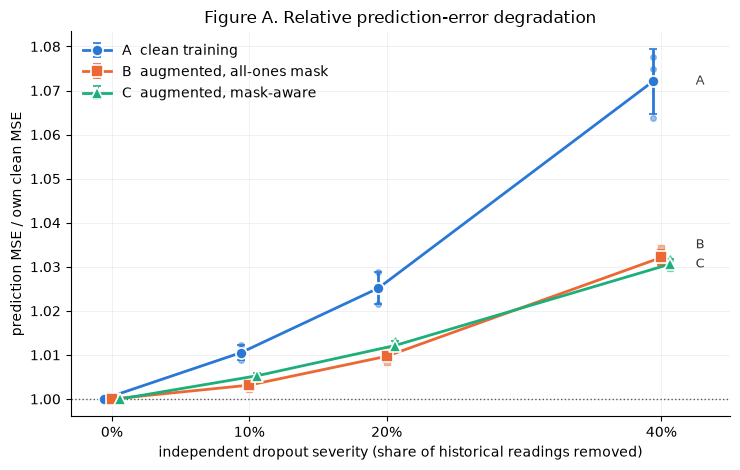

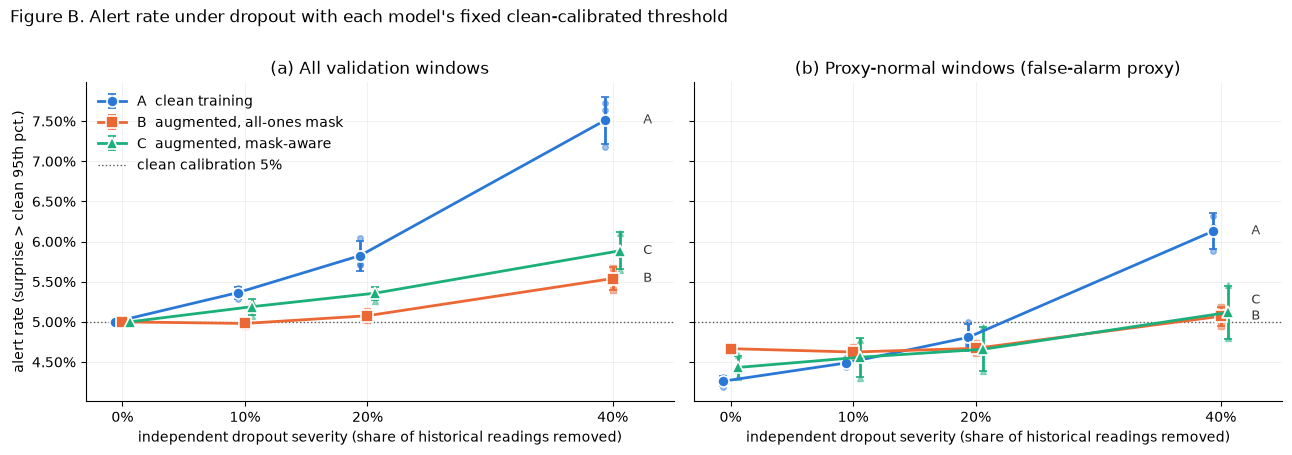

In [20]:
x = [100 * SEVERITY[n] for n in INDEPENDENT]


def severity_panel(ax, metric, scale=1.0):
    ends = {}
    for m in MODELS:
        mean = np.array([robust_mean.loc[(m, n), metric] for n in INDEPENDENT]) * scale
        std = np.array([robust_std.loc[(m, n), metric] for n in INDEPENDENT]) * scale
        offset = {"A": -0.6, "B": 0.0, "C": 0.6}[m]  # small horizontal dodge so error bars do not overlap
        ax.errorbar(np.array(x) + offset, mean, yerr=std, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], ms=8, lw=2,
                    capsize=3, mec="white", mew=1.2, label=MODEL_LABELS[m], zorder=3)
        for s in SEEDS:
            vals = [robust.query("model == @m and seed == @s and scenario == @n")[metric].item() * scale for n in INDEPENDENT]
            ax.plot(np.array(x) + offset, vals, MODEL_MARKERS[m], ms=4, color=MODEL_COLORS[m], alpha=0.45, zorder=2)
        ends[m] = mean[-1]
    # Direct labels at the right end, pushed apart vertically where lines finish close together.
    lo, hi = ax.get_ylim()
    placed = []
    for m in sorted(ends, key=ends.get):
        y = ends[m] if not placed else max(ends[m], placed[-1] + 0.05 * (hi - lo))
        placed.append(y)
        ax.text(x[-1] + 2.5, y, m, va="center", fontsize=9, color="0.2")
    ax.set_xlim(x[0] - 3, x[-1] + 5)
    ax.set_xticks(x, [f"{v:.0f}%" for v in x])
    ax.set_xlabel("independent dropout severity (share of historical readings removed)")


fig, ax = plt.subplots(figsize=(7.5, 4.8))
severity_panel(ax, "relative_mse")
ax.axhline(1, color="0.35", lw=1, ls=":")
ax.set(ylabel="prediction MSE / own clean MSE", title="Figure A. Relative prediction-error degradation")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage4_robustness_curves.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
severity_panel(axes[0], "alert_rate")
severity_panel(axes[1], "proxy_normal_alert_rate")
for ax, title in zip(axes, ["(a) All validation windows", "(b) Proxy-normal windows (false-alarm proxy)"]):
    ax.axhline(1 - PCT / 100, color="0.35", lw=1, ls=":")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)
axes[0].set_ylabel(f"alert rate (surprise > clean {PCT}th pct.)")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles + [Line2D([], [], color="0.35", lw=1, ls=":")], labels + [f"clean calibration {100 - PCT}%"],
               frameon=False, loc="upper left")
fig.suptitle("Figure B. Alert rate under dropout with each model's fixed clean-calibrated threshold", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIGURES_DIR / "stage4_alert_rates.png", dpi=150, bbox_inches="tight")
plt.show()

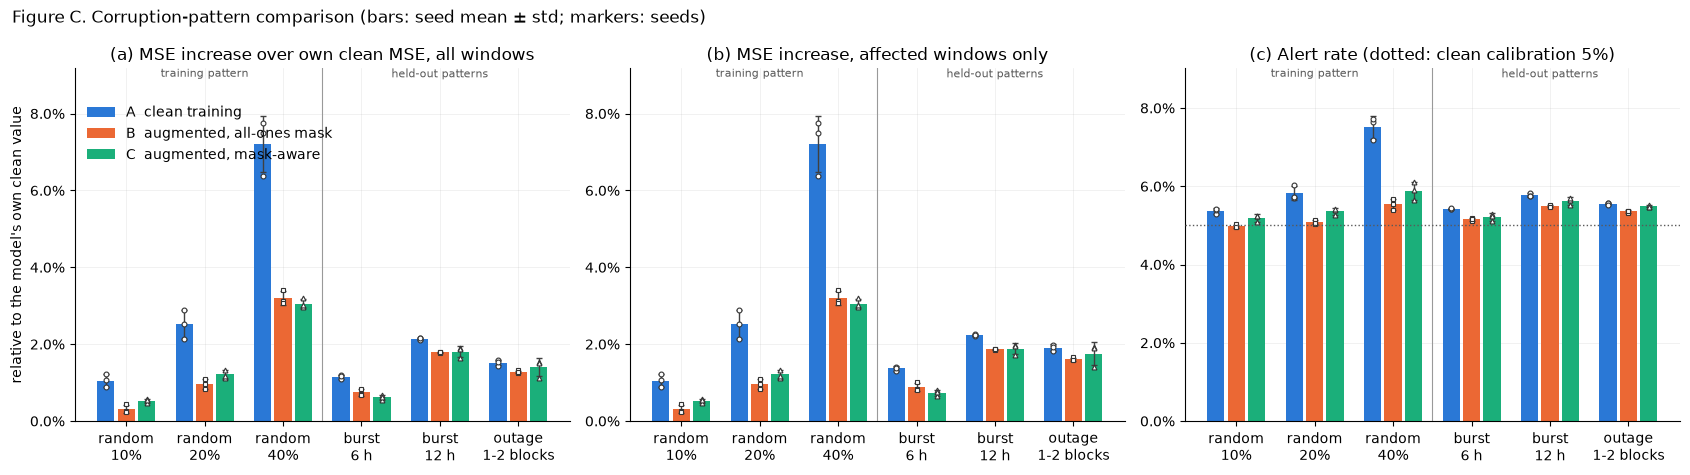

In [21]:
patterns = SCENARIOS[1:]
pattern_labels = {"independent_10": "random\n10%", "independent_20": "random\n20%", "independent_40": "random\n40%",
                  "burst_6h": "burst\n6 h", "burst_12h": "burst\n12 h", "outage": "outage\n1-2 blocks"}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
metrics = [("relative_mse", "(a) MSE increase over own clean MSE, all windows", 1.0),
           ("relative_mse_affected", "(b) MSE increase, affected windows only", 1.0),
           ("alert_rate", f"(c) Alert rate (dotted: clean calibration {100 - PCT}%)", 0.0)]
pos, width = np.arange(len(patterns)), 0.26
for ax, (metric, title, base) in zip(axes, metrics):
    for j, m in enumerate(MODELS):
        mean = [robust_mean.loc[(m, n), metric] - base for n in patterns]
        std = [robust_std.loc[(m, n), metric] for n in patterns]
        ax.bar(pos + (j - 1) * width, mean, width - 0.04, yerr=std, color=MODEL_COLORS[m], label=MODEL_LABELS[m],
               error_kw={"lw": 1, "capsize": 2, "ecolor": "0.25"}, zorder=2)
        for s in SEEDS:
            vals = [robust.query("model == @m and seed == @s and scenario == @n")[metric].item() - base for n in patterns]
            ax.plot(pos + (j - 1) * width, vals, MODEL_MARKERS[m], ms=3.5, mfc="white", mec="0.2", mew=0.8, lw=0, zorder=3)
    if metric == "alert_rate":
        ax.axhline(1 - PCT / 100, color="0.35", lw=1, ls=":", zorder=4)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.axvline(2.5, color="0.6", lw=0.8)
    ax.text(1, ax.get_ylim()[1], "training pattern", ha="center", va="top", fontsize=8, color="0.35")
    ax.text(4, ax.get_ylim()[1], "held-out patterns", ha="center", va="top", fontsize=8, color="0.35")
    ax.set_xticks(pos, [pattern_labels[n] for n in patterns])
    ax.set_title(title)
axes[0].set_ylabel("relative to the model's own clean value")
axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.93))
fig.suptitle("Figure C. Corruption-pattern comparison (bars: seed mean ± std; markers: seeds)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "stage4_corruption_patterns.png", dpi=150, bbox_inches="tight")
plt.show()

**Table A** is the main three-model comparison and **Table B** the training diagnostics. Values are mean ± std over the three seeds; both tables are also saved as CSV.

In [22]:
table_a = {}
for m in MODELS:
    clean_q = robust.query("model == @m and scenario == 'clean'")
    row = {"clean val MSE": pm(clean_q["clean_mse"], "{:.4f}"),
           "clean MSE / target variance": pm(clean_q["clean_mse_normalized"], "{:.3f}")}
    for n in INDEPENDENT[1:]:
        q = robust.query("model == @m and scenario == @n")
        pct = f"{100 * SEVERITY[n]:.0f}%"
        row[f"MSE {pct}"] = pm(q["corrupted_mse"], "{:.4f}")
    for n in INDEPENDENT[1:]:
        row[f"degradation {100 * SEVERITY[n]:.0f}%"] = pm(robust.query("model == @m and scenario == @n")["relative_degradation"] * 100, "{:.1f}") + " %"
    for n in INDEPENDENT[1:]:
        row[f"alert-rate change {100 * SEVERITY[n]:.0f}%"] = pm(robust.query("model == @m and scenario == @n")["alert_rate_change"] * 100, "{:+.1f}") + " pp"
    for n in ("burst_6h", "burst_12h", "outage"):
        row[f"degradation {n}"] = pm(robust.query("model == @m and scenario == @n")["relative_degradation"] * 100, "{:.1f}") + " %"
    table_a[MODEL_LABELS[m]] = row
table_a = pd.DataFrame(table_a).T
table_a.index.name = "model"
table_a.to_csv(RESULTS_DIR / "stage4_table_a.csv")
print("Table A. Three-model comparison on validation (absolute MSE values are within-model only; compare degradations)")
display(table_a.T)

table_b = training_table[["selected epoch", "selection objective", "val clean total", "val corrupted total", "val SIGReg",
                          "effective rank", "min latent std", "target latent variance (trace)", "non-collapsed", "parameters"]].copy()
table_b.to_csv(RESULTS_DIR / "stage4_table_b.csv")
agg_b = table_b.drop(columns="non-collapsed").groupby(level="model").agg(lambda v: pm(v, "{:.4g}"))
print("Table B. Training diagnostics of the selected checkpoints (A: clean objective; B, C: 0.5 clean + 0.5 corrupted)")
display(table_b.round(4))
display(agg_b)

Table A. Three-model comparison on validation (absolute MSE values are within-model only; compare degradations)


model,A clean training,"B augmented, all-ones mask","C augmented, mask-aware"
clean val MSE,0.6767 ± 0.0051,0.5963 ± 0.0127,0.4585 ± 0.0721
clean MSE / target variance,0.848 ± 0.001,0.854 ± 0.005,0.836 ± 0.034
MSE 10%,0.6838 ± 0.0047,0.5982 ± 0.0123,0.4610 ± 0.0726
MSE 20%,0.6937 ± 0.0046,0.6021 ± 0.0125,0.4642 ± 0.0735
MSE 40%,0.7254 ± 0.0038,0.6155 ± 0.0124,0.4726 ± 0.0749
degradation 10%,1.1 ± 0.2 %,0.3 ± 0.1 %,0.5 ± 0.1 %
degradation 20%,2.5 ± 0.4 %,1.0 ± 0.1 %,1.2 ± 0.1 %
degradation 40%,7.2 ± 0.7 %,3.2 ± 0.2 %,3.1 ± 0.1 %
alert-rate change 10%,+0.4 ± +0.1 pp,-0.0 ± +0.0 pp,+0.2 ± +0.1 pp
alert-rate change 20%,+0.8 ± +0.2 pp,+0.1 ± +0.1 pp,+0.4 ± +0.1 pp


Table B. Training diagnostics of the selected checkpoints (A: clean objective; B, C: 0.5 clean + 0.5 corrupted)


selected epoch  selection objective  val clean total  \
model seed                                                         
A     11                16               0.9068           0.9068   
      22                20               0.9108           0.9108   
      33                21               0.9102           0.9102   
B     11                26               0.8854           0.9594   
      22                21               0.8848           0.9761   
      33                24               0.8871           0.9756   
C     11                26               1.1414           1.1916   
      22                22               1.1445           1.2117   
      33                 3               1.1612           1.1627   

            val corrupted total  val SIGReg  effective rank  min latent std  \
model seed                                                                    
A     11                    NaN      2.2505         28.8673          0.8031   
      22                    NaN      2.3930         28.7406          0.8134   
      33                    NaN      2.3340         28.7128          0.7962   
B     11                 0.8114      3.4935         29.3041          0.7976   
      22                 0.7936      3.9106         29.4943          0.7460   
      33                 0.7985      3.8174         28.8875          0.7580   
C     11                 1.0912      7.7379         25.1688          0.6194   
      22                 1.0773      7.9567         23.5988          0.5907   
      33                 1.1597      6.2090         16.6567          0.5609   

            target latent variance (trace)  non-collapsed  parameters  
model seed                                                             
A     11                           25.6162           True       36224  
      22                           25.2565           True       36224  
      33                           25.5976           True       36224  
B     11                           23.0532           True       36224  
      22                           21.6232           True       36224  
      33                           22.2216           True       36224  
C     11                           16.4110           True       36224  
      22                           16.2288           True       36224  
      33                           19.7985           True       36224

,selected epoch,selection objective,val clean total,val corrupted total,val SIGReg,effective rank,min latent std,target latent variance (trace),parameters
model,,,,,,,,,
A,19 ± 2.646,0.9093 ± 0.002124,0.9093 ± 0.002124,nan ± nan,2.326 ± 0.07158,28.77 ± 0.08234,0.8042 ± 0.008656,25.49 ± 0.2025,3.622e+04 ± 0
B,23.67 ± 2.517,0.8858 ± 0.001154,0.9704 ± 0.009497,0.8012 ± 0.009179,3.74 ± 0.2189,29.23 ± 0.3104,0.7672 ± 0.027,22.3 ± 0.7182,3.622e+04 ± 0
C,17 ± 12.29,1.149 ± 0.01065,1.189 ± 0.02463,1.109 ± 0.04411,7.301 ± 0.9522,21.81 ± 4.53,0.5904 ± 0.02924,17.48 ± 2.01,3.622e+04 ± 0


In [23]:
def findings_for(metric_table, label):
    out = {}
    for (comp, name), row in metric_table.iterrows():
        out.setdefault(comp, {})[name] = {label: float(row.iloc[0]), "seed_std": float(row["seed std"]),
                                          "seeds_positive": row["seeds with difference > 0"],
                                          "machine_bootstrap_95ci": row["machine bootstrap 95% CI"],
                                          "ci_excludes_zero": bool(row["CI excludes 0"])}
    return out


summary4 = {
    "stage": 4,
    "hypothesis": "Explicit availability masks improve the robustness of temporal latent-state prediction under "
                  "intermittent historical sensor dropouts, compared with corruption augmentation alone.",
    "models": {m: {"description": MODEL_NAMES[m], "input_mask": INPUT_MASK[m],
                   "checkpoints": [rel(CHECKPOINTS[(m, s)]) for s in SEEDS]} for m in MODELS},
    "data": {"evaluation_partition": "val", "val_windows": N_VAL, "machines": int(timeline.num_machines),
             "test_partition_used": False, "failure_labels_used_for_training": False,
             "failure_and_maintenance_labels_used_for": "selecting proxy-normal evaluation windows only"},
    "stage4_config": S4,
    "architecture": {"parameters": N_PARAMS, "identical_for_A_B_C": identical_architectures},
    "training": {f"{m}_seed{s}": {"selected_epoch": int(training_table.loc[(m, s), "selected epoch"]),
                                  **{k: float(training_table.loc[(m, s), k]) for k in ("selection objective", "val clean total",
                                     "val corrupted total", "val SIGReg", "effective rank", "min latent std",
                                     "target latent variance (trace)")}}
                 for m in MODELS for s in SEEDS},
    "scenarios": {n: {"description": scenario_description(S4["evaluation"]["scenarios"][n]),
                      "removed_share": float(scenario_table.loc[n, "removed share of context readings"]),
                      "windows_affected": float(scenario_table.loc[n, "windows affected"])} for n in SCENARIOS},
    "robustness": {m: {n: {k: mean_std(robust.query("model == @m and scenario == @n")[k])
                           for k in ("clean_mse", "clean_mse_normalized", "corrupted_mse", "relative_mse", "relative_mse_affected", "relative_surprise_change",
                                     "alert_rate", "alert_rate_change", "proxy_normal_alert_rate")}
                       for n in SCENARIOS} for m in MODELS},
    "paired_differences": {"relative_mse": findings_for(mse_differences, "difference"),
                           "alert_rate_change": findings_for(alert_differences, "difference")},
    "alerts": {"percentile": PCT, "proxy_normal_windows": int(PROXY.sum()),
               "holdout_clean_alert_rate": {m: {"mean": float(holdout.loc[m, "mean"]), "std": float(holdout.loc[m, "std"])} for m in MODELS}},
    "latent_missingness": {m: {k: mean_std(missingness.query("model == @m")[k]) for k in
                               ("shift / clean RMS spread", "missingness share of variance", "linear probe accuracy")} for m in MODELS},
    "temporal_checks": {f"{m}": {p: mean_std(temporal.query("model == @m and perturbation == @p")["relative MSE"])
                                 for p in VARIANTS} for m in MODELS},
}
with (RESULTS_DIR / "stage4_summary.json").open("w", encoding="utf-8") as f:
    json.dump(summary4, f, indent=2, default=str)
print(f"Saved {rel(RESULTS_DIR / 'stage4_summary.json')}")

Saved results/stage4_summary.json


In [24]:
stage4_results = []


def check4(name, condition):
    stage4_results.append((name, bool(condition)))
    print(f"[{'PASS' if condition else 'FAIL'}] {name}")


a_untouched = all(CHECKPOINTS[("A", s)].stat().st_mtime < CHECKPOINTS[("B", s)].stat().st_mtime for s in SEEDS)
check4("Model A reloads and retains its recorded Stage 3 behaviour (8.3)", model_a_ok and a_untouched)
check4("Corruption affects the historical context only; targets clean, target masks all ones (8.2)",
       real_checks[["target values unchanged", "target mask all ones", "available readings unchanged"]].all().all())
check4("Corruption generation is reproducible from its seeds (8.2)",
       real_checks["regenerated identically from its seed"].all() and unit_tests.loc["test_seeds_reproduce_and_differ", "passed"])
check4("Corruption unit tests and real-data invariants pass (8.2)", corruption_tests_ok)
check4("Models B and C receive exactly paired training corruptions (8.3 replay, 8.4 checksums over all epochs)",
       paired_inputs_ok and pairing_ok)
check4("Models A, B and C have identical architectures and parameter counts (8.3, 8.5)", same_architecture_as_a and identical_architectures)
check4("Models B and C trained successfully for every seed (finite losses, a selected checkpoint each)",
       all(ckpts[(m, s)]["epoch"] > 0 for m in ("B", "C") for s in SEEDS)
       and np.isfinite(stage4_metrics.loc[stage4_metrics["epoch"] > 0].filter(regex="^(train|val)_").to_numpy(dtype=float)).all())
check4("All selected representations satisfy the predefined non-collapse criteria (8.5)", noncollapsed_all)
check4("All three models evaluated on identical validation samples, schedules and target embeddings (8.6)", same_target and same_values)
check4("Model-specific clean baselines and relative degradation reported (8.6, Table A)", robust["relative_mse"].notna().all())
check4("Alert thresholds calibrated on clean validation data only; test partition never loaded in Section 8",
       len(THRESHOLDS) == len(MODELS) * len(SEEDS) and summary4["data"]["test_partition_used"] is False)
check4("Checkpoints store corruption configuration, seeds, settings and validation metrics (8.5)", metadata_ok)
check4("All trained checkpoints reload in a fresh process with identical outputs (8.5)", reload4_ok)
outputs4 = [RESULTS_DIR / f for f in ("stage4_training_metrics.csv", "stage4_robustness_metrics.csv", "stage4_summary.json",
                                      "stage4_table_a.csv", "stage4_table_b.csv")]
outputs4 += [FIGURES_DIR / f"stage4_{n}.png" for n in ("robustness_curves", "alert_rates", "corruption_patterns",
                                                       "training_curves", "corruption_examples")]
check4("Comparison figures and results tables generated", all(p.exists() for p in outputs4))
check4("Stage 3 outputs preserved (Model A checkpoints, stage3 results)",
       all(CHECKPOINTS[("A", s)].exists() for s in SEEDS) and (RESULTS_DIR / "stage3_summary.json").exists())

print(f"\n{sum(ok for _, ok in stage4_results)}/{len(stage4_results)} Stage 4 checks passed")
for path in sorted([*(CHECKPOINTS[(m, s)] for m in ("B", "C") for s in SEEDS), *outputs4]):
    print(f"  {rel(path)}  ({path.stat().st_size / 1024:.0f} KiB)")
assert all(ok for _, ok in stage4_results), [name for name, ok in stage4_results if not ok]

[PASS] Model A reloads and retains its recorded Stage 3 behaviour (8.3)
[PASS] Corruption affects the historical context only; targets clean, target masks all ones (8.2)
[PASS] Corruption generation is reproducible from its seeds (8.2)
[PASS] Corruption unit tests and real-data invariants pass (8.2)
[PASS] Models B and C receive exactly paired training corruptions (8.3 replay, 8.4 checksums over all epochs)
[PASS] Models A, B and C have identical architectures and parameter counts (8.3, 8.5)
[PASS] Models B and C trained successfully for every seed (finite losses, a selected checkpoint each)
[PASS] All selected representations satisfy the predefined non-collapse criteria (8.5)
[PASS] All three models evaluated on identical validation samples, schedules and target embeddings (8.6)
[PASS] Model-specific clean baselines and relative degradation reported (8.6, Table A)
[PASS] Alert thresholds calibrated on clean validation data only; test partition never loaded in Section 8
[PASS] Checkpoi

## Stage 4 complete

All 15 Stage 4 checks pass. Models B and C are trained for seeds 11, 22 and 33: 30 epochs each, six parallel single-thread runs of about 2.7 h. The checkpoints are `checkpoints/model_{b,c}_best_seed{11,22,33}.pt`. All results are on the **validation** partition, as mean ± std over seeds; the test partition is untouched.

| Model | Clean MSE (own space) | Clean MSE / target variance | Degradation at 10 / 20 / 40% dropout | Degradation burst 6 h / burst 12 h / outage | Alert-rate change at 40% | Proxy-normal alert rate at 40% |
|---|---|---|---|---|---|---|
| A | 0.677 | 0.848 ± 0.001 | 1.1 / 2.5 / **7.2%** | 1.2 / 2.1 / 1.5% | +2.5 pp | 6.1% |
| B | 0.596 | 0.854 ± 0.005 | 0.3 / 1.0 / **3.2%** | 0.7 / 1.8 / 1.3% | +0.5 pp | 5.1% |
| C | 0.459 | 0.836 ± 0.034 | 0.5 / 1.2 / **3.1%** | 0.6 / 1.8 / 1.4% | +0.9 pp | 5.1% |

The scenarios remove 10%, 20% and 40% of the context readings (independent dropout); 5% (6 h bursts, 85% of windows affected), 10% (12 h bursts, 96%) and 7.5% (outages, 80%).

**What the results show**

1. **Exposure to dropout during training is what buys robustness.** At 40% dropout, A's prediction error rises by 7.2%, B's and C's by about 3.1–3.2%. Dropout-induced alerts fall from +2.5 pp (A) to +0.5 pp (B) and +0.9 pp (C). The machine-bootstrap intervals of A − B exclude 0 in every scenario, and those of A − C in all but the outage scenario. The gain carries over, in smaller form, to the held-out burst and outage patterns that were never used in training.
2. **The primary hypothesis is not supported: C is not more robust than B.** The B − C differences are an order of magnitude smaller than the gap to A, and they do not point consistently towards C:
   - **Relative MSE.** B degrades slightly *less* at 10% and 20% dropout: by 0.21 and 0.24 pp, in all three seeds, with machine-bootstrap 95% CIs [−0.31, −0.13] and [−0.41, −0.08] pp. C degrades slightly less only for 6 h bursts: by 0.13 pp, CI [0.02, 0.24]. At 40%, for 12 h bursts and for outages, the two are indistinguishable.
   - **Alerts.** B is better everywhere. C's clean-calibrated threshold is exceeded by 0.06–0.35 pp more dropout-affected windows, in every scenario and every seed; the CI excludes 0 in 5 of 6 scenarios.

   In this setup, telling the encoder which zeros are missing readings adds nothing beyond zero-filled corruption augmentation. This is a valid negative result.
3. **The mask-aware model learns a different latent geometry.** Compared with B, C's clean target embeddings have:
   - lower total variance (trace 17.5 vs 22.3; A 25.5);
   - a lower effective rank (25.2, 23.6 and 16.7 vs about 29.2);
   - a much higher SIGReg on clean validation batches (7.3 ± 1.0 vs 3.7 ± 0.2).

   C's clean validation total loss rises after epoch 2, while B's keeps falling (8.5, training curves). Its low absolute MSE (0.459) is therefore mostly a smaller latent scale. After normalizing by the target-embedding variance, C explains only slightly more variance than A and B in seeds 11 and 22 (0.814 and 0.819 vs 0.846–0.859). This is a small difference, and it is not confirmed by seed 33.
4. **The missingness-encoding explanation was tested and is not confirmed.** In C, corrupted history blocks move further from their clean version (2.1 vs 1.25 clean RMS units for B). But for the fully trained C seeds, missingness is barely linearly decodable (probe accuracy 58–60%, B 55–58%) and explains under 1% of the latent variance. Why C's clean embeddings are less Gaussian remains open.
5. **Selection anomaly, Model C seed 33.** The pre-specified rule (lowest 0.5 · clean + 0.5 · corrupted validation total loss among non-collapsed epochs) selected **epoch 3**. Its objective, 1.1612, is essentially tied with epoch 28 (1.1613), because C's clean-validation SIGReg grows while its prediction loss falls. The rule was not changed after the fact. This checkpoint is less trained: effective rank 16.7, just above the threshold of 16, and missingness is strongly decodable (probe 98%). It is the main source of C's large seed spread in Table B. Its **relative** robustness metrics match the other two C seeds, and conclusions 1–2 hold for seeds 11 and 22 alone.
6. **All three models use their history.** With clean contexts, reversing the four blocks raises MSE by 15–17%, a random block order by 7–9%, and a same-machine history from at least 120 h earlier or later by 38–43%. The three models do not differ meaningfully here. This shows that the history is *used*, not that physical dynamics are learned.
7. **Alert calibration transfers in time.** A threshold fitted on the first half of the validation period gives clean alert rates of 5.2%, 5.1% and 5.4% (A, B, C) on the second half. On proxy-normal windows, the clean alert rates are 4.3–4.7%.

**Limitations**

- **Selection objective.** The objective contains SIGReg on clean validation batches, which penalizes C's latent geometry. A prediction-only or corrupted-only criterion might select other epochs. This was not tested, because only the selected weights of each run are saved and changing the rule after seeing the results would be post hoc.
- **Clean targets.** Targets are always clean, a controlled assumption. Mask information enters only through the encoder's mask channels, and missing values are zero-filled. There is no GRU-D-style decay or time-since-observation.
- **Validation reuse.** Validation data serve both checkpoint selection (corruption seed 4101) and evaluation (scenario seed 4201). The test partition is reserved for Stage 5.
- **Small effects.** Even at 40% dropout the worst degradation is 7%. Most of the latent target variance is unpredictable from 24 h of history (normalized clean MSE ≈ 0.85).
- **Uncertainty.** Three seeds; 100 machines with overlapping windows. Seed std and machine-bootstrap CIs are reported separately.
- **Alerts are not failures,** and proxy-normal windows are not guaranteed normal.

**Outputs:**
- results: `results/stage4_training_metrics.csv`, `stage4_robustness_metrics.csv`, `stage4_summary.json`, `stage4_table_a.csv`, `stage4_table_b.csv`;
- figures: `figures/stage4_robustness_curves.png` (A), `stage4_alert_rates.png` (B), `stage4_corruption_patterns.png` (C), `stage4_training_curves.png`, `stage4_corruption_examples.png`;
- training logs: `results/stage4_logs/`.

## 9. Evaluation

Stage 5, the final held-out evaluation, is in a separate notebook, `notebooks/05_final_evaluation.ipynb`, so that running it can never execute the training cells of Stages 3–4.
